<a href="https://colab.research.google.com/github/ojobo-tech/camdenfoodcitingtool/blob/main/Camden_Food_Assistance_Access_and_Mobile_Service_Citing_Project_Project_Main.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Camden Food-Assistance Access and Mobile-Service Siting Project**



**Problem**

Food-assistance organizations seeking to introduce a mobile food pantry or distribution service in Camden need evidence to decide which areas should be investigated first. The decision cannot be based only on where food insecurity is highest or where few organizations appear on a map. It must consider the prevalence and potential scale of food-assistance need, the geographic accessibility of known service locations, competition for limited service supply, transportation and outreach barriers, and the uncertainty of the available provider information.

This project asks: Which Camden neighborhoods show greater food-assistance need, weaker modeled access to known service locations, and the largest potential relative service gaps, and where could an additional mobile service potentially improve access for underserved residents?

**Introduction**

This project develops an interactive, tract-level planning screen for community organizations, food banks, local government, and other partners considering mobile food-assistance services in Camden, New Jersey. The analysis combines American Community Survey household indicators, CDC PLACES food-insecurity and health estimates, census tract geography, neighborhood labels, and 29 included mapped food-assistance location records. Camden’s 19 census tracts remain the statistical units because the demographic and food-insecurity measures are reported at that level, while neighborhood names provide a more recognizable user-facing description.

The resulting maps and rankings are intended to organize evidence and support local discussion. However, they do not measure observed unmet demand, verify that every listed organization is currently operating, or make a final siting decision.

**Method**

1. Analytical geography and evidence

The analysis uses one record for each of Camden’s 19 census tracts. Census tract GEOIDs connect the demographic, health, accessibility, neighborhood, and geographic-boundary data. The service network contains 29 included mapped food-assistance records. These locations are treated as evidence of possible service presence, not as fully verified operating providers. Current operating status, eligibility requirements, schedules, service frequency, and capacity have not been confirmed for every location.

2. Measuring food-assistance need

The primary user-facing need measure is the CDC PLACES estimate of adult food-insecurity prevalence:

$$
\text{Food-insecurity prevalence}_i
$$

This percentage supports comparison among tracts with different population sizes. To provide the demand quantity required by the accessibility model, the analysis derives an estimated number of food-insecure adults:

$$
D_i =
\text{Adult population}_i
\times
\frac{\text{Food-insecurity prevalence}_i}{100}
$$

This derived quantity is not an observed count of clients, service requests, or people denied assistance. SNAP households with children or seniors, households without a vehicle, disability, limited English, and broadband access remain separate contextual indicators. They are not added to the core need quantity because their populations and denominators overlap or differ.

3. Describing proximity to known services

The initial access measures describe the geographic relationship between each tract representative point and the 29 included service locations. They include:

- Included service records inside the tract
- Included service records within 0.5, 1.0, and 1.5 straight-line miles
- Straight-line distance to the nearest included service record

These measures describe proximity, not actual service availability or capacity. Straight-line distance is used because walking, driving, and transit-routing data were not available.

4. Modeling service access with E2SFCA

The project uses an Enhanced Two-Step Floating Catchment Area model to represent access (Luo and Qi E2SFCA study). This method considers service supply, surrounding estimated need, competition for services, and decreasing access as distance increases.

Each included service location receives one temporary proxy capacity unit:

$$
W_{ij} =
\exp\left[
-\left(\frac{d_{ij}}{1.0}\right)^2
\right]
$$


Equal capacity is assumed because comparable information about households served, meals distributed, operating frequency, and service capacity was unavailable ( [USDA Food Access Research Atlas Methodology](https://ers.usda.gov/data-products/food-access-research-atlas/documentation)).

The connection between tract \(i\) and service \(j\) is weighted using straight-line distance:

$$
W_{ij} =
\exp\left[
-\left(\frac{d_{ij}}{1.0}\right)^2
\right]
$$

for distances of 1.5 miles or less. The weight is zero beyond 1.5 miles. Consequently, closer locations contribute more modeled access than more distant locations.

For each service location, the E2SFCA modeled access calculates a supply-to-demand ratio: For each service \(j\)

$$
R_j =
\frac{S_j}
{\sum_i D_i W_{ij}}
$$

That means, a service surrounded by more estimated need has a lower supply-to-demand ratio because more potential demand is competing for the same proxy capacity.

For each tract, modeled accessibility is then calculated as access per 1000 estimated need:

$$
A_i =
\sum_j R_j W_{ij}
$$

A higher value indicates stronger modeled access under the assumptions of the model. It is not a count of organizations, meals, visits, or people served.

5. Calculating relative access

Because no external policy standard for adequate food-assistance capacity was available, the median E2SFCA access value across Camden’s 19 tracts is used as a relative comparison benchmark:

$$
B =
\operatorname{median}
\left(A_1,\ldots,A_{19}\right)
$$

The median is used because no policy or provider standard specifies how much pantry capacity constitutes adequate access.

The relative access ratio is:

$$
\text{Relative access ratio}_i =
\frac{A_i}{B}
$$

A value below 1 indicates access below the Camden tract median, a value of 1 represents the median, and a value above 1 indicates access above the median. This median is not a standard; it only supports comparison among Camden tracts.

The relative access shortfall is:

$$
\text{Shortfall}_i =
\max\left(
0,\,
1-\text{Relative access ratio}_i
\right)
$$

Tracts at or above the median receive a shortfall of zero under this relative benchmark. This does not establish that those tracts have adequate access or no unmet need.

6. Estimating the potential relative service gap

The potential relative service gap combines the derived scale of need with below-median modeled access:

$$
\text{Potential relative service gap}_i =
D_i \times \text{Shortfall}_i
$$

A larger value indicates that a tract combines a larger estimated food-insecure adult population with weaker modeled access relative to the Camden median. The result is expressed as relative gap units. It must not be interpreted as the number of residents who are unserved, denied assistance, or certain to use a new service.

7. Outreach-context indicators

The project separately maps household and population percentages that can help organizations plan outreach and service delivery. These include households without a vehicle, adults reporting a disability, the population age five or older speaking English less than very well, households without broadband subscription, and SNAP households with children or seniors. Percentage measures are used for tract comparisons, while tooltips provide available counts, denominators, uncertainty measures, and explanatory notes. These indicators explain local conditions but do not directly determine the research priority ranking.

8. Machine-learning tract typologies

After completing the descriptive and spatial-access analysis, the project will use unsupervised machine learning to identify tracts with similar combinations of need, modeled access, transportation constraints, and disability context. The features will be standardized before clustering, and possible cluster counts will be evaluated for statistical separation and interpretability. The clusters will describe tract typologies, such as high need with weak access or high need with comparatively stronger access. They will not predict service use or independently determine the preferred location.

9. Decision-support interpretation

The final product will integrate need, access, potential relative service gap, machine-learning typology, service locations, and hypothetical candidate zones. Candidate zones represent tract-level screening points rather than approved operating addresses. Final selection would require provider verification, real candidate addresses, site availability, operating costs, organizational capacity, community consultation, and walking, driving, or transit analysis.

##**Importing Shapefiles for Maps**

**Importing All Relevant Libraries**

In [1]:
import os, zipfile #basics
import pandas as pd #data management
import matplotlib.pyplot as plt #vis
import seaborn as sns
import plotly.express as px #a quick simple one
import plotly.graph_objects as go #can get convoluted
import numpy as np
!pip install pandas geopandas matplotlib openpyxl
import geopandas as gpd #gis/maps
from google.colab import files
!pip install plotly pandas
import plotly.express as px
!pip install mapclassify
import mapclassify
from google.colab import data_table
data_table.enable_dataframe_formatter()
import gdown
import zipfile
from scipy.stats import skew, kurtosis
import random
import matplotlib.colors as mcolors
import folium
from folium import Choropleth, Circle, Marker
from folium import Choropleth, GeoJson, GeoJsonTooltip
from folium.plugins import MarkerCluster
!pip install mplcursors
import mplcursors
import matplotlib
!pip install gdown
!pip install chardet
import chardet
import requests
import folium
from folium import Choropleth
import geopandas as gpd
import pandas as pd
import plotly.express as px
from scipy.stats import skew, kurtosis

**Importing All Relevant Libraries**

Downloading...
From: https://drive.google.com/uc?export=download&id=1bYSXS5tARK7u6iUElpCa6FlxboyKJErb
To: /content/Census_Tracts.zip
100%|██████████| 255k/255k [00:00<00:00, 23.3MB/s]


<Figure size 1500x1500 with 0 Axes>

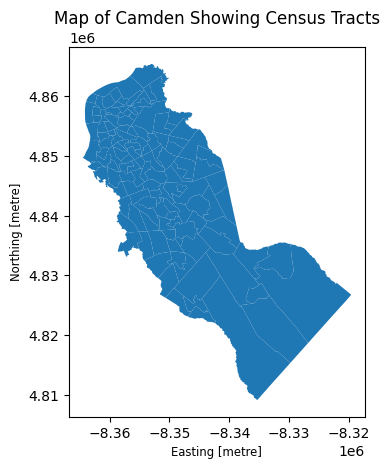

In [2]:
download_url = f'https://drive.google.com/uc?export=download&id=1bYSXS5tARK7u6iUElpCa6FlxboyKJErb'
output_filename = 'Census_Tracts.zip'
gdown.download(download_url, output_filename, quiet=False)

with zipfile.ZipFile(output_filename, 'r') as zip_ref:
    zip_ref.extractall('extracted_files')
wd_map = gpd.read_file('extracted_files/Census_Tracts.shp')

plt.figure(figsize=(15, 15))
wd_map.plot()
plt.title('Map of Camden Showing Census Tracts')
plt.show()

In [3]:
wd_map.columns

Index(['OBJECTID', 'STATEFP10', 'COUNTYFP10', 'TRACTCE10', 'GEOID10', 'NAME10',
       'NAMELSAD10', 'MTFCC10', 'FUNCSTAT10', 'ALAND10', 'AWATER10',
       'INTPTLAT10', 'INTPTLON10', 'geometry'],
      dtype='object')

In [4]:
wd_map = wd_map[wd_map['NAME10'].isin(['6002','6004','6007','6008','6009','6010','6011.01','6011.02','6012','6013','6014','6015','6016','6017','6018','6019','6019','6020','6103','6104'])]


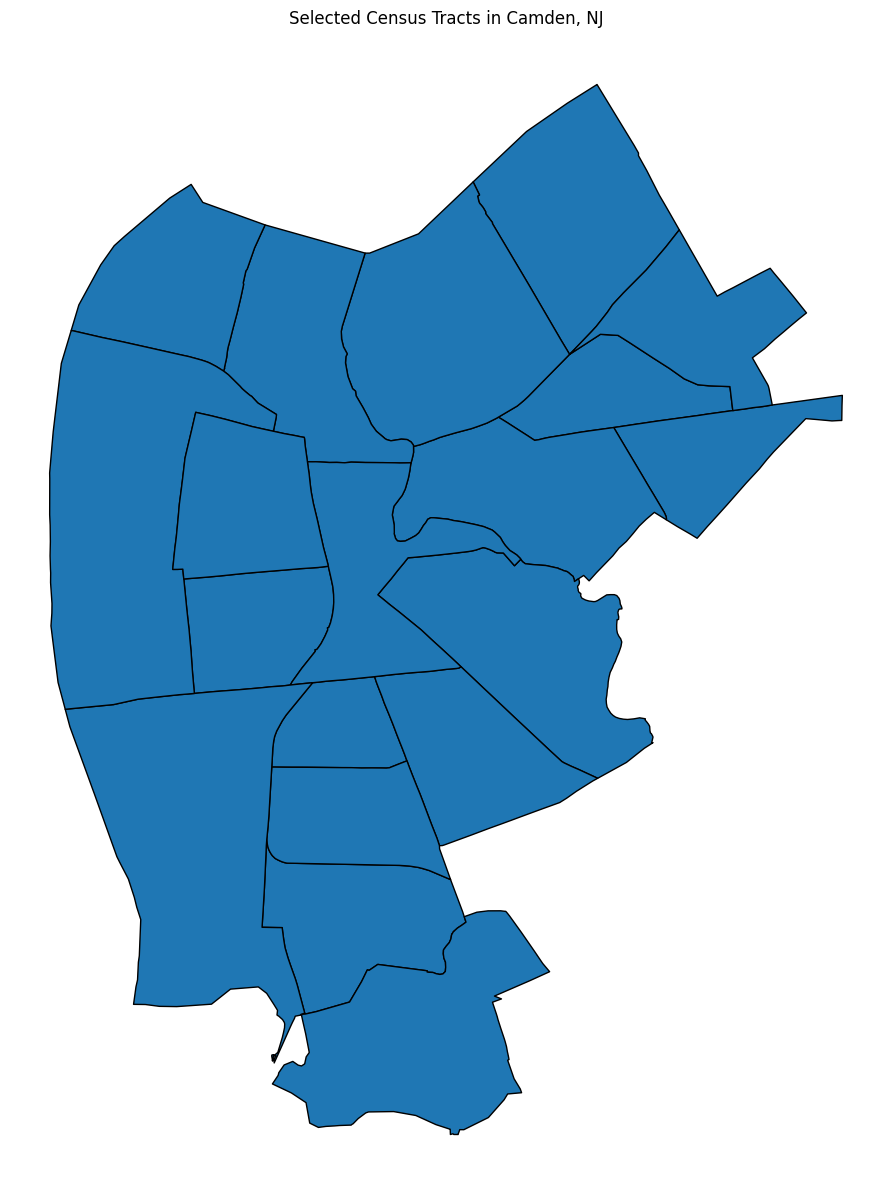

In [5]:
wd_map.plot(figsize=(15, 15), edgecolor='black')
plt.title('Selected Census Tracts in Camden, NJ')
plt.axis('off')
plt.show()


# Importing Datasets

Importing Tract Dataset Worksheet

In [6]:
import pandas as pd

workbook_url = (
    "https://docs.google.com/spreadsheets/d/"
    "10KvIOdXTDkMK0-tzZMelQgvx8t9QSdnt/export?format=xlsx"
)

# View available worksheet names
xls = pd.ExcelFile(workbook_url)
print(xls.sheet_names)

# Load the tract-level master dataset
tract_master = pd.read_excel(workbook_url, sheet_name="TRACT MASTER")
tract_master.head()

['START HERE', 'TRACT MASTER', 'SERVICE MASTER', 'SERVICE SOURCE RECORDS', 'PROVIDER LINKS', 'CANDIDATE ZONES', 'TRACT GEOMETRY', 'MODEL METHOD', 'MODEL PARAMETERS', 'DATA DICTIONARY', 'SOURCES', 'VALIDATION', 'DECISIONS']


,evidence_set,geoid,tractce,tract_name,neighborhood,aland_sq_m,awater_sq_m,internal_latitude,internal_longitude,places_total_population,...,snap_historical_retailer_records,snap_active_retailers_2025_inferred,estimated_snap_households,priority_rank_tiebreak,distance_method,distance_decay_formula,beta_miles,catchment_miles,capacity_assumption,model_version
0,29 included mapped records,34007602000,602000,Census Tract 6020,Fairview Neighborhood,1753786,186127,39.904681,-75.105114,6247,...,33,7,1284,relative underserved need descending; then low...,straight-line haversine proxy,"exp(-(distance_miles/beta_miles)^2), zero beyo...",1,1.5,one equal-capacity proxy unit per included phy...,2.0-research-screening
1,29 included mapped records,34007601200,601200,Census Tract 6012,Stockton Neighborhood,805794,0,39.944511,-75.077870,5691,...,73,14,766,relative underserved need descending; then low...,straight-line haversine proxy,"exp(-(distance_miles/beta_miles)^2), zero beyo...",1,1.5,one equal-capacity proxy unit per included phy...,2.0-research-screening
2,29 included mapped records,34007600700,600700,Census Tract 6007,Cooper Poynt Neighborhood,640048,612486,39.957621,-75.121587,1540,...,8,1,278,relative underserved need descending; then low...,straight-line haversine proxy,"exp(-(distance_miles/beta_miles)^2), zero beyo...",1,1.5,one equal-capacity proxy unit per included phy...,2.0-research-screening
3,29 included mapped records,34007601102,601102,Census Tract 6011.02,Rosedale Neighborhood,1009613,0,39.953379,-75.078808,5111,...,41,5,516,relative underserved need descending; then low...,straight-line haversine proxy,"exp(-(distance_miles/beta_miles)^2), zero beyo...",1,1.5,one equal-capacity proxy unit per included phy...,2.0-research-screening
4,29 included mapped records,34007601900,601900,Census Tract 6019,Morgan Village Neighborhood,1151660,53344,39.913373,-75.109098,2804,...,8,3,422,relative underserved need descending; then low...,straight-line haversine proxy,"exp(-(distance_miles/beta_miles)^2), zero beyo...",1,1.5,one equal-capacity proxy unit per included phy...,2.0-research-screening


In [7]:
# Inspect the tract-level dataset
print("Rows:", tract_master.shape[0])
print("Columns:", tract_master.shape[1])
print("Unique GEOIDs:", tract_master["geoid"].nunique())

#tract_master.head()

Rows: 19
Columns: 83
Unique GEOIDs: 19


In [8]:
tract_master["map_label"] = (
    tract_master["neighborhood"]
    .fillna(tract_master["tract_name"])
    .astype(str)
    .str.strip()
)

In [9]:
key_columns = [
    "geoid",
    "tract_name",
    "neighborhood",
    "map_label",

    # Food-assistance need
    "places_population_18_plus",
    "places_food_insecurity_pct",
    "estimated_food_insecure_adults",

    # Known-service access
    "services_in_tract",
    "services_within_1mi",
    "nearest_service_miles",
    "e2sfca_access_per_1000_need",
    "relative_access_ratio",
    "relative_access_shortfall_fraction",

    # Modeled priority
    "relative_underserved_need_units",
    "research_priority_index",
    "research_priority_rank"
]

tract_master[key_columns].head()

,geoid,tract_name,neighborhood,map_label,places_population_18_plus,places_food_insecurity_pct,estimated_food_insecure_adults,services_in_tract,services_within_1mi,nearest_service_miles,e2sfca_access_per_1000_need,relative_access_ratio,relative_access_shortfall_fraction,relative_underserved_need_units,research_priority_index,research_priority_rank
0,34007602000,Census Tract 6020,Fairview Neighborhood,Fairview Neighborhood,4323,37.1,1603.8,0,0,1.1998,0.147184,0.110694,0.889306,1426.269196,100.0,1
1,34007601200,Census Tract 6012,Stockton Neighborhood,Stockton Neighborhood,4093,43.2,1768.2,0,6,0.3493,0.856586,0.644221,0.355779,629.088257,94.7,2
2,34007600700,Census Tract 6007,Cooper Poynt Neighborhood,Cooper Poynt Neighborhood,1091,54.1,590.2,0,3,0.6725,0.550367,0.413920,0.586080,345.904210,89.5,3
3,34007601102,Census Tract 6011.02,Rosedale Neighborhood,Rosedale Neighborhood,3653,42.4,1548.9,0,7,0.3569,1.045041,0.785954,0.214046,331.535123,84.2,4
4,34007601900,Census Tract 6019,Morgan Village Neighborhood,Morgan Village Neighborhood,1826,45.1,823.5,0,5,0.5655,0.801120,0.602507,0.397493,327.335824,78.9,5


Importing Service Master Dataset

In [10]:
services = pd.read_excel(
    workbook_url,
    sheet_name="SERVICE MASTER",
    dtype={"assigned_geoid": str}
)

print("Service records:", len(services))
print("\nAvailable columns:")
print(services.columns.tolist())

Service records: 29

Available columns:
['included_in_29_record_model', 'service_location_id', 'address_key', 'primary_name', 'organization_names', 'service_types', 'street_address', 'city', 'state', 'zip_code', 'full_address', 'phone', 'schedule_summary', 'source_names', 'source_record_count', 'confidence_tier', 'verification_status', 'inactive_source_flag', 'latitude', 'longitude', 'matched_address', 'geocode_status', 'assigned_geoid', 'capacity_units_per_period', 'capacity_period', 'capacity_data_status', 'model_capacity_proxy', 'routing_time_status', 'model_version']


In [11]:
services.head(3).T

,0,1,2
included_in_29_record_model,True,True,True
service_location_id,LOC-001,LOC-002,LOC-005
address_key,1035 n 27th st,1036 broadway,114 boyd st
primary_name,Evangelistic Mennonite Church,Shalom Baptist Church,"Love Ministries Outreach International, Inc. P..."
organization_names,Evangelistic Mennonite Church,Shalom Baptist Church,"Love Ministries Outreach International, Inc. P..."
service_types,Food pantry,Food pantry,Food pantry
street_address,1035 North 27th Street,1036 Broadway,114 Boyd Street
city,Camden,Camden,Camden
state,NJ,NJ,NJ
zip_code,8105,8103,8105


In [12]:
service_detail_columns = [
    column for column in services.columns
    if any(
        term in column.lower()
        for term in [
            "name", "organization", "address", "phone",
            "hour", "schedule", "service", "type",
            "latitude", "longitude", "website",
            "status", "source"
        ]
    )
]

service_detail_columns

['service_location_id',
 'address_key',
 'primary_name',
 'organization_names',
 'service_types',
 'street_address',
 'full_address',
 'phone',
 'schedule_summary',
 'source_names',
 'source_record_count',
 'verification_status',
 'inactive_source_flag',
 'latitude',
 'longitude',
 'matched_address',
 'geocode_status',
 'capacity_data_status',
 'routing_time_status']

In [13]:
service_completeness = pd.DataFrame({
    "non_missing": services[service_detail_columns].notna().sum(),
    "missing": services[service_detail_columns].isna().sum()
})

service_completeness.head(3)

,non_missing,missing
service_location_id,29,0
address_key,29,0
primary_name,29,0


Importing Geometry Worksheet

In [14]:
import json
from shapely.geometry import shape

tract_geometry = pd.read_excel(
    workbook_url,
    sheet_name="TRACT GEOMETRY",
    dtype={"geoid": str}
)

tract_geometry.head(1)

,geoid,tract_name,geometry_type,geometry_geojson,crs,source
0,34007600200,Census Tract 6002,Polygon,"{""type"":""Polygon"",""coordinates"":[[[-75.1151,39...",EPSG:4326,Camden tract geometry supplied with the projec...


In [15]:
tract_geometry["geometry"] = tract_geometry["geometry_geojson"].apply(
    lambda value: shape(json.loads(value))
)

tract_geometry_gdf = gpd.GeoDataFrame(
    tract_geometry,
    geometry="geometry",
    crs="EPSG:4326"
)

In [16]:
tract_master["geoid"] = tract_master["geoid"].astype(str).str.replace(
    r"\.0$", "", regex=True
)

tract_geometry_gdf["geoid"] = (
    tract_geometry_gdf["geoid"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
)

Joining Data to Map

In [17]:
camden_gdf = tract_geometry_gdf[
    ["geoid", "geometry"]
].merge(
    tract_master,
    on="geoid",
    how="left",
    validate="one_to_one"
)

camden_gdf = gpd.GeoDataFrame(
    camden_gdf,
    geometry="geometry",
    crs="EPSG:4326"
)

In [18]:
print("Mapped tracts:", len(camden_gdf))
print("Unique GEOIDs:", camden_gdf["geoid"].nunique())
print("Missing food-insecurity values:", camden_gdf["places_food_insecurity_pct"].isna().sum())
print("Missing geometry:", camden_gdf.geometry.isna().sum())

Mapped tracts: 19
Unique GEOIDs: 19
Missing food-insecurity values: 0
Missing geometry: 0



# Data Analysis

Data Structure

In [19]:
print("Dataset shape:", tract_master.shape)
print("Number of tracts:", len(tract_master))
print("Unique GEOIDs:", tract_master["geoid"].nunique())
print("Duplicate GEOIDs:", tract_master["geoid"].duplicated().sum())

Dataset shape: (19, 84)
Number of tracts: 19
Unique GEOIDs: 19
Duplicate GEOIDs: 0


Analytical Variables

In [20]:
need_variables = [
    "places_population_18_plus",
    "places_food_insecurity_pct",
    "estimated_food_insecure_adults"
]

access_variables = [
    "services_in_tract",
    "services_within_0_5mi",
    "services_within_1mi",
    "services_within_1_5mi",
    "nearest_service_miles",
    "e2sfca_access_per_1000_need",
    "relative_access_ratio",
    "relative_access_shortfall_fraction"
]

priority_variables = [
    "relative_underserved_need_units",
    "research_priority_index",
    "research_priority_rank"
]

outreach_variables = [
    "acs_no_vehicle_households_pct",
    "acs_snap_households_with_children_est",
    "acs_snap_households_with_senior_est",
    "places_disability_pct",
    "acs_limited_english_pct",
    "acs_broadband_subscription_pct"
]

Check Missing Data

In [21]:
analysis_variables = (
    need_variables
    + access_variables
    + priority_variables
    + outreach_variables
)

missing_summary = (
    tract_master[analysis_variables]
    .isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("missing_values")
)

missing_summary["missing_percent"] = (
    missing_summary["missing_values"] / len(tract_master) * 100
)

missing_summary

,missing_values,missing_percent
places_population_18_plus,0,0.0
places_food_insecurity_pct,0,0.0
estimated_food_insecure_adults,0,0.0
services_in_tract,0,0.0
services_within_0_5mi,0,0.0
services_within_1mi,0,0.0
services_within_1_5mi,0,0.0
nearest_service_miles,0,0.0
e2sfca_access_per_1000_need,0,0.0
relative_access_ratio,0,0.0


Descriptive Analysis

In [22]:
tract_master[
    need_variables + access_variables + priority_variables
].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
places_population_18_plus,19.0,2686.79,1112.90,810.00,1840.00,2687.00,3693.00,4323.00
places_food_insecurity_pct,19.0,45.64,8.46,29.10,40.90,43.20,51.35,59.70
estimated_food_insecure_adults,19.0,1200.09,469.49,332.10,784.60,1373.20,1586.50,1788.40
services_in_tract,19.0,1.53,1.22,0.00,0.50,2.00,2.00,4.00
services_within_0_5mi,19.0,2.74,1.88,0.00,1.50,3.00,4.00,7.00
services_within_1mi,19.0,8.53,4.10,0.00,6.50,8.00,10.50,17.00
services_within_1_5mi,19.0,15.26,5.22,4.00,12.00,14.00,19.00,25.00
nearest_service_miles,19.0,0.31,0.27,0.06,0.14,0.21,0.37,1.20
e2sfca_access_per_1000_need,19.0,1.29,0.52,0.15,0.96,1.33,1.51,2.13
relative_access_ratio,19.0,0.97,0.39,0.11,0.72,1.00,1.13,1.60


Validating Food Insecurity Calculations

In [23]:
tract_master["recalculated_food_insecure_adults"] = (
    tract_master["places_population_18_plus"]
    * tract_master["places_food_insecurity_pct"]
    / 100
)

tract_master["food_insecure_count_difference"] = (
    tract_master["estimated_food_insecure_adults"]
    - tract_master["recalculated_food_insecure_adults"]
)

tract_master[
    [
        "tract_name",
        "places_population_18_plus",
        "places_food_insecurity_pct",
        "estimated_food_insecure_adults",
        "recalculated_food_insecure_adults",
        "food_insecure_count_difference"
    ]
].head()

,tract_name,places_population_18_plus,places_food_insecurity_pct,estimated_food_insecure_adults,recalculated_food_insecure_adults,food_insecure_count_difference
0,Census Tract 6020,4323,37.1,1603.8,1603.833,-0.033
1,Census Tract 6012,4093,43.2,1768.2,1768.176,0.024
2,Census Tract 6007,1091,54.1,590.2,590.231,-0.031
3,Census Tract 6011.02,3653,42.4,1548.9,1548.872,0.028
4,Census Tract 6019,1826,45.1,823.5,823.526,-0.026


Analyzing Need - Which tracts have the greatest estimated prevalence of adult food insecurity?

In [24]:
need_table = tract_master[
    [
        "geoid","neighborhood",
        "tract_name",
        "places_population_18_plus",
        "places_food_insecurity_pct",
        "estimated_food_insecure_adults"
    ]
].sort_values(
    "places_food_insecurity_pct",
    ascending=False
)

need_table.head(10)

,geoid,neighborhood,tract_name,places_population_18_plus,places_food_insecurity_pct,estimated_food_insecure_adults
18,34007600400,Bergen Square Neighborhood,Census Tract 6004,2095,59.7,1250.7
13,34007601700,Centerville Neighborhood,Census Tract 6017,1854,59.5,1103.1
10,34007600900,Cramer Hill Neighborhood,Census Tract 6009,2687,58.4,1569.2
2,34007600700,Cooper Poynt Neighborhood,Census Tract 6007,1091,54.1,590.2
16,34007601600,Liberty Park Neighborhood,Census Tract 6016,1448,51.5,745.7
6,34007600800,Pyne Point Neighborhood,Census Tract 6008,3493,51.2,1788.4
9,34007601400,Parkside Neighborhood,Census Tract 6014,2994,50.6,1515.0
4,34007601900,Morgan Village Neighborhood,Census Tract 6019,1826,45.1,823.5
14,34007601300,Marlton Neighborhood,Census Tract 6013,3733,44.0,1642.5
1,34007601200,Stockton Neighborhood,Census Tract 6012,4093,43.2,1768.2


In [25]:
need_table.sort_values("estimated_food_insecure_adults", ascending=False).head(10)

,geoid,neighborhood,tract_name,places_population_18_plus,places_food_insecurity_pct,estimated_food_insecure_adults
6,34007600800,Pyne Point Neighborhood,Census Tract 6008,3493,51.2,1788.4
1,34007601200,Stockton Neighborhood,Census Tract 6012,4093,43.2,1768.2
11,34007601500,Whitman Park Neighborhood,Census Tract 6015,3870,43.0,1664.1
14,34007601300,Marlton Neighborhood,Census Tract 6013,3733,44.0,1642.5
0,34007602000,Fairview Neighborhood,Census Tract 6020,4323,37.1,1603.8
10,34007600900,Cramer Hill Neighborhood,Census Tract 6009,2687,58.4,1569.2
3,34007601102,Rosedale Neighborhood,Census Tract 6011.02,3653,42.4,1548.9
9,34007601400,Parkside Neighborhood,Census Tract 6014,2994,50.6,1515.0
15,34007610400,Lanning Square Neighborhood,Census Tract 6104,3416,40.8,1393.7
5,34007601000,Beideman Neighborhood,Census Tract 6010,3825,35.9,1373.2


Analyzing Access

In [26]:
access_table = tract_master[
    [
        "geoid",
        "tract_name",
        "services_in_tract",
        "services_within_1mi",
        "nearest_service_miles",
        "e2sfca_access_per_1000_need",
        "relative_access_ratio",
        "relative_access_shortfall_fraction"
    ]
].sort_values(
    "relative_access_ratio",
    ascending=True
)

access_table.head(10)

,geoid,tract_name,services_in_tract,services_within_1mi,nearest_service_miles,e2sfca_access_per_1000_need,relative_access_ratio,relative_access_shortfall_fraction
0,34007602000,Census Tract 6020,0,0,1.1998,0.147184,0.110694,0.889306
2,34007600700,Census Tract 6007,0,3,0.6725,0.550367,0.413920,0.586080
4,34007601900,Census Tract 6019,0,5,0.5655,0.801120,0.602507,0.397493
1,34007601200,Census Tract 6012,0,6,0.3493,0.856586,0.644221,0.355779
7,34007601800,Census Tract 6018,1,5,0.4008,0.880707,0.662362,0.337638
3,34007601102,Census Tract 6011.02,0,7,0.3569,1.045041,0.785954,0.214046
5,34007601000,Census Tract 6010,2,8,0.1929,1.051980,0.791173,0.208827
6,34007600800,Census Tract 6008,1,7,0.1016,1.215937,0.914482,0.085518
8,34007610300,Census Tract 6103,1,7,0.3777,1.234032,0.928091,0.071909
9,34007601400,Census Tract 6014,2,10,0.2649,1.329646,1.000000,0.000000


Interpretation:
- Lower relative_access_ratio means weaker modeled access relative to the Camden tract median.
- Higher relative_access_shortfall_fraction means a larger relative access shortfall.
- These are modeled comparisons based on the 29 known locations.

Analyzing Final Modeled Priority

In [27]:
priority_table = tract_master[
    [
        "geoid",
        "tract_name",
        "places_food_insecurity_pct",
        "estimated_food_insecure_adults",
        "relative_access_ratio",
        "relative_access_shortfall_fraction",
        "relative_underserved_need_units",
        "research_priority_index",
        "research_priority_rank"
    ]
].sort_values(
    "research_priority_rank"
)

priority_table.head(10)

,geoid,tract_name,places_food_insecurity_pct,estimated_food_insecure_adults,relative_access_ratio,relative_access_shortfall_fraction,relative_underserved_need_units,research_priority_index,research_priority_rank
0,34007602000,Census Tract 6020,37.1,1603.8,0.110694,0.889306,1426.269196,100.0,1
1,34007601200,Census Tract 6012,43.2,1768.2,0.644221,0.355779,629.088257,94.7,2
2,34007600700,Census Tract 6007,54.1,590.2,0.413920,0.586080,345.904210,89.5,3
3,34007601102,Census Tract 6011.02,42.4,1548.9,0.785954,0.214046,331.535123,84.2,4
4,34007601900,Census Tract 6019,45.1,823.5,0.602507,0.397493,327.335824,78.9,5
5,34007601000,Census Tract 6010,35.9,1373.2,0.791173,0.208827,286.761612,73.7,6
6,34007600800,Census Tract 6008,51.2,1788.4,0.914482,0.085518,152.940454,68.4,7
7,34007601800,Census Tract 6018,41.0,332.1,0.662362,0.337638,112.129613,63.2,8
8,34007610300,Census Tract 6103,29.1,713.2,0.928091,0.071909,51.285492,57.9,9
9,34007601400,Census Tract 6014,50.6,1515.0,1.000000,0.000000,0.000000,28.9,10


In [28]:
comparison_table = tract_master[
    [
        "neighborhood",
        "tract_name",
        "places_food_insecurity_pct",
        "estimated_food_insecure_adults",
        "services_in_tract",
        "services_within_1mi",
        "nearest_service_miles",
        "relative_access_ratio",
        "relative_access_shortfall_fraction",
        "research_priority_index",
        "research_priority_rank"
    ]
].sort_values("research_priority_rank")

comparison_table

,neighborhood,tract_name,places_food_insecurity_pct,estimated_food_insecure_adults,services_in_tract,services_within_1mi,nearest_service_miles,relative_access_ratio,relative_access_shortfall_fraction,research_priority_index,research_priority_rank
0,Fairview Neighborhood,Census Tract 6020,37.1,1603.8,0,0,1.1998,0.110694,0.889306,100.0,1
1,Stockton Neighborhood,Census Tract 6012,43.2,1768.2,0,6,0.3493,0.644221,0.355779,94.7,2
2,Cooper Poynt Neighborhood,Census Tract 6007,54.1,590.2,0,3,0.6725,0.413920,0.586080,89.5,3
3,Rosedale Neighborhood,Census Tract 6011.02,42.4,1548.9,0,7,0.3569,0.785954,0.214046,84.2,4
4,Morgan Village Neighborhood,Census Tract 6019,45.1,823.5,0,5,0.5655,0.602507,0.397493,78.9,5
5,Beideman Neighborhood,Census Tract 6010,35.9,1373.2,2,8,0.1929,0.791173,0.208827,73.7,6
6,Pyne Point Neighborhood,Census Tract 6008,51.2,1788.4,1,7,0.1016,0.914482,0.085518,68.4,7
7,Waterfront South Neighborhood,Census Tract 6018,41.0,332.1,1,5,0.4008,0.662362,0.337638,63.2,8
8,Cooper Grant Neighborhood,Census Tract 6103,29.1,713.2,1,7,0.3777,0.928091,0.071909,57.9,9
9,Parkside Neighborhood,Census Tract 6014,50.6,1515.0,2,10,0.2649,1.000000,0.000000,28.9,10


# Mapping

In [29]:
import pandas as pd
import geopandas as gpd
import folium
import json

from shapely.geometry import shape
from branca.colormap import linear
from IPython.display import display

Prepare the tract geometry

In [30]:
# Load the tract geometry from the workbook
tract_geometry = pd.read_excel(
    workbook_url,
    sheet_name="TRACT GEOMETRY",
    dtype={"geoid": str}
)

# Standardize GEOIDs
tract_master["geoid"] = (
    tract_master["geoid"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(11)
)

tract_geometry["geoid"] = (
    tract_geometry["geoid"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(11)
)

# Convert the stored GeoJSON text into geometry
def parse_geometry(value):
    if isinstance(value, dict):
        return shape(value)
    return shape(json.loads(value))

tract_geometry["geometry"] = tract_geometry[
    "geometry_geojson"
].apply(parse_geometry)

tract_geometry_gdf = gpd.GeoDataFrame(
    tract_geometry,
    geometry="geometry",
    crs="EPSG:4326"
)

Join the tract evidence to the geography

In [31]:
camden_gdf = tract_geometry_gdf[
    ["geoid", "geometry"]
].merge(
    tract_master,
    on="geoid",
    how="left",
    validate="one_to_one"
)

camden_gdf = gpd.GeoDataFrame(
    camden_gdf,
    geometry="geometry",
    crs="EPSG:4326"
)

# Use neighborhood as the primary public-facing label
camden_gdf["map_label"] = (
    camden_gdf["neighborhood"]
    .fillna(camden_gdf["tract_name"])
    .astype(str)
    .str.strip()
)

In [32]:
print("Mapped tracts:", len(camden_gdf))
print("Unique GEOIDs:", camden_gdf["geoid"].nunique())
print("Missing geometry:", camden_gdf.geometry.isna().sum())
print(
    "Missing food-insecurity prevalence:",
    camden_gdf["places_food_insecurity_pct"].isna().sum()
)
print(
    "Missing neighborhood names:",
    camden_gdf["neighborhood"].isna().sum()
)

Mapped tracts: 19
Unique GEOIDs: 19
Missing geometry: 0
Missing food-insecurity prevalence: 0
Missing neighborhood names: 0


Review the variable before mapping

In [33]:
camden_gdf[
    [
        "map_label",
        "tract_name",
        "places_population_18_plus",
        "places_food_insecurity_pct",
        "places_food_insecurity_ci95",
        "estimated_food_insecure_adults"
    ]
].sort_values(
    "places_food_insecurity_pct",
    ascending=False
)

,map_label,tract_name,places_population_18_plus,places_food_insecurity_pct,places_food_insecurity_ci95,estimated_food_insecure_adults
3,Bergen Square Neighborhood,Census Tract 6004,2095,59.7,"(53.7, 65.1)",1250.7
7,Centerville Neighborhood,Census Tract 6017,1854,59.5,"(54.2, 64.6)",1103.1
14,Cramer Hill Neighborhood,Census Tract 6009,2687,58.4,"(52.3, 64.1)",1569.2
4,Cooper Poynt Neighborhood,Census Tract 6007,1091,54.1,"(48.4, 59.7)",590.2
16,Liberty Park Neighborhood,Census Tract 6016,1448,51.5,"(46.0, 57.1)",745.7
5,Pyne Point Neighborhood,Census Tract 6008,3493,51.2,"(46.0, 56.6)",1788.4
11,Parkside Neighborhood,Census Tract 6014,2994,50.6,"(44.9, 56.4)",1515.0
9,Morgan Village Neighborhood,Census Tract 6019,1826,45.1,"(39.3, 50.6)",823.5
10,Marlton Neighborhood,Census Tract 6013,3733,44.0,"(38.9, 49.4)",1642.5
6,Stockton Neighborhood,Census Tract 6012,4093,43.2,"(37.7, 48.7)",1768.2


In [34]:
camden_gdf["places_food_insecurity_pct"].describe().round(2)

,places_food_insecurity_pct
count,19.00
mean,45.64
std,8.46
min,29.10
25%,40.90
50%,43.20
75%,51.35
max,59.70


Map: Percentage of Food Insecurity

Where is food insecurity proportionally highest?

In [35]:
# Variable being mapped
map_variable = "places_food_insecurity_pct"

minimum_value = float(camden_gdf[map_variable].min())
maximum_value = float(camden_gdf[map_variable].max())

# Sequential color scale: lighter = lower prevalence, darker = higher
food_insecurity_colors = linear.OrRd_09.scale(
    minimum_value,
    maximum_value
)

food_insecurity_colors.caption = (
    "Estimated adult food-insecurity prevalence (%)"
)

# Calculate the map center from Camden's geographic bounds
min_longitude, min_latitude, max_longitude, max_latitude = (
    camden_gdf.total_bounds
)

map_center = [
    (min_latitude + max_latitude) / 2,
    (min_longitude + max_longitude) / 2
]

food_insecurity_map = folium.Map(
    location=map_center,
    zoom_start=13,
    tiles=None,
    control_scale=True
)

folium.TileLayer(
    tiles=(
        "https://server.arcgisonline.com/ArcGIS/rest/services/"
        "Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}"
    ),
    attr="Tiles © Esri",
    name="Light gray basemap",
    overlay=False,
    control=True,
    show=True,
    max_zoom=16
).add_to(food_insecurity_map)

In [36]:
# Keep only fields needed by this map
map_fields = [
    "geoid",
    "tract_name",
    "neighborhood",
    "map_label",
    "places_population_18_plus",
    "places_food_insecurity_pct",
    "places_food_insecurity_ci95",
    "estimated_food_insecure_adults",
    "geometry"
]

food_insecurity_gdf = camden_gdf[map_fields].copy()

# Make sure numerical fields are treated as numbers
food_insecurity_gdf["places_food_insecurity_pct"] = pd.to_numeric(
    food_insecurity_gdf["places_food_insecurity_pct"],
    errors="coerce"
)

food_insecurity_gdf["places_population_18_plus"] = pd.to_numeric(
    food_insecurity_gdf["places_population_18_plus"],
    errors="coerce"
)

food_insecurity_gdf["food_insecurity_display"] = (
    food_insecurity_gdf["places_food_insecurity_pct"]
    .map(lambda value: f"{value:.1f}%")
)

food_insecurity_gdf["estimated_adults_display"] = (
    food_insecurity_gdf["estimated_food_insecure_adults"]
    .map(lambda value: f"{value:,.0f}")
)

food_insecurity_gdf["estimated_food_insecure_adults"] = pd.to_numeric(
    food_insecurity_gdf["estimated_food_insecure_adults"],
    errors="coerce"
)

# Convert the GeoDataFrame to GeoJSON
food_insecurity_geojson = json.loads(
    food_insecurity_gdf.to_json(
        na="null",
        drop_id=True
    )
)

In [37]:
def food_insecurity_style(feature):
    value = feature["properties"].get(
        "places_food_insecurity_pct"
    )

    if value is None:
        fill_color = "#D3D3D3"
    else:
        fill_color = food_insecurity_colors(value)

    return {
        "fillColor": fill_color,
        "color": "#4A4A4A",
        "weight": 1,
        "fillOpacity": 0.72
    }


def tract_highlight_style(feature):
    return {
        "color": "#111111",
        "weight": 3,
        "fillOpacity": 0.85
    }

In [38]:
food_insecurity_layer = folium.GeoJson(
    data=food_insecurity_geojson,
    name="Adult food-insecurity prevalence",
    style_function=food_insecurity_style,
    highlight_function=tract_highlight_style,
    tooltip=folium.GeoJsonTooltip(
        fields=[
            "map_label","tract_name",
            "places_food_insecurity_pct",
            "estimated_food_insecure_adults"
        ],
        aliases=[
            "Neighborhood:","Census Tract:",
            "Adult food-insecurity prevalence:",
            "Derived estimated food-insecure adults:"
        ],
        localize=True,
        sticky=False,
        labels=True
    ),
    popup=folium.GeoJsonPopup(
        fields=[
            "map_label",
            "tract_name",
            "geoid",
            "places_population_18_plus",
            "places_food_insecurity_pct",
            "places_food_insecurity_ci95",
            "estimated_food_insecure_adults"
        ],
        aliases=[
            "Neighborhood:",
            "Census tract:",
            "GEOID:",
            "Adult population age 18+:",
            "Food-insecurity prevalence (%):",
            "95% confidence interval:",
            "Derived estimated food-insecure adults:"
        ],
        localize=True,
        labels=True,
        style=(
            "background-color: white; "
            "color: #222222; "
            "font-family: Arial; "
            "font-size: 13px; "
            "padding: 10px;"
        )
    )
)

food_insecurity_layer.add_to(food_insecurity_map)
food_insecurity_colors.add_to(food_insecurity_map)

In [39]:
tooltip=folium.GeoJsonTooltip(
    fields=[
        "map_label",
        "tract_name",
        "food_insecurity_display",
        "estimated_adults_display"
    ],
    aliases=[
        "Neighborhood:",
        "Census tract:",
        "Adult food-insecurity prevalence:",
        "Derived estimated food-insecure adults:"
    ],
    sticky=False,
    labels=True
)

In [40]:
map_title = """
<div style="
    position: fixed;
    top: 10px;
    left: 50px;
    width: 440px;
    z-index: 9999;
    background-color: rgba(255,255,255,0.95);
    border: 1px solid #777;
    border-radius: 5px;
    padding: 10px;
    font-family: Arial;
">
    <div style="font-size: 17px; font-weight: bold;">
        Estimated Adult Food-Insecurity Prevalence
    </div>

    <div style="font-size: 13px; margin-top: 4px;">
        Camden neighborhoods shown using census-tract evidence
    </div>

    <div style="font-size: 11px; margin-top: 6px; color: #555;">
        Darker areas have a higher modeled percentage of adults
        experiencing food insecurity. Click a tract for its complete
        profile. The derived adult count is not an observed client count.
    </div>
</div>
"""

food_insecurity_map.get_root().html.add_child(
    folium.Element(map_title)
)

folium.LayerControl(collapsed=False).add_to(
    food_insecurity_map
)

food_insecurity_map.fit_bounds(
    [
        [min_latitude, min_longitude],
        [max_latitude, max_longitude]
    ]
)

In [41]:
food_insecurity_map

Map: Derived estimated number of food-insecure adults

Where the estimated number of affected adults may be largest.

In [42]:

from branca.colormap import linear


# ------------------------------------------------------------
# 1. Prepare the map data
# ------------------------------------------------------------

estimated_adults_gdf = camden_gdf[
    [
        "geoid",
        "tract_name",
        "neighborhood",
        "map_label",
        "places_population_18_plus",
        "places_food_insecurity_pct",
        "places_food_insecurity_ci95",
        "estimated_food_insecure_adults",
        "geometry"
    ]
].copy()

numeric_columns = [
    "places_population_18_plus",
    "places_food_insecurity_pct",
    "estimated_food_insecure_adults"
]

for column in numeric_columns:
    estimated_adults_gdf[column] = pd.to_numeric(
        estimated_adults_gdf[column],
        errors="coerce"
    )


# Display-only fields; underlying numerical fields remain unchanged
estimated_adults_gdf["adult_population_display"] = (
    estimated_adults_gdf["places_population_18_plus"]
    .map(
        lambda value:
        f"{value:,.0f}" if pd.notna(value) else "Not available"
    )
)

estimated_adults_gdf["prevalence_display"] = (
    estimated_adults_gdf["places_food_insecurity_pct"]
    .map(
        lambda value:
        f"{value:.1f}%" if pd.notna(value) else "Not available"
    )
)

estimated_adults_gdf["estimated_adults_display"] = (
    estimated_adults_gdf["estimated_food_insecure_adults"]
    .map(
        lambda value:
        f"{value:,.0f}" if pd.notna(value) else "Not available"
    )
)


# ------------------------------------------------------------
# 2. Establish the color scale and map center
# ------------------------------------------------------------

map_variable = "estimated_food_insecure_adults"

minimum_value = float(
    estimated_adults_gdf[map_variable].min()
)

maximum_value = float(
    estimated_adults_gdf[map_variable].max()
)

estimated_adults_colors = linear.YlOrRd_09.scale(
    minimum_value,
    maximum_value
)

estimated_adults_colors.caption = (
    "Derived estimated number of food-insecure adults"
)

min_longitude, min_latitude, max_longitude, max_latitude = (
    estimated_adults_gdf.total_bounds
)

map_center = [
    (min_latitude + max_latitude) / 2,
    (min_longitude + max_longitude) / 2
]


# ------------------------------------------------------------
# 3. Create the interactive map and basemap
# ------------------------------------------------------------

estimated_adults_map = folium.Map(
    location=map_center,
    zoom_start=13,
    tiles=None,
    control_scale=True
)

folium.TileLayer(
    tiles=(
        "https://server.arcgisonline.com/ArcGIS/rest/services/"
        "Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}"
    ),
    attr="Tiles © Esri",
    name="Light gray basemap",
    overlay=False,
    control=True,
    show=True,
    max_zoom=16
).add_to(estimated_adults_map)


# ------------------------------------------------------------
# 4. Define the map styling functions
# ------------------------------------------------------------

def estimated_adults_style(feature):
    value = feature["properties"].get(
        "estimated_food_insecure_adults"
    )

    if value is None:
        fill_color = "#D3D3D3"
    else:
        fill_color = estimated_adults_colors(value)

    return {
        "fillColor": fill_color,
        "color": "#4A4A4A",
        "weight": 1,
        "fillOpacity": 0.72
    }


def estimated_adults_highlight(feature):
    return {
        "color": "#111111",
        "weight": 3,
        "fillOpacity": 0.88
    }


# ------------------------------------------------------------
# 5. Convert the map data to GeoJSON
# ------------------------------------------------------------

estimated_adults_geojson = json.loads(
    estimated_adults_gdf.to_json(
        na="null",
        drop_id=True
    )
)


# ------------------------------------------------------------
# 6. Add the interactive neighborhood/tract layer
# ------------------------------------------------------------

estimated_adults_layer = folium.GeoJson(
    data=estimated_adults_geojson,
    name="Derived estimated food-insecure adults",
    style_function=estimated_adults_style,
    highlight_function=estimated_adults_highlight,

    tooltip=folium.GeoJsonTooltip(
        fields=[
            "map_label",
            "tract_name",
            "estimated_adults_display",
            "prevalence_display"
        ],
        aliases=[
            "Neighborhood:",
            "Census tract:",
            "Derived estimated food-insecure adults:",
            "Adult food-insecurity prevalence:"
        ],
        localize=True,
        sticky=False,
        labels=True
    ),

    popup=folium.GeoJsonPopup(
        fields=[
            "map_label",
            "tract_name",
            "geoid",
            "adult_population_display",
            "prevalence_display",
            "places_food_insecurity_ci95",
            "estimated_adults_display"
        ],
        aliases=[
            "Neighborhood:",
            "Census tract:",
            "GEOID:",
            "Adult population age 18+:",
            "Food-insecurity prevalence:",
            "95% confidence interval:",
            "Derived estimated food-insecure adults:"
        ],
        localize=True,
        labels=True,
        style=(
            "background-color: white; "
            "color: #222222; "
            "font-family: Arial; "
            "font-size: 13px; "
            "padding: 10px;"
        )
    )
)

estimated_adults_layer.add_to(estimated_adults_map)
estimated_adults_colors.add_to(estimated_adults_map)


# ------------------------------------------------------------
# 7. Add the title and interpretation note
# ------------------------------------------------------------

map_title = """
<div style="
    position: fixed;
    top: 10px;
    left: 75px;
    width: 470px;
    z-index: 9999;
    background-color: rgba(255,255,255,0.95);
    border: 1px solid #777;
    border-radius: 5px;
    padding: 10px;
    font-family: Arial;
">
    <div style="font-size: 17px; font-weight: bold;">
        Derived Estimate of Food-Insecure Adults
    </div>

    <div style="font-size: 13px; margin-top: 4px;">
        Camden neighborhoods shown using census-tract evidence
    </div>

    <div style="font-size: 11px; margin-top: 6px; color: #555;">
        Darker areas have a larger derived number of adults estimated
        to experience food insecurity. The estimate equals the adult
        population multiplied by food-insecurity prevalence. It is not
        an observed client count or a direct measure of unmet demand.
    </div>
</div>
"""

estimated_adults_map.get_root().html.add_child(
    folium.Element(map_title)
)


# ------------------------------------------------------------
# 8. Add controls, fit the map, and display it
# ------------------------------------------------------------

folium.LayerControl(
    collapsed=False
).add_to(estimated_adults_map)

estimated_adults_map.fit_bounds(
    [
        [min_latitude, min_longitude],
        [max_latitude, max_longitude]
    ]
)

estimated_adults_map

Map: Estimated SNAP Households

- Estimated SNAP households with children
- Estimated SNAP households with one or more people age 60 or older

In [43]:
# ============================================================
# MAP 3 — SNAP HOUSEHOLDS WITH CHILDREN OR SENIORS
# Primary map measure: percentage of all tract households
# ============================================================

import pandas as pd
import numpy as np
import folium
import json

from branca.colormap import linear


# ------------------------------------------------------------
# Prepare data
# ------------------------------------------------------------

snap_households_gdf = camden_gdf[
    [
        "geoid",
        "tract_name",
        "neighborhood",
        "map_label",
        "acs_total_households_est",
        "acs_snap_households_est",
        "acs_snap_households_pct",
        "acs_snap_households_with_children_est",
        "acs_snap_households_with_senior_est",
        "geometry"
    ]
].copy()

numeric_columns = [
    "acs_total_households_est",
    "acs_snap_households_est",
    "acs_snap_households_pct",
    "acs_snap_households_with_children_est",
    "acs_snap_households_with_senior_est"
]

for column in numeric_columns:
    snap_households_gdf[column] = pd.to_numeric(
        snap_households_gdf[column],
        errors="coerce"
    )


# ------------------------------------------------------------
# Calculate percentages
# ------------------------------------------------------------

# Main map measures: percentage of all tract households
snap_households_gdf["snap_children_pct_all_households"] = np.where(
    snap_households_gdf["acs_total_households_est"] > 0,
    (
        snap_households_gdf[
            "acs_snap_households_with_children_est"
        ]
        / snap_households_gdf["acs_total_households_est"]
        * 100
    ),
    np.nan
)

snap_households_gdf["snap_senior_pct_all_households"] = np.where(
    snap_households_gdf["acs_total_households_est"] > 0,
    (
        snap_households_gdf[
            "acs_snap_households_with_senior_est"
        ]
        / snap_households_gdf["acs_total_households_est"]
        * 100
    ),
    np.nan
)

# Additional tooltip measures: percentage among SNAP households
snap_households_gdf["snap_children_pct_of_snap_households"] = np.where(
    snap_households_gdf["acs_snap_households_est"] > 0,
    (
        snap_households_gdf[
            "acs_snap_households_with_children_est"
        ]
        / snap_households_gdf["acs_snap_households_est"]
        * 100
    ),
    np.nan
)

snap_households_gdf["snap_senior_pct_of_snap_households"] = np.where(
    snap_households_gdf["acs_snap_households_est"] > 0,
    (
        snap_households_gdf[
            "acs_snap_households_with_senior_est"
        ]
        / snap_households_gdf["acs_snap_households_est"]
        * 100
    ),
    np.nan
)


# ------------------------------------------------------------
# Format values for tooltips and popups
# ------------------------------------------------------------

def format_count(value):
    if pd.isna(value):
        return "Not available"
    return f"{value:,.0f}"


def format_percent(value):
    if pd.isna(value):
        return "Not available"
    return f"{value:.1f}%"


snap_households_gdf["total_households_display"] = (
    snap_households_gdf["acs_total_households_est"]
    .map(format_count)
)

snap_households_gdf["snap_households_display"] = (
    snap_households_gdf["acs_snap_households_est"]
    .map(format_count)
)

snap_households_gdf["snap_overall_pct_display"] = (
    snap_households_gdf["acs_snap_households_pct"]
    .map(format_percent)
)

snap_households_gdf["snap_children_count_display"] = (
    snap_households_gdf[
        "acs_snap_households_with_children_est"
    ].map(format_count)
)

snap_households_gdf["snap_senior_count_display"] = (
    snap_households_gdf[
        "acs_snap_households_with_senior_est"
    ].map(format_count)
)

snap_households_gdf["snap_children_all_pct_display"] = (
    snap_households_gdf[
        "snap_children_pct_all_households"
    ].map(format_percent)
)

snap_households_gdf["snap_senior_all_pct_display"] = (
    snap_households_gdf[
        "snap_senior_pct_all_households"
    ].map(format_percent)
)

snap_households_gdf["snap_children_snap_pct_display"] = (
    snap_households_gdf[
        "snap_children_pct_of_snap_households"
    ].map(format_percent)
)

snap_households_gdf["snap_senior_snap_pct_display"] = (
    snap_households_gdf[
        "snap_senior_pct_of_snap_households"
    ].map(format_percent)
)


# ------------------------------------------------------------
# Establish a shared percentage color scale
# ------------------------------------------------------------

combined_percentages = pd.concat(
    [
        snap_households_gdf[
            "snap_children_pct_all_households"
        ],
        snap_households_gdf[
            "snap_senior_pct_all_households"
        ]
    ]
).dropna()

minimum_value = 0
maximum_value = float(combined_percentages.max())

snap_percentage_colors = linear.YlGnBu_09.scale(
    minimum_value,
    maximum_value
)

snap_percentage_colors.caption = (
    "Percentage of all households in the selected layer"
)


# ------------------------------------------------------------
# Create the map
# ------------------------------------------------------------

min_longitude, min_latitude, max_longitude, max_latitude = (
    snap_households_gdf.total_bounds
)

map_center = [
    (min_latitude + max_latitude) / 2,
    (min_longitude + max_longitude) / 2
]

snap_households_map = folium.Map(
    location=map_center,
    zoom_start=13,
    tiles=None,
    control_scale=True
)

folium.TileLayer(
    tiles=(
        "https://server.arcgisonline.com/ArcGIS/rest/services/"
        "Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}"
    ),
    attr="Tiles © Esri",
    name="Light gray basemap",
    overlay=False,
    control=True,
    show=True,
    max_zoom=16
).add_to(snap_households_map)


# ------------------------------------------------------------
# Define map styling functions
# ------------------------------------------------------------

def make_snap_percentage_style(variable_name):

    def snap_percentage_style(feature):
        value = feature["properties"].get(variable_name)

        if value is None:
            fill_color = "#D3D3D3"
        else:
            fill_color = snap_percentage_colors(value)

        return {
            "fillColor": fill_color,
            "color": "#4A4A4A",
            "weight": 1,
            "fillOpacity": 0.75
        }

    return snap_percentage_style


def snap_percentage_highlight(feature):
    return {
        "color": "#111111",
        "weight": 3,
        "fillOpacity": 0.88
    }


snap_households_geojson = json.loads(
    snap_households_gdf.to_json(
        na="null",
        drop_id=True
    )
)


# ------------------------------------------------------------
# Reusable function for both percentage layers
# ------------------------------------------------------------

def add_snap_percentage_layer(
    map_object,
    layer_name,
    percentage_field,
    percentage_display_field,
    count_display_field,
    snap_composition_display_field,
    selected_group_label,
    show_layer
):

    layer = folium.GeoJson(
        data=snap_households_geojson,
        name=layer_name,
        show=show_layer,
        style_function=make_snap_percentage_style(
            percentage_field
        ),
        highlight_function=snap_percentage_highlight,

        tooltip=folium.GeoJsonTooltip(
            fields=[
                "map_label",
                "tract_name",
                percentage_display_field,
                count_display_field,
                snap_composition_display_field
            ],
            aliases=[
                "Neighborhood:",
                "Census tract:",
                f"{selected_group_label}, as % of all households:",
                f"Estimated {selected_group_label.lower()}:",
                f"{selected_group_label}, as % of SNAP households:"
            ],
            sticky=False,
            labels=True
        ),

        popup=folium.GeoJsonPopup(
            fields=[
                "map_label",
                "tract_name",
                "geoid",
                "total_households_display",
                "snap_households_display",
                "snap_overall_pct_display",
                "snap_children_count_display",
                "snap_children_all_pct_display",
                "snap_children_snap_pct_display",
                "snap_senior_count_display",
                "snap_senior_all_pct_display",
                "snap_senior_snap_pct_display"
            ],
            aliases=[
                "Neighborhood:",
                "Census tract:",
                "GEOID:",
                "Estimated households overall:",
                "Estimated SNAP households:",
                "SNAP households as % of all households:",
                "Estimated SNAP households with children:",
                "SNAP households with children as % of all households:",
                "SNAP households with children as % of SNAP households:",
                "Estimated SNAP households with seniors:",
                "SNAP households with seniors as % of all households:",
                "SNAP households with seniors as % of SNAP households:"
            ],
            localize=True,
            labels=True,
            style=(
                "background-color: white; "
                "color: #222222; "
                "font-family: Arial; "
                "font-size: 13px; "
                "padding: 10px;"
            )
        )
    )

    layer.add_to(map_object)
    return layer


# ------------------------------------------------------------
# Add children and senior layers
# ------------------------------------------------------------

snap_children_layer = add_snap_percentage_layer(
    map_object=snap_households_map,
    layer_name=(
        "SNAP households with children "
        "(% of all households)"
    ),
    percentage_field="snap_children_pct_all_households",
    percentage_display_field="snap_children_all_pct_display",
    count_display_field="snap_children_count_display",
    snap_composition_display_field=(
        "snap_children_snap_pct_display"
    ),
    selected_group_label="SNAP households with children",
    show_layer=True
)

snap_senior_layer = add_snap_percentage_layer(
    map_object=snap_households_map,
    layer_name=(
        "SNAP households with seniors "
        "(% of all households)"
    ),
    percentage_field="snap_senior_pct_all_households",
    percentage_display_field="snap_senior_all_pct_display",
    count_display_field="snap_senior_count_display",
    snap_composition_display_field=(
        "snap_senior_snap_pct_display"
    ),
    selected_group_label="SNAP households with seniors",
    show_layer=False
)

snap_percentage_colors.add_to(snap_households_map)


# ------------------------------------------------------------
# Add title and methodological note
# ------------------------------------------------------------

map_title = """
<div style="
    position: fixed;
    top: 10px;
    left: 75px;
    width: 540px;
    z-index: 9999;
    background-color: rgba(255,255,255,0.95);
    border: 1px solid #777;
    border-radius: 5px;
    padding: 10px;
    font-family: Arial;
">
    <div style="font-size: 17px; font-weight: bold;">
        SNAP Households with Children or Seniors
    </div>

    <div style="font-size: 13px; margin-top: 4px;">
        Percentage of all households in each tract
    </div>

    <div style="font-size: 11px; margin-top: 6px; color: #555;">
        Map shading uses the estimated SNAP households in the selected
        group divided by all households. Tooltips also show the estimated
        count and the group's percentage among SNAP households. These
        are household estimates, not counts of individual people.
        The children and senior categories may overlap.
    </div>
</div>
"""

snap_households_map.get_root().html.add_child(
    folium.Element(map_title)
)

folium.LayerControl(
    collapsed=False
).add_to(snap_households_map)

snap_households_map.fit_bounds(
    [
        [min_latitude, min_longitude],
        [max_latitude, max_longitude]
    ]
)

snap_households_map

Map; Outreach and mobility context map

- Households without a vehicle
- Adults with a disability
- Limited-English context
- Households without broadband subscription

In [44]:
# ============================================================
# MAP 4 — OUTREACH AND MOBILITY CONTEXT
# Main map measures are percentages.
# Tooltips include denominators, counts and uncertainty.
# ============================================================

import pandas as pd
import numpy as np
import folium
import json

from branca.colormap import linear


# ------------------------------------------------------------
# 1. Prepare the map data
# ------------------------------------------------------------

outreach_gdf = camden_gdf[
    [
        "geoid",
        "tract_name",
        "neighborhood",
        "map_label",

        "acs_total_households_est",

        "acs_no_vehicle_households_est",
        "acs_no_vehicle_households_moe",
        "acs_no_vehicle_households_pct",

        "places_population_18_plus",
        "places_disability_pct",
        "places_disability_ci95",

        "acs_limited_english_pct",
        "acs_limited_english_pct_moe",

        "acs_broadband_subscription_pct",
        "acs_broadband_subscription_pct_moe",

        "geometry"
    ]
].copy()


numeric_columns = [
    "acs_total_households_est",
    "acs_no_vehicle_households_est",
    "acs_no_vehicle_households_moe",
    "acs_no_vehicle_households_pct",
    "places_population_18_plus",
    "places_disability_pct",
    "acs_limited_english_pct",
    "acs_limited_english_pct_moe",
    "acs_broadband_subscription_pct",
    "acs_broadband_subscription_pct_moe"
]

for column in numeric_columns:
    outreach_gdf[column] = pd.to_numeric(
        outreach_gdf[column],
        errors="coerce"
    )


# ------------------------------------------------------------
# 2. Derive supporting measures
# ------------------------------------------------------------

# Percentage of households without broadband subscription
outreach_gdf["no_broadband_subscription_pct"] = (
    100 - outreach_gdf["acs_broadband_subscription_pct"]
).clip(lower=0, upper=100)

# Approximate number of adults with a disability
outreach_gdf["estimated_adults_with_disability"] = (
    outreach_gdf["places_population_18_plus"]
    * outreach_gdf["places_disability_pct"]
    / 100
)

# Approximate number of households without broadband
outreach_gdf["estimated_households_without_broadband"] = (
    outreach_gdf["acs_total_households_est"]
    * outreach_gdf["no_broadband_subscription_pct"]
    / 100
)


# ------------------------------------------------------------
# 3. Create formatting functions
# ------------------------------------------------------------

def format_percent(value):
    if pd.isna(value):
        return "Not available"
    return f"{value:.1f}%"


def format_count(value):
    if pd.isna(value):
        return "Not available"
    return f"{value:,.0f}"


def format_count_moe(value):
    if pd.isna(value):
        return "Not available"
    return f"±{value:,.0f} households"


def format_percentage_moe(value):
    if pd.isna(value):
        return "Not available"
    return f"±{value:.1f} percentage points"


def format_text(value):
    if pd.isna(value) or str(value).strip() == "":
        return "Not available"
    return str(value)


# ------------------------------------------------------------
# 4. Create percentage display fields
# ------------------------------------------------------------

outreach_gdf["no_vehicle_pct_display"] = (
    outreach_gdf["acs_no_vehicle_households_pct"]
    .map(format_percent)
)

outreach_gdf["disability_pct_display"] = (
    outreach_gdf["places_disability_pct"]
    .map(format_percent)
)

outreach_gdf["limited_english_pct_display"] = (
    outreach_gdf["acs_limited_english_pct"]
    .map(format_percent)
)

outreach_gdf["broadband_subscription_pct_display"] = (
    outreach_gdf["acs_broadband_subscription_pct"]
    .map(format_percent)
)

outreach_gdf["no_broadband_pct_display"] = (
    outreach_gdf["no_broadband_subscription_pct"]
    .map(format_percent)
)


# ------------------------------------------------------------
# 5. Create count and denominator display fields
# ------------------------------------------------------------

outreach_gdf["total_households_display"] = (
    outreach_gdf["acs_total_households_est"]
    .map(format_count)
)

outreach_gdf["no_vehicle_count_display"] = (
    outreach_gdf["acs_no_vehicle_households_est"]
    .map(format_count)
)

outreach_gdf["no_vehicle_moe_display"] = (
    outreach_gdf["acs_no_vehicle_households_moe"]
    .map(format_count_moe)
)

outreach_gdf["adult_population_display"] = (
    outreach_gdf["places_population_18_plus"]
    .map(format_count)
)

outreach_gdf["disability_count_display"] = (
    outreach_gdf["estimated_adults_with_disability"]
    .map(format_count)
)

outreach_gdf["disability_ci_display"] = (
    outreach_gdf["places_disability_ci95"]
    .map(format_text)
)

outreach_gdf["limited_english_moe_display"] = (
    outreach_gdf["acs_limited_english_pct_moe"]
    .map(format_percentage_moe)
)

outreach_gdf["limited_english_count_display"] = (
    "Not calculated: age 5+ denominator is not in the master table"
)

outreach_gdf["no_broadband_count_display"] = (
    outreach_gdf["estimated_households_without_broadband"]
    .map(format_count)
)

outreach_gdf["broadband_moe_display"] = (
    outreach_gdf["acs_broadband_subscription_pct_moe"]
    .map(format_percentage_moe)
)


# Explicit denominator descriptions
outreach_gdf["no_vehicle_denominator"] = (
    "All households"
)

outreach_gdf["disability_denominator"] = (
    "Adults age 18 and older"
)

outreach_gdf["limited_english_denominator"] = (
    "Population age 5 and older"
)

outreach_gdf["no_broadband_denominator"] = (
    "All households"
)


# ------------------------------------------------------------
# 6. Create a shared percentage color scale
# ------------------------------------------------------------

context_values = pd.concat(
    [
        outreach_gdf["acs_no_vehicle_households_pct"],
        outreach_gdf["places_disability_pct"],
        outreach_gdf["acs_limited_english_pct"],
        outreach_gdf["no_broadband_subscription_pct"]
    ]
).dropna()

minimum_value = 0
maximum_value = float(context_values.max())

outreach_colors = linear.PuRd_09.scale(
    minimum_value,
    maximum_value
)

outreach_colors.caption = (
    "Percentage for the selected context measure"
)


# ------------------------------------------------------------
# 7. Establish the map center
# ------------------------------------------------------------

min_longitude, min_latitude, max_longitude, max_latitude = (
    outreach_gdf.total_bounds
)

map_center = [
    (min_latitude + max_latitude) / 2,
    (min_longitude + max_longitude) / 2
]


# ------------------------------------------------------------
# 8. Create the map and basemap
# ------------------------------------------------------------

outreach_context_map = folium.Map(
    location=map_center,
    zoom_start=13,
    tiles=None,
    control_scale=True
)

folium.TileLayer(
    tiles=(
        "https://server.arcgisonline.com/ArcGIS/rest/services/"
        "Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}"
    ),
    attr="Tiles © Esri",
    name="Light gray basemap",
    overlay=False,
    control=True,
    show=True,
    max_zoom=16
).add_to(outreach_context_map)


# ------------------------------------------------------------
# 9. Define styling functions
# ------------------------------------------------------------

def make_outreach_style(variable_name):

    def outreach_style(feature):
        value = feature["properties"].get(variable_name)

        if value is None:
            fill_color = "#D3D3D3"
        else:
            fill_color = outreach_colors(value)

        return {
            "fillColor": fill_color,
            "color": "#4A4A4A",
            "weight": 1,
            "fillOpacity": 0.75
        }

    return outreach_style


def outreach_highlight(feature):
    return {
        "color": "#111111",
        "weight": 3,
        "fillOpacity": 0.88
    }


# ------------------------------------------------------------
# 10. Convert the data to GeoJSON
# ------------------------------------------------------------

outreach_geojson = json.loads(
    outreach_gdf.to_json(
        na="null",
        drop_id=True
    )
)


# ------------------------------------------------------------
# 11. Define a reusable layer function
# ------------------------------------------------------------

def add_outreach_layer(
    map_object,
    layer_name,
    numerical_field,
    percentage_display_field,
    count_display_field,
    denominator_field,
    tooltip_label,
    show_layer=False
):

    layer = folium.GeoJson(
        data=outreach_geojson,
        name=layer_name,
        show=show_layer,
        style_function=make_outreach_style(
            numerical_field
        ),
        highlight_function=outreach_highlight,

        tooltip=folium.GeoJsonTooltip(
            fields=[
                "map_label",
                "tract_name",
                percentage_display_field,
                count_display_field,
                denominator_field
            ],
            aliases=[
                "Neighborhood:",
                "Census tract:",
                tooltip_label,
                "Available or derived count:",
                "Percentage denominator:"
            ],
            sticky=False,
            labels=True
        ),

        popup=folium.GeoJsonPopup(
            fields=[
                "map_label",
                "tract_name",
                "geoid",

                "no_vehicle_pct_display",
                "no_vehicle_count_display",
                "no_vehicle_moe_display",
                "no_vehicle_denominator",

                "disability_pct_display",
                "disability_count_display",
                "disability_ci_display",
                "disability_denominator",

                "limited_english_pct_display",
                "limited_english_count_display",
                "limited_english_moe_display",
                "limited_english_denominator",

                "no_broadband_pct_display",
                "no_broadband_count_display",
                "broadband_moe_display",
                "no_broadband_denominator"
            ],

            aliases=[
                "Neighborhood:",
                "Census tract:",
                "GEOID:",

                "Households without a vehicle:",
                "Estimated no-vehicle households:",
                "No-vehicle count margin of error:",
                "No-vehicle denominator:",

                "Adults reporting a disability:",
                "Derived estimated adults with a disability:",
                "Disability 95% confidence interval:",
                "Disability denominator:",

                "Population speaking English less than very well:",
                "Limited-English count:",
                "Limited-English percentage margin of error:",
                "Limited-English denominator:",

                "Households without broadband subscription:",
                "Derived estimated households without broadband:",
                "Broadband percentage margin of error:",
                "Broadband denominator:"
            ],

            localize=True,
            labels=True,
            style=(
                "background-color: white; "
                "color: #222222; "
                "font-family: Arial; "
                "font-size: 13px; "
                "padding: 10px;"
            )
        )
    )

    layer.add_to(map_object)
    return layer


# ------------------------------------------------------------
# 12. Add the four selectable percentage layers
# ------------------------------------------------------------

no_vehicle_layer = add_outreach_layer(
    map_object=outreach_context_map,
    layer_name="Households without a vehicle (%)",
    numerical_field="acs_no_vehicle_households_pct",
    percentage_display_field="no_vehicle_pct_display",
    count_display_field="no_vehicle_count_display",
    denominator_field="no_vehicle_denominator",
    tooltip_label="Households without a vehicle:",
    show_layer=True
)

disability_layer = add_outreach_layer(
    map_object=outreach_context_map,
    layer_name="Adults reporting a disability (%)",
    numerical_field="places_disability_pct",
    percentage_display_field="disability_pct_display",
    count_display_field="disability_count_display",
    denominator_field="disability_denominator",
    tooltip_label="Adults reporting a disability:",
    show_layer=False
)

limited_english_layer = add_outreach_layer(
    map_object=outreach_context_map,
    layer_name="Limited-English population (%)",
    numerical_field="acs_limited_english_pct",
    percentage_display_field="limited_english_pct_display",
    count_display_field="limited_english_count_display",
    denominator_field="limited_english_denominator",
    tooltip_label="Population speaking English less than very well:",
    show_layer=False
)

no_broadband_layer = add_outreach_layer(
    map_object=outreach_context_map,
    layer_name="Households without broadband subscription (%)",
    numerical_field="no_broadband_subscription_pct",
    percentage_display_field="no_broadband_pct_display",
    count_display_field="no_broadband_count_display",
    denominator_field="no_broadband_denominator",
    tooltip_label="Households without broadband subscription:",
    show_layer=False
)

outreach_colors.add_to(outreach_context_map)


# ------------------------------------------------------------
# 13. Add title and interpretation note
# ------------------------------------------------------------

map_title = """
<div style="
    position: fixed;
    top: 10px;
    left: 75px;
    width: 550px;
    z-index: 9999;
    background-color: rgba(255,255,255,0.95);
    border: 1px solid #777;
    border-radius: 5px;
    padding: 10px;
    font-family: Arial;
">
    <div style="font-size: 17px; font-weight: bold;">
        Outreach and Mobility Context
    </div>

    <div style="font-size: 13px; margin-top: 4px;">
        Percentage-based contextual indicators
    </div>

    <div style="font-size: 11px; margin-top: 6px; color: #555;">
        Select one layer at a time. The indicators use different
        denominators: households, adults age 18+, or population age 5+.
        Tooltips show the denominator and available or derived count.
        These indicators support outreach planning and do not directly
        determine the research priority ranking.
    </div>
</div>
"""

outreach_context_map.get_root().html.add_child(
    folium.Element(map_title)
)


# ------------------------------------------------------------
# 14. Add controls, fit bounds and display
# ------------------------------------------------------------

folium.LayerControl(
    collapsed=False
).add_to(outreach_context_map)

outreach_context_map.fit_bounds(
    [
        [min_latitude, min_longitude],
        [max_latitude, max_longitude]
    ]
)

outreach_context_map

Map: Locations with INCLUDED FOOD-ASSISTANCE LOCATION RECORDS

In [45]:

import math
import html
# ------------------------------------------------------------
# 1. Load the 29 included service-location records
# ------------------------------------------------------------

services = pd.read_excel(
    workbook_url,
    sheet_name="SERVICE MASTER",
    dtype={
        "service_location_id": str,
        "assigned_geoid": str,
        "zip_code": str,
        "phone": str
    }
)

services["latitude"] = pd.to_numeric(
    services["latitude"],
    errors="coerce"
)

services["longitude"] = pd.to_numeric(
    services["longitude"],
    errors="coerce"
)

services["assigned_geoid"] = (
    services["assigned_geoid"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(11)
)

services = services.dropna(
    subset=["latitude", "longitude"]
).copy()


# ------------------------------------------------------------
# 2. Attach neighborhood names to service locations
# ------------------------------------------------------------

tract_lookup = tract_master[
    [
        "geoid",
        "neighborhood",
        "tract_name"
    ]
].copy()

tract_lookup["geoid"] = (
    tract_lookup["geoid"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(11)
)

services = services.merge(
    tract_lookup,
    left_on="assigned_geoid",
    right_on="geoid",
    how="left",
    validate="many_to_one"
)

services["neighborhood"] = services[
    "neighborhood"
].fillna("Neighborhood not assigned")

services["tract_name"] = services[
    "tract_name"
].fillna("Tract not assigned")


# ------------------------------------------------------------
# 3. Validate the service-location data
# ------------------------------------------------------------

print("Mapped service locations:", len(services))
print(
    "Unique service-location IDs:",
    services["service_location_id"].nunique()
)
print(
    "Missing neighborhood assignments:",
    services["neighborhood"]
    .eq("Neighborhood not assigned")
    .sum()
)

if len(services) != 29:
    print(
        "Warning: The project expects 29 included mapped "
        "service-location records."
    )


# ------------------------------------------------------------
# 4. Classify the service markers
# ------------------------------------------------------------

def classify_service(service_type):

    service_text = str(service_type).lower()

    if "mobile" in service_text:
        return "Mobile pantry"

    if "prepared" in service_text:
        return "Food pantry and prepared meals"

    return "Food pantry"


services["map_service_category"] = (
    services["service_types"].apply(classify_service)
)

service_styles = {
    "Food pantry": {
        "color": "blue",
        "icon": "shopping-basket"
    },
    "Food pantry and prepared meals": {
        "color": "orange",
        "icon": "cutlery"
    },
    "Mobile pantry": {
        "color": "green",
        "icon": "truck"
    }
}


# ------------------------------------------------------------
# 5. Create a safe display-value function
# ------------------------------------------------------------

def safe_display(value, default="Not available"):

    if pd.isna(value):
        return default

    value_text = str(value).strip()

    if value_text == "" or value_text.lower() == "nan":
        return default

    return html.escape(value_text)


# ------------------------------------------------------------
# 6. Establish the map center and geographic bounds
# ------------------------------------------------------------

min_longitude, min_latitude, max_longitude, max_latitude = (
    camden_gdf.total_bounds
)

map_center = [
    (min_latitude + max_latitude) / 2,
    (min_longitude + max_longitude) / 2
]


# ------------------------------------------------------------
# 7. Create the interactive map and basemap
# ------------------------------------------------------------

service_locations_map = folium.Map(
    location=map_center,
    zoom_start=13,
    tiles=None,
    control_scale=True
)

folium.TileLayer(
    tiles=(
        "https://server.arcgisonline.com/ArcGIS/rest/services/"
        "Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}"
    ),
    attr="Tiles © Esri",
    name="Light gray basemap",
    overlay=False,
    control=True,
    show=True,
    max_zoom=16
).add_to(service_locations_map)


# ------------------------------------------------------------
# 8. Add neighborhood and tract boundaries
# ------------------------------------------------------------

boundary_gdf = camden_gdf[
    [
        "geoid",
        "tract_name",
        "neighborhood",
        "map_label",
        "geometry"
    ]
].copy()

boundary_geojson = json.loads(
    boundary_gdf.to_json(
        na="null",
        drop_id=True
    )
)


def boundary_style(feature):
    return {
        "fillColor": "#FFFFFF",
        "color": "#555555",
        "weight": 1.2,
        "fillOpacity": 0.08
    }


def boundary_highlight(feature):
    return {
        "color": "#111111",
        "weight": 3,
        "fillOpacity": 0.15
    }


folium.GeoJson(
    data=boundary_geojson,
    name="Neighborhood and tract boundaries",
    show=True,
    style_function=boundary_style,
    highlight_function=boundary_highlight,
    tooltip=folium.GeoJsonTooltip(
        fields=[
            "map_label",
            "tract_name"
        ],
        aliases=[
            "Neighborhood:",
            "Census tract:"
        ],
        sticky=False,
        labels=True
    )
).add_to(service_locations_map)


# ------------------------------------------------------------
# 9. Create one marker cluster for each service category
# ------------------------------------------------------------

service_clusters = {}

for category in service_styles:

    cluster = MarkerCluster(
        name=category,
        show=True,
        control=True,
        options={
            "showCoverageOnHover": False,
            "spiderfyOnMaxZoom": True,
            "disableClusteringAtZoom": 16
        }
    )

    cluster.add_to(service_locations_map)
    service_clusters[category] = cluster


# ------------------------------------------------------------
# 10. Create and add the service markers
# ------------------------------------------------------------

for _, service in services.iterrows():

    category = service["map_service_category"]
    marker_style = service_styles[category]

    latitude = float(service["latitude"])
    longitude = float(service["longitude"])

    organization_name = safe_display(
        service.get("primary_name")
    )

    service_type = safe_display(
        service.get("service_types")
    )

    full_address = safe_display(
        service.get("full_address")
    )

    phone = safe_display(
        service.get("phone")
    )

    schedule = safe_display(
        service.get("schedule_summary")
    )

    neighborhood = safe_display(
        service.get("neighborhood")
    )

    tract_name = safe_display(
        service.get("tract_name")
    )

    assigned_geoid = safe_display(
        service.get("assigned_geoid")
    )

    source_names = safe_display(
        service.get("source_names")
    )

    source_record_count = safe_display(
        service.get("source_record_count")
    )

    confidence_tier = safe_display(
        service.get("confidence_tier")
    )

    verification_status = safe_display(
        service.get("verification_status")
    )

    capacity_status = safe_display(
        service.get("capacity_data_status")
    )

    routing_status = safe_display(
        service.get("routing_time_status")
    )

    location_id = safe_display(
        service.get("service_location_id")
    )

    google_maps_link = (
        "https://www.google.com/maps/search/"
        f"?api=1&query={latitude},{longitude}"
    )

    popup_html = f"""
    <div style="
        width: 390px;
        font-family: Arial;
        font-size: 13px;
        line-height: 1.4;
    ">

        <div style="
            font-size: 17px;
            font-weight: bold;
            color: #17365D;
            margin-bottom: 7px;
        ">
            {organization_name}
        </div>

        <table style="
            width: 100%;
            border-collapse: collapse;
        ">
            <tr>
                <td style="font-weight: bold; width: 37%;">
                    Service type
                </td>
                <td>{service_type}</td>
            </tr>

            <tr>
                <td style="font-weight: bold;">Address</td>
                <td>{full_address}</td>
            </tr>

            <tr>
                <td style="font-weight: bold;">Phone</td>
                <td>{phone}</td>
            </tr>

            <tr>
                <td style="font-weight: bold;">Reported schedule</td>
                <td>{schedule}</td>
            </tr>

            <tr>
                <td style="font-weight: bold;">Neighborhood</td>
                <td>{neighborhood}</td>
            </tr>

            <tr>
                <td style="font-weight: bold;">Census tract</td>
                <td>{tract_name}</td>
            </tr>

            <tr>
                <td style="font-weight: bold;">GEOID</td>
                <td>{assigned_geoid}</td>
            </tr>

            <tr>
                <td style="font-weight: bold;">Source</td>
                <td>{source_names}</td>
            </tr>

            <tr>
                <td style="font-weight: bold;">Supporting records</td>
                <td>{source_record_count}</td>
            </tr>

            <tr>
                <td style="font-weight: bold;">Evidence tier</td>
                <td>{confidence_tier}</td>
            </tr>

            <tr>
                <td style="font-weight: bold;">Verification status</td>
                <td>{verification_status}</td>
            </tr>

            <tr>
                <td style="font-weight: bold;">Capacity information</td>
                <td>{capacity_status}</td>
            </tr>

            <tr>
                <td style="font-weight: bold;">Routing information</td>
                <td>{routing_status}</td>
            </tr>

            <tr>
                <td style="font-weight: bold;">Location ID</td>
                <td>{location_id}</td>
            </tr>
        </table>

        <div style="margin-top: 9px;">
            <a href="{google_maps_link}"
               target="_blank"
               style="font-weight: bold;">
                Open geographic location
            </a>
        </div>

        <div style="
            margin-top: 10px;
            padding: 7px;
            background-color: #FFF4CE;
            border-left: 4px solid #E6A700;
            font-size: 11px;
        ">
            This is an included mapped record. Current operations,
            schedules, eligibility, and capacity have not all been
            independently confirmed. Contact the organization before
            relying on the listing.
        </div>

    </div>
    """

    folium.Marker(
        location=[latitude, longitude],
        tooltip=(
            f"{organization_name} — {service_type}"
        ),
        popup=folium.Popup(
            popup_html,
            max_width=450
        ),
        icon=folium.Icon(
            color=marker_style["color"],
            icon=marker_style["icon"],
            prefix="fa"
        )
    ).add_to(service_clusters[category])


# ------------------------------------------------------------
# 11. Add the title and evidence note
# ------------------------------------------------------------

map_title = """
<div style="
    position: fixed;
    top: 10px;
    left: 75px;
    width: 520px;
    z-index: 9999;
    background-color: rgba(255,255,255,0.95);
    border: 1px solid #777;
    border-radius: 5px;
    padding: 10px;
    font-family: Arial;
">
    <div style="font-size: 17px; font-weight: bold;">
        Included Food-Assistance Location Records
    </div>

    <div style="font-size: 13px; margin-top: 4px;">
        29 mapped records in Camden
    </div>

    <div style="font-size: 11px; margin-top: 6px; color: #555;">
        Click a marker to view the organization name, address,
        reported schedule, contact information, source evidence,
        neighborhood, and verification limitations. These records
        should not be described as fully verified operating services.
    </div>
</div>
"""

service_locations_map.get_root().html.add_child(
    folium.Element(map_title)
)


# ------------------------------------------------------------
# 12. Add a marker legend
# ------------------------------------------------------------

marker_legend = """
<div style="
    position: fixed;
    bottom: 25px;
    left: 25px;
    width: 235px;
    z-index: 9999;
    background-color: rgba(255,255,255,0.95);
    border: 1px solid #777;
    border-radius: 5px;
    padding: 10px;
    font-family: Arial;
    font-size: 12px;
">
    <div style="font-weight: bold; margin-bottom: 6px;">
        Service-record type
    </div>

    <div>
        <span style="color: #2A81CB; font-size: 19px;">●</span>
        Food pantry
    </div>

    <div>
        <span style="color: #F69730; font-size: 19px;">●</span>
        Food pantry and prepared meals
    </div>

    <div>
        <span style="color: #6AA84F; font-size: 19px;">●</span>
        Mobile pantry
    </div>
</div>
"""

service_locations_map.get_root().html.add_child(
    folium.Element(marker_legend)
)


# ------------------------------------------------------------
# 13. Add controls, fit bounds, and display
# ------------------------------------------------------------

folium.LayerControl(
    collapsed=False
).add_to(service_locations_map)

service_locations_map.fit_bounds(
    [
        [min_latitude, min_longitude],
        [max_latitude, max_longitude]
    ]
)

service_locations_map

Mapped service locations: 29
Unique service-location IDs: 29
Missing neighborhood assignments: 0


Map: DISTANCE TO THE NEAREST INCLUDED SERVICE RECORD

In [46]:


from branca.colormap import linear


# ------------------------------------------------------------
# 1. Prepare tract-level distance data
# ------------------------------------------------------------

distance_gdf = camden_gdf[
    [
        "geoid",
        "tract_name",
        "neighborhood",
        "map_label",
        "internal_latitude",
        "internal_longitude",
        "services_in_tract",
        "services_within_1mi",
        "nearest_service_miles",
        "geometry"
    ]
].copy()

numeric_columns = [
    "internal_latitude",
    "internal_longitude",
    "services_in_tract",
    "services_within_1mi",
    "nearest_service_miles"
]

for column in numeric_columns:
    distance_gdf[column] = pd.to_numeric(
        distance_gdf[column],
        errors="coerce"
    )


# ------------------------------------------------------------
# 2. Load the 29 included service records
# ------------------------------------------------------------

services_map6 = pd.read_excel(
    workbook_url,
    sheet_name="SERVICE MASTER",
    dtype={
        "service_location_id": str,
        "assigned_geoid": str,
        "phone": str,
        "zip_code": str
    }
)

services_map6["latitude"] = pd.to_numeric(
    services_map6["latitude"],
    errors="coerce"
)

services_map6["longitude"] = pd.to_numeric(
    services_map6["longitude"],
    errors="coerce"
)

services_map6 = services_map6.dropna(
    subset=["latitude", "longitude"]
).copy()

print("Service records used:", len(services_map6))


# ------------------------------------------------------------
# 3. Define the straight-line distance function
# ------------------------------------------------------------

def haversine_miles(
    latitude_1,
    longitude_1,
    latitude_2,
    longitude_2
):
    earth_radius_miles = 3958.7613

    latitude_1 = math.radians(latitude_1)
    longitude_1 = math.radians(longitude_1)
    latitude_2 = math.radians(latitude_2)
    longitude_2 = math.radians(longitude_2)

    latitude_difference = latitude_2 - latitude_1
    longitude_difference = longitude_2 - longitude_1

    haversine_value = (
        math.sin(latitude_difference / 2) ** 2
        + math.cos(latitude_1)
        * math.cos(latitude_2)
        * math.sin(longitude_difference / 2) ** 2
    )

    angular_distance = 2 * math.atan2(
        math.sqrt(haversine_value),
        math.sqrt(1 - haversine_value)
    )

    return earth_radius_miles * angular_distance


# ------------------------------------------------------------
# 4. Identify the nearest service record for every tract
# ------------------------------------------------------------

nearest_service_results = []

for tract_index, tract in distance_gdf.iterrows():

    tract_latitude = tract["internal_latitude"]
    tract_longitude = tract["internal_longitude"]

    service_distances = services_map6.apply(
        lambda service: haversine_miles(
            tract_latitude,
            tract_longitude,
            service["latitude"],
            service["longitude"]
        ),
        axis=1
    )

    nearest_service_index = service_distances.idxmin()
    nearest_service = services_map6.loc[
        nearest_service_index
    ]

    nearest_service_results.append(
        {
            "tract_index": tract_index,
            "nearest_service_id": nearest_service[
                "service_location_id"
            ],
            "nearest_service_name": nearest_service[
                "primary_name"
            ],
            "nearest_service_type": nearest_service[
                "service_types"
            ],
            "nearest_service_address": nearest_service[
                "full_address"
            ],
            "nearest_service_latitude": nearest_service[
                "latitude"
            ],
            "nearest_service_longitude": nearest_service[
                "longitude"
            ],
            "recalculated_nearest_miles": service_distances.min()
        }
    )

nearest_service_results = pd.DataFrame(
    nearest_service_results
).set_index("tract_index")

distance_gdf = distance_gdf.join(
    nearest_service_results
)


# ------------------------------------------------------------
# 5. Validate against the stored distance
# ------------------------------------------------------------

distance_gdf["distance_check_difference"] = (
    distance_gdf["nearest_service_miles"]
    - distance_gdf["recalculated_nearest_miles"]
).abs()

print(
    "Largest difference between stored and recalculated distance:",
    round(
        distance_gdf["distance_check_difference"].max(),
        4
    ),
    "miles"
)


# ------------------------------------------------------------
# 6. Create display fields
# ------------------------------------------------------------

def format_count(value):
    if pd.isna(value):
        return "Not available"
    return f"{value:,.0f}"


def format_distance(value):
    if pd.isna(value):
        return "Not available"
    return f"{value:.2f} miles"


distance_gdf["nearest_distance_display"] = (
    distance_gdf["nearest_service_miles"]
    .map(format_distance)
)

distance_gdf["services_in_tract_display"] = (
    distance_gdf["services_in_tract"]
    .map(format_count)
)

distance_gdf["services_within_1mi_display"] = (
    distance_gdf["services_within_1mi"]
    .map(format_count)
)


# ------------------------------------------------------------
# 7. Establish the color scale
# ------------------------------------------------------------

minimum_value = float(
    distance_gdf["nearest_service_miles"].min()
)

maximum_value = float(
    distance_gdf["nearest_service_miles"].max()
)

distance_colors = linear.YlOrRd_09.scale(
    minimum_value,
    maximum_value
)

distance_colors.caption = (
    "Straight-line distance to nearest included service record (miles)"
)


# ------------------------------------------------------------
# 8. Establish map center and bounds
# ------------------------------------------------------------

min_longitude, min_latitude, max_longitude, max_latitude = (
    distance_gdf.total_bounds
)

map_center = [
    (min_latitude + max_latitude) / 2,
    (min_longitude + max_longitude) / 2
]


# ------------------------------------------------------------
# 9. Create the map and basemap
# ------------------------------------------------------------

nearest_service_map = folium.Map(
    location=map_center,
    zoom_start=13,
    tiles=None,
    control_scale=True
)

folium.TileLayer(
    tiles=(
        "https://server.arcgisonline.com/ArcGIS/rest/services/"
        "Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}"
    ),
    attr="Tiles © Esri",
    name="Light gray basemap",
    overlay=False,
    control=True,
    show=True,
    max_zoom=16
).add_to(nearest_service_map)


# ------------------------------------------------------------
# 10. Define tract styling functions
# ------------------------------------------------------------

def nearest_distance_style(feature):
    value = feature["properties"].get(
        "nearest_service_miles"
    )

    if value is None:
        fill_color = "#D3D3D3"
    else:
        fill_color = distance_colors(value)

    return {
        "fillColor": fill_color,
        "color": "#4A4A4A",
        "weight": 1,
        "fillOpacity": 0.74
    }


def nearest_distance_highlight(feature):
    return {
        "color": "#111111",
        "weight": 3,
        "fillOpacity": 0.88
    }


# ------------------------------------------------------------
# 11. Add the tract distance layer
# ------------------------------------------------------------

distance_geojson = json.loads(
    distance_gdf.to_json(
        na="null",
        drop_id=True
    )
)

folium.GeoJson(
    data=distance_geojson,
    name="Distance to nearest service record",
    show=True,
    style_function=nearest_distance_style,
    highlight_function=nearest_distance_highlight,

    tooltip=folium.GeoJsonTooltip(
        fields=[
            "map_label",
            "tract_name",
            "nearest_distance_display",
            "nearest_service_name"
        ],
        aliases=[
            "Neighborhood:",
            "Census tract:",
            "Nearest straight-line distance:",
            "Nearest included record:"
        ],
        sticky=False,
        labels=True
    ),

    popup=folium.GeoJsonPopup(
        fields=[
            "map_label",
            "tract_name",
            "geoid",
            "nearest_distance_display",
            "nearest_service_name",
            "nearest_service_type",
            "nearest_service_address",
            "services_in_tract_display",
            "services_within_1mi_display"
        ],
        aliases=[
            "Neighborhood:",
            "Census tract:",
            "GEOID:",
            "Nearest straight-line distance:",
            "Nearest included service record:",
            "Reported service type:",
            "Service address:",
            "Included records inside tract:",
            "Included records within one mile:"
        ],
        localize=True,
        labels=True,
        style=(
            "background-color: white; "
            "color: #222222; "
            "font-family: Arial; "
            "font-size: 13px; "
            "padding: 10px;"
        )
    )
).add_to(nearest_service_map)

distance_colors.add_to(nearest_service_map)


# ------------------------------------------------------------
# 12. Add the 29 service-location markers
# ------------------------------------------------------------

def safe_display(value, default="Not available"):
    if pd.isna(value):
        return default

    value_text = str(value).strip()

    if value_text == "" or value_text.lower() == "nan":
        return default

    return html.escape(value_text)


service_marker_layer = folium.FeatureGroup(
    name="Included service-location records",
    show=True
)

for _, service in services_map6.iterrows():

    service_name = safe_display(
        service.get("primary_name")
    )

    service_type = safe_display(
        service.get("service_types")
    )

    service_address = safe_display(
        service.get("full_address")
    )

    service_phone = safe_display(
        service.get("phone")
    )

    service_schedule = safe_display(
        service.get("schedule_summary")
    )

    verification_status = safe_display(
        service.get("verification_status")
    )

    latitude = float(service["latitude"])
    longitude = float(service["longitude"])

    geographic_link = (
        "https://www.google.com/maps/search/"
        f"?api=1&query={latitude},{longitude}"
    )

    popup_html = f"""
    <div style="
        width: 340px;
        font-family: Arial;
        font-size: 13px;
        line-height: 1.4;
    ">
        <div style="
            font-size: 16px;
            font-weight: bold;
            color: #17365D;
            margin-bottom: 6px;
        ">
            {service_name}
        </div>

        <b>Service type:</b> {service_type}<br>
        <b>Address:</b> {service_address}<br>
        <b>Phone:</b> {service_phone}<br>
        <b>Reported schedule:</b> {service_schedule}<br>
        <b>Verification status:</b> {verification_status}<br><br>

        <a href="{geographic_link}" target="_blank">
            Open geographic location
        </a>

        <div style="
            margin-top: 8px;
            padding: 6px;
            background-color: #FFF4CE;
            border-left: 4px solid #E6A700;
            font-size: 11px;
        ">
            Current operations, eligibility, schedule, and capacity
            have not all been independently confirmed.
        </div>
    </div>
    """

    folium.CircleMarker(
        location=[latitude, longitude],
        radius=5,
        color="#174A7E",
        weight=1,
        fill=True,
        fill_color="#2C7FB8",
        fill_opacity=0.9,
        tooltip=f"{service_name} — {service_type}",
        popup=folium.Popup(
            popup_html,
            max_width=390
        )
    ).add_to(service_marker_layer)

service_marker_layer.add_to(nearest_service_map)


# ------------------------------------------------------------
# 13. Add optional nearest-service connection lines
# ------------------------------------------------------------

connection_layer = folium.FeatureGroup(
    name="Tract-to-nearest-service connections",
    show=False
)

for _, tract in distance_gdf.iterrows():

    folium.PolyLine(
        locations=[
            [
                tract["internal_latitude"],
                tract["internal_longitude"]
            ],
            [
                tract["nearest_service_latitude"],
                tract["nearest_service_longitude"]
            ]
        ],
        color="#444444",
        weight=1.5,
        opacity=0.75,
        dash_array="5,5",
        tooltip=(
            f'{tract["map_label"]} → '
            f'{tract["nearest_service_name"]}: '
            f'{tract["nearest_service_miles"]:.2f} miles'
        )
    ).add_to(connection_layer)

connection_layer.add_to(nearest_service_map)


# ------------------------------------------------------------
# 14. Add optional tract representative points
# ------------------------------------------------------------

representative_point_layer = folium.FeatureGroup(
    name="Tract representative points",
    show=False
)

for _, tract in distance_gdf.iterrows():

    folium.CircleMarker(
        location=[
            tract["internal_latitude"],
            tract["internal_longitude"]
        ],
        radius=3,
        color="black",
        weight=1,
        fill=True,
        fill_color="white",
        fill_opacity=1,
        tooltip=(
            f'{tract["map_label"]} tract representative point'
        )
    ).add_to(representative_point_layer)

representative_point_layer.add_to(nearest_service_map)


# ------------------------------------------------------------
# 15. Add the title and methodological warning
# ------------------------------------------------------------

map_title = """
<div style="
    position: fixed;
    top: 10px;
    left: 75px;
    width: 535px;
    z-index: 9999;
    background-color: rgba(255,255,255,0.95);
    border: 1px solid #777;
    border-radius: 5px;
    padding: 10px;
    font-family: Arial;
">
    <div style="font-size: 17px; font-weight: bold;">
        Distance to the Nearest Included Service Record
    </div>

    <div style="font-size: 13px; margin-top: 4px;">
        Straight-line distance from each tract representative point
    </div>

    <div style="font-size: 11px; margin-top: 6px; color: #555;">
        Darker tracts are farther from the nearest included mapped
        location. Distance is not walking, driving, or transit time,
        and it does not account for operating status, eligibility,
        schedule, capacity, barriers, or travel routes.
    </div>
</div>
"""

nearest_service_map.get_root().html.add_child(
    folium.Element(map_title)
)


# ------------------------------------------------------------
# 16. Add controls, fit bounds, and display
# ------------------------------------------------------------

folium.LayerControl(
    collapsed=False
).add_to(nearest_service_map)

nearest_service_map.fit_bounds(
    [
        [min_latitude, min_longitude],
        [max_latitude, max_longitude]
    ]
)

nearest_service_map

Service records used: 29
Largest difference between stored and recalculated distance: 0.0 miles


Map: Count of included mapped records within one mile

In [47]:
# ============================================================
# MAP 7 — INCLUDED SERVICE RECORDS WITHIN ONE MILE
# Main measure: count of included mapped records within one mile


# ------------------------------------------------------------
# 1. Prepare tract-level proximity data
# ------------------------------------------------------------

proximity_gdf = camden_gdf[
    [
        "geoid",
        "tract_name",
        "neighborhood",
        "map_label",
        "internal_latitude",
        "internal_longitude",
        "services_in_tract",
        "services_within_0_5mi",
        "services_within_1mi",
        "services_within_1_5mi",
        "nearest_service_miles",
        "geometry"
    ]
].copy()

numeric_columns = [
    "internal_latitude",
    "internal_longitude",
    "services_in_tract",
    "services_within_0_5mi",
    "services_within_1mi",
    "services_within_1_5mi",
    "nearest_service_miles"
]

for column in numeric_columns:
    proximity_gdf[column] = pd.to_numeric(
        proximity_gdf[column],
        errors="coerce"
    )


# ------------------------------------------------------------
# 2. Load the 29 included service records
# ------------------------------------------------------------

services_map7 = pd.read_excel(
    workbook_url,
    sheet_name="SERVICE MASTER",
    dtype={
        "service_location_id": str,
        "assigned_geoid": str,
        "phone": str,
        "zip_code": str
    }
)

services_map7["latitude"] = pd.to_numeric(
    services_map7["latitude"],
    errors="coerce"
)

services_map7["longitude"] = pd.to_numeric(
    services_map7["longitude"],
    errors="coerce"
)

services_map7 = services_map7.dropna(
    subset=["latitude", "longitude"]
).copy()

print("Included mapped service records:", len(services_map7))


# ------------------------------------------------------------
# 3. Define the straight-line distance function
# ------------------------------------------------------------

def haversine_miles(
    latitude_1,
    longitude_1,
    latitude_2,
    longitude_2
):
    earth_radius_miles = 3958.7613

    latitude_1 = math.radians(latitude_1)
    longitude_1 = math.radians(longitude_1)
    latitude_2 = math.radians(latitude_2)
    longitude_2 = math.radians(longitude_2)

    latitude_difference = latitude_2 - latitude_1
    longitude_difference = longitude_2 - longitude_1

    haversine_value = (
        math.sin(latitude_difference / 2) ** 2
        + math.cos(latitude_1)
        * math.cos(latitude_2)
        * math.sin(longitude_difference / 2) ** 2
    )

    angular_distance = 2 * math.atan2(
        math.sqrt(haversine_value),
        math.sqrt(1 - haversine_value)
    )

    return earth_radius_miles * angular_distance


# ------------------------------------------------------------
# 4. Identify service records within one mile of each tract
# ------------------------------------------------------------

calculated_counts = []
service_lists = []

for _, tract in proximity_gdf.iterrows():

    nearby_services = []

    for _, service in services_map7.iterrows():

        distance = haversine_miles(
            tract["internal_latitude"],
            tract["internal_longitude"],
            service["latitude"],
            service["longitude"]
        )

        if distance <= 1.0:
            nearby_services.append(
                {
                    "name": service["primary_name"],
                    "distance": distance
                }
            )

    nearby_services = sorted(
        nearby_services,
        key=lambda record: record["distance"]
    )

    calculated_counts.append(
        len(nearby_services)
    )

    if nearby_services:
        service_list = "; ".join(
            [
                f'{record["name"]} '
                f'({record["distance"]:.2f} mi)'
                for record in nearby_services
            ]
        )
    else:
        service_list = (
            "No included service records within one mile"
        )

    service_lists.append(service_list)

proximity_gdf["recalculated_services_within_1mi"] = (
    calculated_counts
)

proximity_gdf["service_records_within_1mi_list"] = (
    service_lists
)


# ------------------------------------------------------------
# 5. Validate the calculated count
# ------------------------------------------------------------

proximity_gdf["one_mile_count_difference"] = (
    proximity_gdf["services_within_1mi"]
    - proximity_gdf["recalculated_services_within_1mi"]
).abs()

print(
    "Largest difference from stored one-mile count:",
    proximity_gdf["one_mile_count_difference"].max()
)


# ------------------------------------------------------------
# 6. Create display fields
# ------------------------------------------------------------

def format_count(value):
    if pd.isna(value):
        return "Not available"
    return f"{value:,.0f}"


def format_distance(value):
    if pd.isna(value):
        return "Not available"
    return f"{value:.2f} miles"


proximity_gdf["services_in_tract_display"] = (
    proximity_gdf["services_in_tract"]
    .map(format_count)
)

proximity_gdf["services_0_5mi_display"] = (
    proximity_gdf["services_within_0_5mi"]
    .map(format_count)
)

proximity_gdf["services_1mi_display"] = (
    proximity_gdf["services_within_1mi"]
    .map(format_count)
)

proximity_gdf["services_1_5mi_display"] = (
    proximity_gdf["services_within_1_5mi"]
    .map(format_count)
)

proximity_gdf["nearest_distance_display"] = (
    proximity_gdf["nearest_service_miles"]
    .map(format_distance)
)


# ------------------------------------------------------------
# 7. Create the color scale
# ------------------------------------------------------------

minimum_value = float(
    proximity_gdf["services_within_1mi"].min()
)

maximum_value = float(
    proximity_gdf["services_within_1mi"].max()
)

one_mile_colors = linear.YlGnBu_09.scale(
    minimum_value,
    maximum_value
)

one_mile_colors.caption = (
    "Included service records within one mile"
)


# ------------------------------------------------------------
# 8. Establish map center and bounds
# ------------------------------------------------------------

min_longitude, min_latitude, max_longitude, max_latitude = (
    proximity_gdf.total_bounds
)

map_center = [
    (min_latitude + max_latitude) / 2,
    (min_longitude + max_longitude) / 2
]


# ------------------------------------------------------------
# 9. Create the map and basemap
# ------------------------------------------------------------

one_mile_service_map = folium.Map(
    location=map_center,
    zoom_start=13,
    tiles=None,
    control_scale=True
)

folium.TileLayer(
    tiles=(
        "https://server.arcgisonline.com/ArcGIS/rest/services/"
        "Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}"
    ),
    attr="Tiles © Esri",
    name="Light gray basemap",
    overlay=False,
    control=True,
    show=True,
    max_zoom=16
).add_to(one_mile_service_map)


# ------------------------------------------------------------
# 10. Define tract styling functions
# ------------------------------------------------------------

def one_mile_service_style(feature):
    value = feature["properties"].get(
        "services_within_1mi"
    )

    if value is None:
        fill_color = "#D3D3D3"
    else:
        fill_color = one_mile_colors(value)

    return {
        "fillColor": fill_color,
        "color": "#4A4A4A",
        "weight": 1,
        "fillOpacity": 0.75
    }


def one_mile_service_highlight(feature):
    return {
        "color": "#111111",
        "weight": 3,
        "fillOpacity": 0.88
    }


# ------------------------------------------------------------
# 11. Add the tract proximity layer
# ------------------------------------------------------------

proximity_geojson = json.loads(
    proximity_gdf.to_json(
        na="null",
        drop_id=True
    )
)

folium.GeoJson(
    data=proximity_geojson,
    name="Included records within one mile",
    show=True,
    style_function=one_mile_service_style,
    highlight_function=one_mile_service_highlight,

    tooltip=folium.GeoJsonTooltip(
        fields=[
            "map_label",
            "tract_name",
            "services_1mi_display",
            "nearest_distance_display"
        ],
        aliases=[
            "Neighborhood:",
            "Census tract:",
            "Included records within one mile:",
            "Nearest included-record distance:"
        ],
        sticky=False,
        labels=True
    ),

    popup=folium.GeoJsonPopup(
        fields=[
            "map_label",
            "tract_name",
            "geoid",
            "services_in_tract_display",
            "services_0_5mi_display",
            "services_1mi_display",
            "services_1_5mi_display",
            "nearest_distance_display",
            "service_records_within_1mi_list"
        ],
        aliases=[
            "Neighborhood:",
            "Census tract:",
            "GEOID:",
            "Included records inside tract:",
            "Included records within 0.5 mile:",
            "Included records within one mile:",
            "Included records within 1.5 miles:",
            "Nearest straight-line distance:",
            "Records included in the one-mile count:"
        ],
        localize=True,
        labels=True,
        style=(
            "background-color: white; "
            "color: #222222; "
            "font-family: Arial; "
            "font-size: 13px; "
            "padding: 10px;"
        )
    )
).add_to(one_mile_service_map)

one_mile_colors.add_to(one_mile_service_map)


# ------------------------------------------------------------
# 12. Add the service-location markers
# ------------------------------------------------------------

def safe_display(value, default="Not available"):
    if pd.isna(value):
        return default

    value_text = str(value).strip()

    if value_text == "" or value_text.lower() == "nan":
        return default

    return html.escape(value_text)


service_marker_layer = folium.FeatureGroup(
    name="Included service-location records",
    show=True
)

for _, service in services_map7.iterrows():

    service_name = safe_display(
        service.get("primary_name")
    )

    service_type = safe_display(
        service.get("service_types")
    )

    service_address = safe_display(
        service.get("full_address")
    )

    service_schedule = safe_display(
        service.get("schedule_summary")
    )

    verification_status = safe_display(
        service.get("verification_status")
    )

    latitude = float(service["latitude"])
    longitude = float(service["longitude"])

    geographic_link = (
        "https://www.google.com/maps/search/"
        f"?api=1&query={latitude},{longitude}"
    )

    popup_html = f"""
    <div style="
        width: 340px;
        font-family: Arial;
        font-size: 13px;
        line-height: 1.4;
    ">
        <div style="
            font-size: 16px;
            font-weight: bold;
            color: #17365D;
            margin-bottom: 6px;
        ">
            {service_name}
        </div>

        <b>Service type:</b> {service_type}<br>
        <b>Address:</b> {service_address}<br>
        <b>Reported schedule:</b> {service_schedule}<br>
        <b>Verification status:</b> {verification_status}<br><br>

        <a href="{geographic_link}" target="_blank">
            Open geographic location
        </a>

        <div style="
            margin-top: 8px;
            padding: 6px;
            background-color: #FFF4CE;
            border-left: 4px solid #E6A700;
            font-size: 11px;
        ">
            Current operations, eligibility, schedule and capacity
            have not all been independently confirmed.
        </div>
    </div>
    """

    folium.CircleMarker(
        location=[latitude, longitude],
        radius=5,
        color="#17365D",
        weight=1,
        fill=True,
        fill_color="#2C7FB8",
        fill_opacity=0.9,
        tooltip=f"{service_name} — {service_type}",
        popup=folium.Popup(
            popup_html,
            max_width=390
        )
    ).add_to(service_marker_layer)

service_marker_layer.add_to(one_mile_service_map)


# ------------------------------------------------------------
# 13. Add tract representative points
# ------------------------------------------------------------

representative_point_layer = folium.FeatureGroup(
    name="Tract representative points",
    show=False
)

for _, tract in proximity_gdf.iterrows():

    folium.CircleMarker(
        location=[
            tract["internal_latitude"],
            tract["internal_longitude"]
        ],
        radius=3,
        color="black",
        weight=1,
        fill=True,
        fill_color="white",
        fill_opacity=1,
        tooltip=(
            f'{tract["map_label"]} representative point'
        )
    ).add_to(representative_point_layer)

representative_point_layer.add_to(one_mile_service_map)


# ------------------------------------------------------------
# 14. Add title and methodological note
# ------------------------------------------------------------

map_title = """
<div style="
    position: fixed;
    top: 10px;
    left: 75px;
    width: 550px;
    z-index: 9999;
    background-color: rgba(255,255,255,0.95);
    border: 1px solid #777;
    border-radius: 5px;
    padding: 10px;
    font-family: Arial;
">
    <div style="font-size: 17px; font-weight: bold;">
        Included Service Records Within One Mile
    </div>

    <div style="font-size: 13px; margin-top: 4px;">
        Count from each census tract representative point
    </div>

    <div style="font-size: 11px; margin-top: 6px; color: #555;">
        Darker areas have more included mapped service records within
        one straight-line mile. Counts do not measure operating
        capacity, eligibility, service frequency or actual travel time.
        The locations have not all been independently verified.
    </div>
</div>
"""

one_mile_service_map.get_root().html.add_child(
    folium.Element(map_title)
)


# ------------------------------------------------------------
# 15. Add controls, fit bounds and display
# ------------------------------------------------------------

folium.LayerControl(
    collapsed=False
).add_to(one_mile_service_map)

one_mile_service_map.fit_bounds(
    [
        [min_latitude, min_longitude],
        [max_latitude, max_longitude]
    ]
)

one_mile_service_map

Included mapped service records: 29
Largest difference from stored one-mile count: 0


Map: Modeled Relative Service Access.

In [48]:
# ============================================================
# MODELED RELATIVE SERVICE ACCESS
# Main measure: E2SFCA relative access ratio



from branca.colormap import LinearColormap

# ------------------------------------------------------------
# 1. Prepare tract-level access data
# ------------------------------------------------------------

access_gdf = camden_gdf[
    [
        "geoid",
        "tract_name",
        "neighborhood",
        "map_label",

        "places_food_insecurity_pct",
        "estimated_food_insecure_adults",

        "services_in_tract",
        "services_within_1mi",
        "nearest_service_miles",

        "e2sfca_access_per_1000_need",
        "access_benchmark_per_1000_need",
        "access_benchmark_type",
        "relative_access_ratio",
        "relative_access_shortfall_fraction",

        "distance_method",
        "distance_decay_formula",
        "beta_miles",
        "catchment_miles",
        "capacity_assumption",

        "geometry"
    ]
].copy()


numeric_columns = [
    "places_food_insecurity_pct",
    "estimated_food_insecure_adults",
    "services_in_tract",
    "services_within_1mi",
    "nearest_service_miles",
    "e2sfca_access_per_1000_need",
    "access_benchmark_per_1000_need",
    "relative_access_ratio",
    "relative_access_shortfall_fraction",
    "beta_miles",
    "catchment_miles"
]

for column in numeric_columns:
    access_gdf[column] = pd.to_numeric(
        access_gdf[column],
        errors="coerce"
    )


# ------------------------------------------------------------
# 2. Create formatting functions
# ------------------------------------------------------------

def format_percent(value):
    if pd.isna(value):
        return "Not available"
    return f"{value:.1f}%"


def format_count(value):
    if pd.isna(value):
        return "Not available"
    return f"{value:,.0f}"


def format_distance(value):
    if pd.isna(value):
        return "Not available"
    return f"{value:.2f} miles"


def format_access_value(value):
    if pd.isna(value):
        return "Not available"
    return f"{value:.3f} per 1,000 estimated need"


def format_ratio(value):
    if pd.isna(value):
        return "Not available"
    return f"{value:.2f}"


def describe_relative_access(value):
    if pd.isna(value):
        return "Not available"

    if value < 1:
        difference = (1 - value) * 100
        return f"{difference:.1f}% below the tract median"

    if value > 1:
        difference = (value - 1) * 100
        return f"{difference:.1f}% above the tract median"

    return "At the tract median"


def format_shortfall(value):
    if pd.isna(value):
        return "Not available"
    return f"{value * 100:.1f}%"


# ------------------------------------------------------------
# 3. Create display fields
# ------------------------------------------------------------

access_gdf["food_insecurity_display"] = (
    access_gdf["places_food_insecurity_pct"]
    .map(format_percent)
)

access_gdf["food_insecure_adults_display"] = (
    access_gdf["estimated_food_insecure_adults"]
    .map(format_count)
)

access_gdf["services_in_tract_display"] = (
    access_gdf["services_in_tract"]
    .map(format_count)
)

access_gdf["services_within_1mi_display"] = (
    access_gdf["services_within_1mi"]
    .map(format_count)
)

access_gdf["nearest_distance_display"] = (
    access_gdf["nearest_service_miles"]
    .map(format_distance)
)

access_gdf["e2sfca_access_display"] = (
    access_gdf["e2sfca_access_per_1000_need"]
    .map(format_access_value)
)

access_gdf["access_benchmark_display"] = (
    access_gdf["access_benchmark_per_1000_need"]
    .map(format_access_value)
)

access_gdf["relative_access_ratio_display"] = (
    access_gdf["relative_access_ratio"]
    .map(format_ratio)
)

access_gdf["relative_access_position_display"] = (
    access_gdf["relative_access_ratio"]
    .map(describe_relative_access)
)

access_gdf["access_shortfall_display"] = (
    access_gdf["relative_access_shortfall_fraction"]
    .map(format_shortfall)
)


# ------------------------------------------------------------
# 4. Create a diverging scale centered on 1.00
# ------------------------------------------------------------

minimum_ratio = float(
    access_gdf["relative_access_ratio"].min()
)

maximum_ratio = float(
    access_gdf["relative_access_ratio"].max()
)

maximum_deviation = max(
    abs(minimum_ratio - 1),
    abs(maximum_ratio - 1)
)

scale_minimum = max(
    0,
    1 - maximum_deviation
)

scale_maximum = 1 + maximum_deviation

access_colors = LinearColormap(
    colors=[
        "#B2182B",  # weaker relative access
        "#F7F7F7",  # tract median
        "#2166AC"   # stronger relative access
    ],
    index=[
        scale_minimum,
        1,
        scale_maximum
    ],
    vmin=scale_minimum,
    vmax=scale_maximum,
    caption=(
        "Relative modeled access ratio "
        "(1.00 = Camden tract median)"
    )
)


# ------------------------------------------------------------
# 5. Establish map center and bounds
# ------------------------------------------------------------

min_longitude, min_latitude, max_longitude, max_latitude = (
    access_gdf.total_bounds
)

map_center = [
    (min_latitude + max_latitude) / 2,
    (min_longitude + max_longitude) / 2
]


# ------------------------------------------------------------
# 6. Create the map and basemap
# ------------------------------------------------------------

relative_access_map = folium.Map(
    location=map_center,
    zoom_start=13,
    tiles=None,
    control_scale=True
)

folium.TileLayer(
    tiles=(
        "https://server.arcgisonline.com/ArcGIS/rest/services/"
        "Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}"
    ),
    attr="Tiles © Esri",
    name="Light gray basemap",
    overlay=False,
    control=True,
    show=True,
    max_zoom=16
).add_to(relative_access_map)


# ------------------------------------------------------------
# 7. Define tract styling functions
# ------------------------------------------------------------

def relative_access_style(feature):
    value = feature["properties"].get(
        "relative_access_ratio"
    )

    if value is None:
        fill_color = "#D3D3D3"
    else:
        fill_color = access_colors(value)

    return {
        "fillColor": fill_color,
        "color": "#4A4A4A",
        "weight": 1,
        "fillOpacity": 0.76
    }


def relative_access_highlight(feature):
    return {
        "color": "#111111",
        "weight": 3,
        "fillOpacity": 0.9
    }


# ------------------------------------------------------------
# 8. Convert the data to GeoJSON
# ------------------------------------------------------------

access_geojson = json.loads(
    access_gdf.to_json(
        na="null",
        drop_id=True
    )
)


# ------------------------------------------------------------
# 9. Add the relative-access tract layer
# ------------------------------------------------------------

folium.GeoJson(
    data=access_geojson,
    name="Modeled relative service access",
    show=True,
    style_function=relative_access_style,
    highlight_function=relative_access_highlight,

    tooltip=folium.GeoJsonTooltip(
        fields=[
            "map_label",
            "tract_name",
            "relative_access_ratio_display",
            "relative_access_position_display",
            "access_shortfall_display"
        ],
        aliases=[
            "Neighborhood:",
            "Census tract:",
            "Relative modeled access ratio:",
            "Comparison with tract median:",
            "Relative access shortfall:"
        ],
        sticky=False,
        labels=True
    ),

    popup=folium.GeoJsonPopup(
        fields=[
            "map_label",
            "tract_name",
            "geoid",

            "relative_access_ratio_display",
            "relative_access_position_display",
            "e2sfca_access_display",
            "access_benchmark_display",
            "access_shortfall_display",

            "food_insecurity_display",
            "food_insecure_adults_display",

            "services_in_tract_display",
            "services_within_1mi_display",
            "nearest_distance_display",

            "access_benchmark_type",
            "distance_method",
            "distance_decay_formula",
            "catchment_miles",
            "capacity_assumption"
        ],

        aliases=[
            "Neighborhood:",
            "Census tract:",
            "GEOID:",

            "Relative modeled access ratio:",
            "Comparison with tract median:",
            "E2SFCA access:",
            "Tract-median benchmark:",
            "Relative access shortfall:",

            "Adult food-insecurity prevalence:",
            "Derived estimated food-insecure adults:",

            "Included records inside tract:",
            "Included records within one mile:",
            "Nearest straight-line distance:",

            "Benchmark type:",
            "Distance method:",
            "Distance-decay formula:",
            "Modeled catchment distance:",
            "Service-capacity assumption:"
        ],

        localize=True,
        labels=True,
        style=(
            "background-color: white; "
            "color: #222222; "
            "font-family: Arial; "
            "font-size: 13px; "
            "padding: 10px;"
        )
    )
).add_to(relative_access_map)

access_colors.add_to(relative_access_map)


# ------------------------------------------------------------
# 10. Load and add the included service-location records
# ------------------------------------------------------------

services_map8 = pd.read_excel(
    workbook_url,
    sheet_name="SERVICE MASTER",
    dtype={
        "service_location_id": str,
        "assigned_geoid": str,
        "phone": str
    }
)

services_map8["latitude"] = pd.to_numeric(
    services_map8["latitude"],
    errors="coerce"
)

services_map8["longitude"] = pd.to_numeric(
    services_map8["longitude"],
    errors="coerce"
)

services_map8 = services_map8.dropna(
    subset=["latitude", "longitude"]
).copy()


def safe_display(value, default="Not available"):
    if pd.isna(value):
        return default

    value_text = str(value).strip()

    if value_text == "" or value_text.lower() == "nan":
        return default

    return html.escape(value_text)


service_marker_layer = folium.FeatureGroup(
    name="Included service-location records",
    show=True
)

for _, service in services_map8.iterrows():

    service_name = safe_display(
        service.get("primary_name")
    )

    service_type = safe_display(
        service.get("service_types")
    )

    service_address = safe_display(
        service.get("full_address")
    )

    service_schedule = safe_display(
        service.get("schedule_summary")
    )

    verification_status = safe_display(
        service.get("verification_status")
    )

    latitude = float(service["latitude"])
    longitude = float(service["longitude"])

    geographic_link = (
        "https://www.google.com/maps/search/"
        f"?api=1&query={latitude},{longitude}"
    )

    popup_html = f"""
    <div style="
        width: 340px;
        font-family: Arial;
        font-size: 13px;
        line-height: 1.4;
    ">
        <div style="
            font-size: 16px;
            font-weight: bold;
            color: #17365D;
            margin-bottom: 6px;
        ">
            {service_name}
        </div>

        <b>Service type:</b> {service_type}<br>
        <b>Address:</b> {service_address}<br>
        <b>Reported schedule:</b> {service_schedule}<br>
        <b>Verification status:</b> {verification_status}<br><br>

        <a href="{geographic_link}" target="_blank">
            Open geographic location
        </a>

        <div style="
            margin-top: 8px;
            padding: 6px;
            background-color: #FFF4CE;
            border-left: 4px solid #E6A700;
            font-size: 11px;
        ">
            The E2SFCA model treats every included record as one
            equal-capacity proxy unit because verified capacity data
            were not supplied.
        </div>
    </div>
    """

    folium.CircleMarker(
        location=[latitude, longitude],
        radius=5,
        color="#111111",
        weight=1,
        fill=True,
        fill_color="#FFD92F",
        fill_opacity=0.95,
        tooltip=f"{service_name} — {service_type}",
        popup=folium.Popup(
            popup_html,
            max_width=390
        )
    ).add_to(service_marker_layer)

service_marker_layer.add_to(relative_access_map)


# ------------------------------------------------------------
# 11. Add title and interpretation note
# ------------------------------------------------------------

map_title = """
<div style="
    position: fixed;
    top: 10px;
    left: 75px;
    width: 565px;
    z-index: 9999;
    background-color: rgba(255,255,255,0.95);
    border: 1px solid #777;
    border-radius: 5px;
    padding: 10px;
    font-family: Arial;
">
    <div style="font-size: 17px; font-weight: bold;">
        Modeled Relative Service Access
    </div>

    <div style="font-size: 13px; margin-top: 4px;">
        E2SFCA access compared with the Camden tract median
    </div>

    <div style="font-size: 11px; margin-top: 6px; color: #555;">
        Red indicates weaker relative modeled access, white is near
        the tract median, and blue indicates stronger relative access.
        The median is a comparison benchmark, not a standard for
        adequate service. The model uses straight-line distance,
        distance decay and equal-capacity service proxies.
    </div>
</div>
"""

relative_access_map.get_root().html.add_child(
    folium.Element(map_title)
)


# ------------------------------------------------------------
# 12. Add controls, fit bounds and display
# ------------------------------------------------------------

folium.LayerControl(
    collapsed=False
).add_to(relative_access_map)

relative_access_map.fit_bounds(
    [
        [min_latitude, min_longitude],
        [max_latitude, max_longitude]
    ]
)

relative_access_map

Map: Potential Relative Service Gap

In [49]:
#Main measure:estimated food-insecure adults × relative access shortfall

import pandas as pd
import numpy as np
import folium
import json
import html

from branca.colormap import linear


# ------------------------------------------------------------
# 1. Prepare tract-level service-gap data
# ------------------------------------------------------------

gap_gdf = camden_gdf[
    [
        "geoid",
        "tract_name",
        "neighborhood",
        "map_label",

        "places_population_18_plus",
        "places_food_insecurity_pct",
        "places_food_insecurity_ci95",
        "estimated_food_insecure_adults",

        "services_in_tract",
        "services_within_1mi",
        "nearest_service_miles",

        "e2sfca_access_per_1000_need",
        "relative_access_ratio",
        "relative_access_shortfall_fraction",
        "relative_underserved_need_units",

        "access_benchmark_type",
        "capacity_assumption",
        "distance_method",
        "distance_decay_formula",
        "catchment_miles",

        "geometry"
    ]
].copy()


numeric_columns = [
    "places_population_18_plus",
    "places_food_insecurity_pct",
    "estimated_food_insecure_adults",
    "services_in_tract",
    "services_within_1mi",
    "nearest_service_miles",
    "e2sfca_access_per_1000_need",
    "relative_access_ratio",
    "relative_access_shortfall_fraction",
    "relative_underserved_need_units",
    "catchment_miles"
]

for column in numeric_columns:
    gap_gdf[column] = pd.to_numeric(
        gap_gdf[column],
        errors="coerce"
    )


# ------------------------------------------------------------
# 2. Independently recalculate the potential gap
# ------------------------------------------------------------

gap_gdf["recalculated_relative_gap_units"] = (
    gap_gdf["estimated_food_insecure_adults"]
    * gap_gdf["relative_access_shortfall_fraction"]
)

gap_gdf["gap_calculation_difference"] = (
    gap_gdf["relative_underserved_need_units"]
    - gap_gdf["recalculated_relative_gap_units"]
).abs()

print(
    "Largest difference from recalculated gap:",
    round(
        gap_gdf["gap_calculation_difference"].max(),
        4
    )
)


# ------------------------------------------------------------
# 3. Calculate each tract's share of modeled citywide gap
# ------------------------------------------------------------

total_relative_gap = (
    gap_gdf["relative_underserved_need_units"].sum()
)

gap_gdf["relative_gap_share_pct"] = np.where(
    total_relative_gap > 0,
    (
        gap_gdf["relative_underserved_need_units"]
        / total_relative_gap
        * 100
    ),
    np.nan
)


# ------------------------------------------------------------
# 4. Create formatting functions
# ------------------------------------------------------------

def format_percent(value):
    if pd.isna(value):
        return "Not available"
    return f"{value:.1f}%"


def format_count(value):
    if pd.isna(value):
        return "Not available"
    return f"{value:,.0f}"


def format_decimal(value):
    if pd.isna(value):
        return "Not available"
    return f"{value:.2f}"


def format_distance(value):
    if pd.isna(value):
        return "Not available"
    return f"{value:.2f} miles"


def format_access(value):
    if pd.isna(value):
        return "Not available"
    return f"{value:.3f} per 1,000 estimated need"


# ------------------------------------------------------------
# 5. Create display fields
# ------------------------------------------------------------

gap_gdf["adult_population_display"] = (
    gap_gdf["places_population_18_plus"]
    .map(format_count)
)

gap_gdf["food_insecurity_pct_display"] = (
    gap_gdf["places_food_insecurity_pct"]
    .map(format_percent)
)

gap_gdf["food_insecure_adults_display"] = (
    gap_gdf["estimated_food_insecure_adults"]
    .map(format_count)
)

gap_gdf["access_ratio_display"] = (
    gap_gdf["relative_access_ratio"]
    .map(format_decimal)
)

gap_gdf["access_shortfall_display"] = (
    gap_gdf["relative_access_shortfall_fraction"]
    .map(lambda value: format_percent(value * 100))
)

gap_gdf["relative_gap_units_display"] = (
    gap_gdf["relative_underserved_need_units"]
    .map(format_count)
)

gap_gdf["relative_gap_share_display"] = (
    gap_gdf["relative_gap_share_pct"]
    .map(format_percent)
)

gap_gdf["e2sfca_access_display"] = (
    gap_gdf["e2sfca_access_per_1000_need"]
    .map(format_access)
)

gap_gdf["services_in_tract_display"] = (
    gap_gdf["services_in_tract"]
    .map(format_count)
)

gap_gdf["services_within_1mi_display"] = (
    gap_gdf["services_within_1mi"]
    .map(format_count)
)

gap_gdf["nearest_distance_display"] = (
    gap_gdf["nearest_service_miles"]
    .map(format_distance)
)


# ------------------------------------------------------------
# 6. Create a transparent formula explanation
# ------------------------------------------------------------

def describe_gap_formula(row):

    if (
        pd.isna(row["estimated_food_insecure_adults"])
        or pd.isna(
            row["relative_access_shortfall_fraction"]
        )
    ):
        return "Not available"

    estimated_need = (
        f'{row["estimated_food_insecure_adults"]:,.0f}'
    )

    shortfall = (
        f'{row["relative_access_shortfall_fraction"] * 100:.1f}%'
    )

    gap_units = (
        f'{row["relative_underserved_need_units"]:,.0f}'
    )

    return (
        f"{estimated_need} estimated adults × "
        f"{shortfall} access shortfall = "
        f"{gap_units} relative gap units"
    )


gap_gdf["gap_formula_display"] = gap_gdf.apply(
    describe_gap_formula,
    axis=1
)


# ------------------------------------------------------------
# 7. Create the color scale
# ------------------------------------------------------------

minimum_value = 0

maximum_value = float(
    gap_gdf["relative_underserved_need_units"].max()
)

gap_colors = linear.YlOrRd_09.scale(
    minimum_value,
    maximum_value
)

gap_colors.caption = (
    "Potential relative service-gap units"
)


# ------------------------------------------------------------
# 8. Establish map center and bounds
# ------------------------------------------------------------

min_longitude, min_latitude, max_longitude, max_latitude = (
    gap_gdf.total_bounds
)

map_center = [
    (min_latitude + max_latitude) / 2,
    (min_longitude + max_longitude) / 2
]


# ------------------------------------------------------------
# 9. Create the map and basemap
# ------------------------------------------------------------

relative_gap_map = folium.Map(
    location=map_center,
    zoom_start=13,
    tiles=None,
    control_scale=True
)

folium.TileLayer(
    tiles=(
        "https://server.arcgisonline.com/ArcGIS/rest/services/"
        "Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}"
    ),
    attr="Tiles © Esri",
    name="Light gray basemap",
    overlay=False,
    control=True,
    show=True,
    max_zoom=16
).add_to(relative_gap_map)


# ------------------------------------------------------------
# 10. Define tract styling functions
# ------------------------------------------------------------

def relative_gap_style(feature):
    value = feature["properties"].get(
        "relative_underserved_need_units"
    )

    if value is None:
        fill_color = "#D3D3D3"
    else:
        fill_color = gap_colors(value)

    return {
        "fillColor": fill_color,
        "color": "#4A4A4A",
        "weight": 1,
        "fillOpacity": 0.76
    }


def relative_gap_highlight(feature):
    return {
        "color": "#111111",
        "weight": 3,
        "fillOpacity": 0.9
    }


# ------------------------------------------------------------
# 11. Convert data to GeoJSON
# ------------------------------------------------------------

gap_geojson = json.loads(
    gap_gdf.to_json(
        na="null",
        drop_id=True
    )
)


# ------------------------------------------------------------
# 12. Add the relative service-gap layer
# ------------------------------------------------------------

folium.GeoJson(
    data=gap_geojson,
    name="Potential relative service gap",
    show=True,
    style_function=relative_gap_style,
    highlight_function=relative_gap_highlight,

    tooltip=folium.GeoJsonTooltip(
        fields=[
            "map_label",
            "tract_name",
            "relative_gap_units_display",
            "relative_gap_share_display",
            "food_insecurity_pct_display",
            "access_shortfall_display"
        ],
        aliases=[
            "Neighborhood:",
            "Census tract:",
            "Potential relative gap units:",
            "Share of modeled citywide gap:",
            "Adult food-insecurity prevalence:",
            "Relative access shortfall:"
        ],
        sticky=False,
        labels=True
    ),

    popup=folium.GeoJsonPopup(
        fields=[
            "map_label",
            "tract_name",
            "geoid",

            "relative_gap_units_display",
            "relative_gap_share_display",
            "gap_formula_display",

            "adult_population_display",
            "food_insecurity_pct_display",
            "places_food_insecurity_ci95",
            "food_insecure_adults_display",

            "access_ratio_display",
            "access_shortfall_display",
            "e2sfca_access_display",

            "services_in_tract_display",
            "services_within_1mi_display",
            "nearest_distance_display",

            "access_benchmark_type",
            "capacity_assumption",
            "distance_method",
            "distance_decay_formula",
            "catchment_miles"
        ],

        aliases=[
            "Neighborhood:",
            "Census tract:",
            "GEOID:",

            "Potential relative service-gap units:",
            "Share of modeled citywide gap:",
            "Gap calculation:",

            "Adult population age 18+:",
            "Adult food-insecurity prevalence:",
            "Food-insecurity 95% confidence interval:",
            "Derived estimated food-insecure adults:",

            "Relative modeled access ratio:",
            "Relative access shortfall:",
            "E2SFCA modeled access:",

            "Included records inside tract:",
            "Included records within one mile:",
            "Nearest straight-line distance:",

            "Access benchmark:",
            "Service-capacity assumption:",
            "Distance method:",
            "Distance-decay formula:",
            "Modeled catchment distance:"
        ],

        localize=True,
        labels=True,
        style=(
            "background-color: white; "
            "color: #222222; "
            "font-family: Arial; "
            "font-size: 13px; "
            "padding: 10px;"
        )
    )
).add_to(relative_gap_map)

gap_colors.add_to(relative_gap_map)


# ------------------------------------------------------------
# 13. Add included service-location markers
# ------------------------------------------------------------

services_map9 = pd.read_excel(
    workbook_url,
    sheet_name="SERVICE MASTER",
    dtype={
        "service_location_id": str,
        "assigned_geoid": str,
        "phone": str
    }
)

services_map9["latitude"] = pd.to_numeric(
    services_map9["latitude"],
    errors="coerce"
)

services_map9["longitude"] = pd.to_numeric(
    services_map9["longitude"],
    errors="coerce"
)

services_map9 = services_map9.dropna(
    subset=["latitude", "longitude"]
).copy()


def safe_display(value, default="Not available"):
    if pd.isna(value):
        return default

    value_text = str(value).strip()

    if value_text == "" or value_text.lower() == "nan":
        return default

    return html.escape(value_text)


service_marker_layer = folium.FeatureGroup(
    name="Included service-location records",
    show=True
)

for _, service in services_map9.iterrows():

    service_name = safe_display(
        service.get("primary_name")
    )

    service_type = safe_display(
        service.get("service_types")
    )

    service_address = safe_display(
        service.get("full_address")
    )

    verification_status = safe_display(
        service.get("verification_status")
    )

    latitude = float(service["latitude"])
    longitude = float(service["longitude"])

    popup_html = f"""
    <div style="
        width: 330px;
        font-family: Arial;
        font-size: 13px;
        line-height: 1.4;
    ">
        <div style="
            font-size: 16px;
            font-weight: bold;
            color: #17365D;
            margin-bottom: 6px;
        ">
            {service_name}
        </div>

        <b>Service type:</b> {service_type}<br>
        <b>Address:</b> {service_address}<br>
        <b>Verification status:</b> {verification_status}

        <div style="
            margin-top: 8px;
            padding: 6px;
            background-color: #FFF4CE;
            border-left: 4px solid #E6A700;
            font-size: 11px;
        ">
            Current capacity and operating status have not been
            independently confirmed.
        </div>
    </div>
    """

    folium.CircleMarker(
        location=[latitude, longitude],
        radius=5,
        color="#111111",
        weight=1,
        fill=True,
        fill_color="#2C7FB8",
        fill_opacity=0.9,
        tooltip=f"{service_name} — {service_type}",
        popup=folium.Popup(
            popup_html,
            max_width=380
        )
    ).add_to(service_marker_layer)

service_marker_layer.add_to(relative_gap_map)


# ------------------------------------------------------------
# 14. Add title and interpretation note
# ------------------------------------------------------------

map_title = """
<div style="
    position: fixed;
    top: 10px;
    left: 75px;
    width: 580px;
    z-index: 9999;
    background-color: rgba(255,255,255,0.95);
    border: 1px solid #777;
    border-radius: 5px;
    padding: 10px;
    font-family: Arial;
">
    <div style="font-size: 17px; font-weight: bold;">
        Potential Relative Service Gap
    </div>

    <div style="font-size: 13px; margin-top: 4px;">
        Estimated food-insecure adults combined with relative access shortfall
    </div>

    <div style="font-size: 11px; margin-top: 6px; color: #555;">
        Darker tracts combine a larger estimated affected population
        with weaker access relative to the Camden tract median. This is
        a modeled planning measure, not observed unmet demand, a service
        deficit count or a prediction of program use.
    </div>
</div>
"""

relative_gap_map.get_root().html.add_child(
    folium.Element(map_title)
)


# ------------------------------------------------------------
# 15. Add controls, fit bounds and display
# ------------------------------------------------------------

folium.LayerControl(
    collapsed=False
).add_to(relative_gap_map)

relative_gap_map.fit_bounds(
    [
        [min_latitude, min_longitude],
        [max_latitude, max_longitude]
    ]
)

relative_gap_map

Largest difference from recalculated gap: 0.0


#### **ML tract-typology analysis.**

Starting tract records: 19
Unique GEOIDs: 19
ML features: 6

Tracts included: 19
Unique GEOIDs: 19
No missing ML input values were found.
All ML inputs are within their expected ranges.

Standardized ML matrix:


,Food insecurity,Modeled access disadvantage,No vehicle,Disability,Limited English,No broadband
0,-1.04,2.24,-0.04,-1.40,-1.33,-0.18
1,-0.30,0.85,-0.90,-0.36,0.37,-0.99
2,1.03,1.45,-1.03,1.04,0.81,-1.14
3,-0.39,0.48,-1.38,-0.36,1.56,0.72
4,-0.07,0.96,-0.10,-0.30,-0.87,-0.75



Cluster-count evaluation:


,number_of_clusters,silhouette_score,smallest_cluster_size,largest_cluster_size,cluster_sizes,all_clusters_at_least_3_tracts
0,2,0.253,7,12,"7, 12",True
1,3,0.230,2,12,"12, 5, 2",False
2,4,0.183,2,8,"8, 5, 2, 4",False
3,5,0.194,2,5,"5, 5, 2, 4, 3",False



Two-cluster silhouette score: 0.253

Cluster sizes:


,tract_count
ml_cluster,
1,7
2,12


... (2 outputs left out)


Original-measure cluster profile:


,tract_count,places_food_insecurity_pct,estimated_food_insecure_adults,relative_access_ratio,relative_access_shortfall_pct,acs_no_vehicle_households_pct,places_disability_pct,acs_limited_english_pct,no_broadband_subscription_pct,services_within_1mi,nearest_service_miles,relative_underserved_need_units,research_priority_index,median_priority_rank
ml_cluster,,,,,,,,,,,,,,
1,7,55.00,1223.19,1.09,9.59,38.48,46.80,23.93,15.74,9.71,0.22,71.26,43.20,11.0
2,12,40.18,1186.62,0.90,20.62,28.43,38.07,24.14,11.71,7.83,0.37,263.70,58.09,8.5



Final typology interpretation:


,ml_cluster,ml_typology,interpretation
0,1,Higher food insecurity and broader household b...,Tracts grouped primarily by higher modeled foo...
1,2,"Lower food insecurity overall, but generally w...","Tracts have lower food insecurity on average, ..."


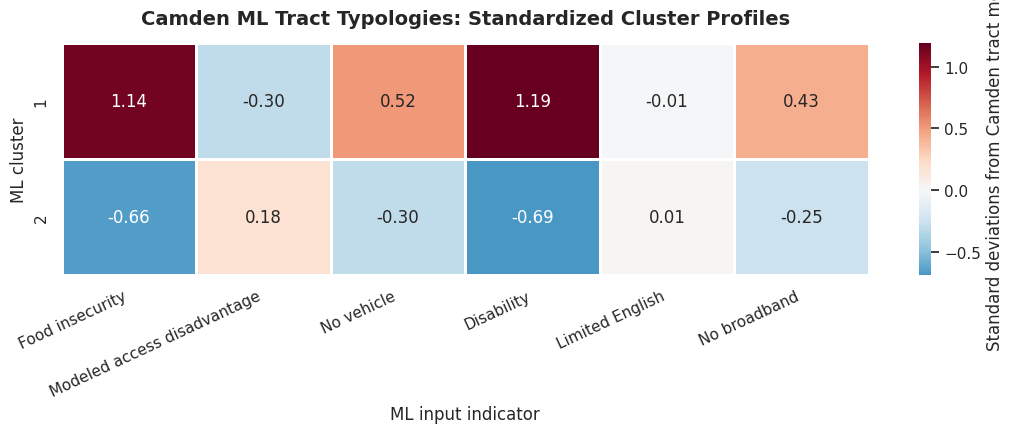

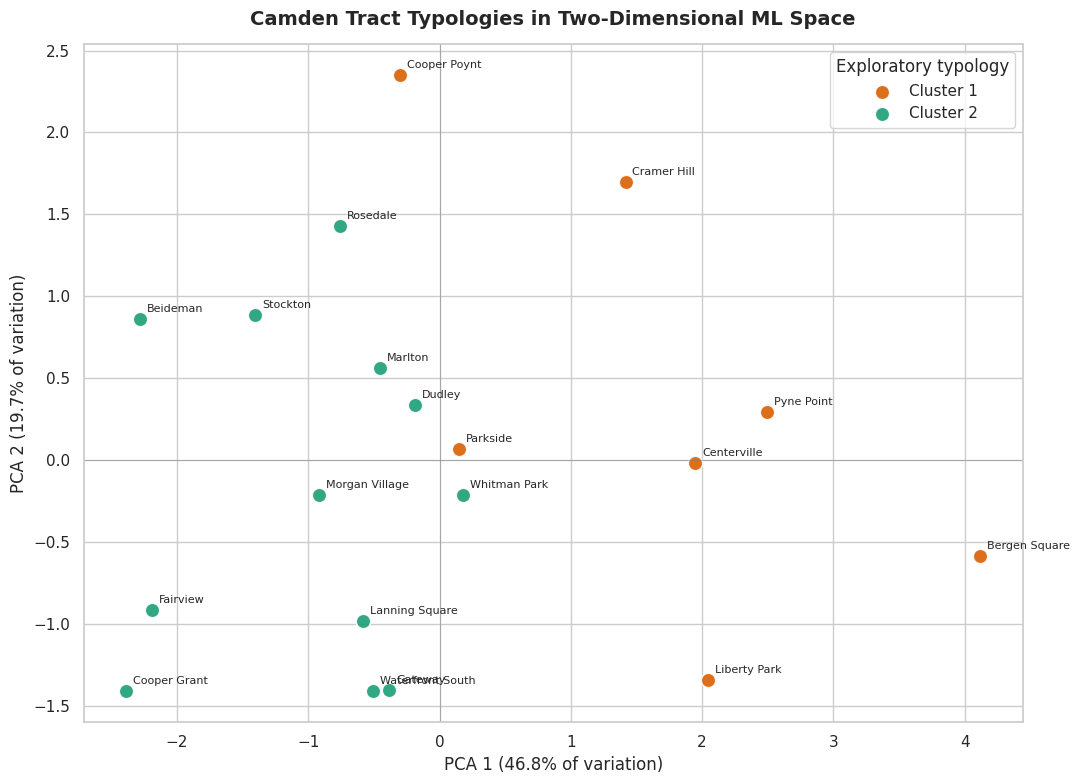


Final two-cluster tract assignments:


,geoid,neighborhood,tract_name,ml_cluster,ml_typology,places_food_insecurity_pct,relative_access_ratio,acs_no_vehicle_households_pct,places_disability_pct,acs_limited_english_pct,no_broadband_subscription_pct,relative_underserved_need_units,research_priority_index,research_priority_rank,ml_input_imputed,ml_model,ml_model_role,ml_silhouette_score
0,34007600700,Cooper Poynt Neighborhood,Census Tract 6007,1,Higher food insecurity and broader household b...,54.1,0.413920,19.512195,46.1,35.6,6.4,345.904210,89.5,3,False,Ward hierarchical clustering; two clusters,Exploratory tract typology; not a demand predi...,0.253
1,34007600800,Pyne Point Neighborhood,Census Tract 6008,1,Higher food insecurity and broader household b...,51.2,0.914482,49.223692,46.7,38.5,26.8,152.940454,68.4,7,False,Ward hierarchical clustering; two clusters,Exploratory tract typology; not a demand predi...,0.253
2,34007601400,Parkside Neighborhood,Census Tract 6014,1,Higher food insecurity and broader household b...,50.6,1.000000,25.178456,45.6,6.7,8.0,0.000000,28.9,10,False,Ward hierarchical clustering; two clusters,Exploratory tract typology; not a demand predi...,0.253
3,34007600900,Cramer Hill Neighborhood,Census Tract 6009,1,Higher food insecurity and broader household b...,58.4,1.062637,32.020997,47.6,39.4,10.1,0.000000,28.9,11,False,Ward hierarchical clustering; two clusters,Exploratory tract typology; not a demand predi...,0.253
4,34007601700,Centerville Neighborhood,Census Tract 6017,1,Higher food insecurity and broader household b...,59.5,1.104067,32.367973,48.1,6.7,17.1,0.000000,28.9,14,False,Ward hierarchical clustering; two clusters,Exploratory tract typology; not a demand predi...,0.253
5,34007601600,Liberty Park Neighborhood,Census Tract 6016,1,Higher food insecurity and broader household b...,51.5,1.509263,56.594724,44.3,14.9,13.9,0.000000,28.9,17,False,Ward hierarchical clustering; two clusters,Exploratory tract typology; not a demand predi...,0.253
6,34007600400,Bergen Square Neighborhood,Census Tract 6004,1,Higher food insecurity and broader household b...,59.7,1.600947,54.455446,49.2,25.7,27.9,0.000000,28.9,19,False,Ward hierarchical clustering; two clusters,Exploratory tract typology; not a demand predi...,0.253
7,34007602000,Fairview Neighborhood,Census Tract 6020,2,"Lower food insecurity overall, but generally w...",37.1,0.110694,31.598825,34.8,5.1,12.1,1426.269196,100.0,1,False,Ward hierarchical clustering; two clusters,Exploratory tract typology; not a demand predi...,0.253
8,34007601200,Stockton Neighborhood,Census Tract 6012,2,"Lower food insecurity overall, but generally w...",43.2,0.644221,21.101871,39.6,29.4,7.3,629.088257,94.7,2,False,Ward hierarchical clustering; two clusters,Exploratory tract typology; not a demand predi...,0.253
9,34007601102,Rosedale Neighborhood,Census Tract 6011.02,2,"Lower food insecurity overall, but generally w...",42.4,0.785954,15.267176,39.6,46.3,17.5,331.535123,84.2,4,False,Ward hierarchical clustering; two clusters,Exploratory tract typology; not a demand predi...,0.253



ML assignments added to tract_master: 19 of 19 tracts
ML assignments added to camden_gdf: 19 of 19 tracts

ML output files created in:
/content/camden_ml_typology_outputs

FINAL INTERPRETATION:
The two-cluster model is an exploratory unsupervised classification of Camden census tracts. It identifies recurring combinations of food insecurity, modeled service access, transportation barriers, disability, limited-English context, and broadband access. The silhouette score should be reported as evidence of modest cluster separation. The typology supports interpretation of the priority results but does not predict observed demand, measure service capacity, or determine a final food-truck or pantry location.


In [50]:
# ============================================================
# CAMDEN FOOD-ACCESS PROJECT
# END-TO-END ML TRACT TYPOLOGY ANALYSIS
#
# Method:
# - Unsupervised Ward hierarchical clustering
# - Two selected clusters
# - Six standardized percentage/relative indicators
#
# Important:
# - Counts, priority scores, and priority ranks do not determine
#   the clusters.
# - The clusters describe tract patterns; they do not predict
#   demand or make final siting decisions.
# ============================================================

# ------------------------------------------------------------
# 1. Import packages
# ------------------------------------------------------------

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA


# ------------------------------------------------------------
# 2. Confirm that the tract master data are available
# ------------------------------------------------------------

if "tract_master" not in globals():
    raise NameError(
        "tract_master is not loaded. Import the TRACT MASTER "
        "worksheet before running this analysis."
    )

ml_data = tract_master.copy()

print("Starting tract records:", len(ml_data))


# ------------------------------------------------------------
# 3. Standardize the GEOID
# ------------------------------------------------------------

if "geoid" not in ml_data.columns:
    raise KeyError("The tract master data must contain a geoid column.")

ml_data["geoid"] = (
    ml_data["geoid"]
    .astype(str)
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(11)
)

if ml_data["geoid"].duplicated().any():
    duplicate_geoids = ml_data.loc[
        ml_data["geoid"].duplicated(keep=False),
        "geoid"
    ].tolist()

    raise ValueError(
        f"Duplicate GEOIDs were found: {duplicate_geoids}"
    )

print("Unique GEOIDs:", ml_data["geoid"].nunique())


# ------------------------------------------------------------
# 4. Create the lack-of-broadband percentage if necessary
# ------------------------------------------------------------

if "no_broadband_subscription_pct" not in ml_data.columns:

    if "acs_broadband_subscription_pct" not in ml_data.columns:
        raise KeyError(
            "Neither no_broadband_subscription_pct nor "
            "acs_broadband_subscription_pct is available."
        )

    ml_data["acs_broadband_subscription_pct"] = pd.to_numeric(
        ml_data["acs_broadband_subscription_pct"],
        errors="coerce"
    )

    ml_data["no_broadband_subscription_pct"] = (
        100 - ml_data["acs_broadband_subscription_pct"]
    )


# ------------------------------------------------------------
# 5. Define the six ML input indicators
# ------------------------------------------------------------

# All six inputs are percentages or normalized relative measures.
# Raw population and household counts are intentionally excluded
# so that larger tracts do not automatically dominate the model.

ml_features = [
    "places_food_insecurity_pct",
    "relative_access_ratio",
    "acs_no_vehicle_households_pct",
    "places_disability_pct",
    "acs_limited_english_pct",
    "no_broadband_subscription_pct"
]

missing_columns = [
    column for column in ml_features
    if column not in ml_data.columns
]

if missing_columns:
    raise KeyError(
        "The following required ML columns are missing: "
        + ", ".join(missing_columns)
    )

feature_labels = {
    "places_food_insecurity_pct":
        "Food insecurity",

    "relative_access_ratio":
        "Modeled access disadvantage",

    "acs_no_vehicle_households_pct":
        "No vehicle",

    "places_disability_pct":
        "Disability",

    "acs_limited_english_pct":
        "Limited English",

    "no_broadband_subscription_pct":
        "No broadband"
}

print("ML features:", len(ml_features))


# ------------------------------------------------------------
# 6. Convert model inputs to numeric values
# ------------------------------------------------------------

for column in ml_features:
    ml_data[column] = pd.to_numeric(
        ml_data[column],
        errors="coerce"
    )

completely_missing = [
    column for column in ml_features
    if ml_data[column].isna().all()
]

if completely_missing:
    raise ValueError(
        "These ML variables contain no usable numeric values: "
        + ", ".join(completely_missing)
    )


# ------------------------------------------------------------
# 7. Check for missing values and preserve an imputation flag
# ------------------------------------------------------------

missing_before = ml_data[ml_features].isna().sum()

ml_data["ml_input_imputed"] = (
    ml_data[ml_features].isna().any(axis=1)
)

for column in ml_features:
    ml_data[column] = ml_data[column].fillna(
        ml_data[column].median()
    )

print("\nTracts included:", len(ml_data))
print("Unique GEOIDs:", ml_data["geoid"].nunique())

if missing_before.sum() == 0:
    print("No missing ML input values were found.")
else:
    print(
        "\nMissing values were filled using the Camden "
        "tract median for the relevant indicator:"
    )

    display(
        missing_before[missing_before > 0]
        .rename("values_filled")
        .to_frame()
    )


# ------------------------------------------------------------
# 8. Check the ranges of the model inputs
# ------------------------------------------------------------

percentage_features = [
    "places_food_insecurity_pct",
    "acs_no_vehicle_households_pct",
    "places_disability_pct",
    "acs_limited_english_pct",
    "no_broadband_subscription_pct"
]

range_issues = {}

for column in percentage_features:
    invalid_count = (
        (ml_data[column] < 0) |
        (ml_data[column] > 100)
    ).sum()

    if invalid_count > 0:
        range_issues[column] = int(invalid_count)

if (ml_data["relative_access_ratio"] < 0).any():
    range_issues["relative_access_ratio"] = int(
        (ml_data["relative_access_ratio"] < 0).sum()
    )

if range_issues:
    print("\nWARNING: Values outside expected ranges were found:")
    display(
        pd.Series(range_issues, name="invalid_values")
        .to_frame()
    )
else:
    print("All ML inputs are within their expected ranges.")


# ------------------------------------------------------------
# 9. Standardize the six indicators
# ------------------------------------------------------------

scaler = StandardScaler()

standardized_original = pd.DataFrame(
    scaler.fit_transform(ml_data[ml_features]),
    columns=ml_features,
    index=ml_data.index
)

# Create the matrix actually used by the clustering model.
#
# The relative access ratio is reversed after standardization:
# - Higher relative access ratio = stronger modeled access
# - Higher access-disadvantage value = weaker modeled access

X_ml = pd.DataFrame(
    {
        "Food insecurity":
            standardized_original[
                "places_food_insecurity_pct"
            ],

        "Modeled access disadvantage":
            -standardized_original[
                "relative_access_ratio"
            ],

        "No vehicle":
            standardized_original[
                "acs_no_vehicle_households_pct"
            ],

        "Disability":
            standardized_original[
                "places_disability_pct"
            ],

        "Limited English":
            standardized_original[
                "acs_limited_english_pct"
            ],

        "No broadband":
            standardized_original[
                "no_broadband_subscription_pct"
            ]
    },
    index=ml_data.index
)

print("\nStandardized ML matrix:")
display(X_ml.round(2).head())


# ------------------------------------------------------------
# 10. Reproduce the model-selection diagnostic
# ------------------------------------------------------------

cluster_evaluation_records = []

maximum_clusters = min(5, len(ml_data) - 1)

for number_of_clusters in range(2, maximum_clusters + 1):

    evaluation_model = AgglomerativeClustering(
        n_clusters=number_of_clusters,
        linkage="ward"
    )

    evaluation_labels = evaluation_model.fit_predict(X_ml)

    cluster_sizes = pd.Series(
        evaluation_labels
    ).value_counts().sort_index()

    cluster_evaluation_records.append(
        {
            "number_of_clusters": number_of_clusters,
            "silhouette_score": round(
                silhouette_score(
                    X_ml,
                    evaluation_labels
                ),
                3
            ),
            "smallest_cluster_size":
                int(cluster_sizes.min()),
            "largest_cluster_size":
                int(cluster_sizes.max()),
            "cluster_sizes":
                ", ".join(
                    cluster_sizes.astype(str).tolist()
                ),
            "all_clusters_at_least_3_tracts":
                bool(cluster_sizes.min() >= 3)
        }
    )

cluster_evaluation = pd.DataFrame(
    cluster_evaluation_records
)

print("\nCluster-count evaluation:")
display(cluster_evaluation)


# ------------------------------------------------------------
# 11. Fit the selected two-cluster Ward model
# ------------------------------------------------------------

two_cluster_model = AgglomerativeClustering(
    n_clusters=2,
    linkage="ward"
)

raw_cluster_labels = two_cluster_model.fit_predict(X_ml)

ml_data["_raw_ml_cluster"] = raw_cluster_labels


# ------------------------------------------------------------
# 12. Give cluster numbers stable substantive meanings
# ------------------------------------------------------------

# Algorithm-generated cluster numbers are arbitrary.
# We therefore remap the cluster with the higher average
# food-insecurity prevalence to Cluster 1.

raw_food_insecurity_profile = (
    ml_data.groupby("_raw_ml_cluster")
    ["places_food_insecurity_pct"]
    .mean()
)

higher_food_insecurity_raw_cluster = (
    raw_food_insecurity_profile.idxmax()
)

other_raw_cluster = [
    cluster
    for cluster in raw_food_insecurity_profile.index
    if cluster != higher_food_insecurity_raw_cluster
][0]

cluster_number_mapping = {
    higher_food_insecurity_raw_cluster: 1,
    other_raw_cluster: 2
}

ml_data["ml_cluster"] = (
    ml_data["_raw_ml_cluster"]
    .map(cluster_number_mapping)
    .astype(int)
)

ml_data = ml_data.drop(
    columns="_raw_ml_cluster"
)


# ------------------------------------------------------------
# 13. Evaluate the final two-cluster solution
# ------------------------------------------------------------

two_cluster_silhouette = silhouette_score(
    X_ml,
    ml_data["ml_cluster"]
)

cluster_sizes = (
    ml_data["ml_cluster"]
    .value_counts()
    .sort_index()
    .rename("tract_count")
    .to_frame()
)

print(
    "\nTwo-cluster silhouette score:",
    round(two_cluster_silhouette, 3)
)

print("\nCluster sizes:")
display(cluster_sizes)


# ------------------------------------------------------------
# 14. Create the standardized cluster profile
# ------------------------------------------------------------

standardized_cluster_profile = (
    X_ml
    .assign(ml_cluster=ml_data["ml_cluster"])
    .groupby("ml_cluster")
    .mean()
    .round(2)
)

print("\nStandardized cluster profile:")
print(
    "Positive values are above the Camden tract mean. "
    "For access disadvantage, positive values mean weaker access."
)

display(standardized_cluster_profile)


# ------------------------------------------------------------
# 15. Prepare additional explanatory measures
# ------------------------------------------------------------

if (
    "relative_access_shortfall_pct"
    not in ml_data.columns
    and
    "relative_access_shortfall_fraction"
    in ml_data.columns
):
    ml_data["relative_access_shortfall_pct"] = (
        pd.to_numeric(
            ml_data[
                "relative_access_shortfall_fraction"
            ],
            errors="coerce"
        ) * 100
    )


# ------------------------------------------------------------
# 16. Create the original-measure cluster profile
# ------------------------------------------------------------

profile_variables = [
    "places_food_insecurity_pct",
    "estimated_food_insecure_adults",
    "relative_access_ratio",
    "relative_access_shortfall_pct",
    "acs_no_vehicle_households_pct",
    "places_disability_pct",
    "acs_limited_english_pct",
    "no_broadband_subscription_pct",
    "services_within_1mi",
    "nearest_service_miles",
    "relative_underserved_need_units",
    "research_priority_index"
]

available_profile_variables = [
    column for column in profile_variables
    if column in ml_data.columns
]

cluster_profile = (
    ml_data
    .groupby("ml_cluster")[
        available_profile_variables
    ]
    .mean()
    .round(2)
)

cluster_profile.insert(
    0,
    "tract_count",
    ml_data.groupby("ml_cluster").size()
)

if "research_priority_rank" in ml_data.columns:
    cluster_profile["median_priority_rank"] = (
        ml_data.groupby("ml_cluster")
        ["research_priority_rank"]
        .median()
        .round(1)
    )

print("\nOriginal-measure cluster profile:")
display(cluster_profile)


# ------------------------------------------------------------
# 17. Assign evidence-based typology names
# ------------------------------------------------------------

cluster_1_access = (
    ml_data.loc[
        ml_data["ml_cluster"] == 1,
        "relative_access_ratio"
    ].mean()
)

cluster_2_access = (
    ml_data.loc[
        ml_data["ml_cluster"] == 2,
        "relative_access_ratio"
    ].mean()
)

cluster_1_gap = (
    ml_data.loc[
        ml_data["ml_cluster"] == 1,
        "relative_underserved_need_units"
    ].mean()
    if "relative_underserved_need_units"
    in ml_data.columns
    else np.nan
)

cluster_2_gap = (
    ml_data.loc[
        ml_data["ml_cluster"] == 2,
        "relative_underserved_need_units"
    ].mean()
    if "relative_underserved_need_units"
    in ml_data.columns
    else np.nan
)

# The following names reflect the current Camden profiles.
# The wording remains cautious because not every tract will match
# every cluster-average characteristic.

cluster_1_label = (
    "Higher food insecurity and broader household barriers; "
    "modeled access varies"
)

if (
    cluster_2_access < cluster_1_access
    and
    (
        np.isnan(cluster_2_gap)
        or np.isnan(cluster_1_gap)
        or cluster_2_gap > cluster_1_gap
    )
):
    cluster_2_label = (
        "Lower food insecurity overall, but generally weaker "
        "modeled access and larger relative gaps"
    )
else:
    cluster_2_label = (
        "Lower food insecurity overall; access and service-gap "
        "profile requires review"
    )

typology_labels = {
    1: cluster_1_label,
    2: cluster_2_label
}

ml_data["ml_typology"] = (
    ml_data["ml_cluster"]
    .map(typology_labels)
)

ml_data["ml_model"] = (
    "Ward hierarchical clustering; two clusters"
)

ml_data["ml_model_role"] = (
    "Exploratory tract typology; not a demand prediction "
    "or final siting decision"
)

ml_data["ml_silhouette_score"] = round(
    two_cluster_silhouette,
    3
)


# ------------------------------------------------------------
# 18. Display the typology interpretation
# ------------------------------------------------------------

typology_interpretation = pd.DataFrame(
    {
        "ml_cluster": [1, 2],
        "ml_typology": [
            cluster_1_label,
            cluster_2_label
        ],
        "interpretation": [
            (
                "Tracts grouped primarily by higher modeled "
                "food insecurity, disability, vehicle barriers, "
                "and other outreach-context indicators. Access "
                "conditions still vary among individual tracts."
            ),
            (
                "Tracts have lower food insecurity on average, "
                "but the cluster shows weaker modeled service "
                "access and larger relative service gaps on "
                "average. Individual tracts may differ."
            )
        ]
    }
)

print("\nFinal typology interpretation:")
display(typology_interpretation)


# ------------------------------------------------------------
# 19. Create a standardized profile heatmap
# ------------------------------------------------------------

sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(11, 4.5))

sns.heatmap(
    standardized_cluster_profile,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    linewidths=0.8,
    linecolor="white",
    cbar_kws={
        "label": "Standard deviations from Camden tract mean"
    },
    ax=ax
)

ax.set_title(
    "Camden ML Tract Typologies: Standardized Cluster Profiles",
    fontsize=14,
    fontweight="bold",
    pad=14
)

ax.set_xlabel("ML input indicator")
ax.set_ylabel("ML cluster")

plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 20. Create a two-dimensional PCA visualization
# ------------------------------------------------------------

# PCA is used only to visualize the six-dimensional clustering.
# It does not determine the clusters.

pca = PCA(n_components=2)

pca_coordinates = pca.fit_transform(X_ml)

pca_results = pd.DataFrame(
    {
        "PCA 1": pca_coordinates[:, 0],
        "PCA 2": pca_coordinates[:, 1],
        "ml_cluster": ml_data["ml_cluster"].values
    },
    index=ml_data.index
)

if "neighborhood" in ml_data.columns:
    pca_results["label"] = (
        ml_data["neighborhood"]
        .fillna(ml_data.get("tract_name", "Unknown tract"))
        .astype(str)
        .str.replace(
            " Neighborhood",
            "",
            regex=False
        )
    )
elif "tract_name" in ml_data.columns:
    pca_results["label"] = (
        ml_data["tract_name"].astype(str)
    )
else:
    pca_results["label"] = ml_data["geoid"]

cluster_colors = {
    1: "#D95F02",
    2: "#1B9E77"
}

fig, ax = plt.subplots(figsize=(11, 8))

for cluster_number in [1, 2]:

    cluster_points = pca_results[
        pca_results["ml_cluster"] == cluster_number
    ]

    ax.scatter(
        cluster_points["PCA 1"],
        cluster_points["PCA 2"],
        s=110,
        color=cluster_colors[cluster_number],
        edgecolor="white",
        linewidth=1.2,
        alpha=0.9,
        label=f"Cluster {cluster_number}"
    )

    for _, row in cluster_points.iterrows():
        ax.annotate(
            row["label"],
            (row["PCA 1"], row["PCA 2"]),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8
        )

explained_variance = (
    pca.explained_variance_ratio_ * 100
)

ax.set_title(
    "Camden Tract Typologies in Two-Dimensional ML Space",
    fontsize=14,
    fontweight="bold",
    pad=14
)

ax.set_xlabel(
    f"PCA 1 ({explained_variance[0]:.1f}% of variation)"
)

ax.set_ylabel(
    f"PCA 2 ({explained_variance[1]:.1f}% of variation)"
)

ax.axhline(0, color="gray", linewidth=0.7, alpha=0.5)
ax.axvline(0, color="gray", linewidth=0.7, alpha=0.5)
ax.legend(title="Exploratory typology")

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 21. Create the final tract assignment table
# ------------------------------------------------------------

assignment_columns = [
    "geoid",
    "neighborhood",
    "tract_name",
    "ml_cluster",
    "ml_typology",
    "places_food_insecurity_pct",
    "relative_access_ratio",
    "acs_no_vehicle_households_pct",
    "places_disability_pct",
    "acs_limited_english_pct",
    "no_broadband_subscription_pct",
    "relative_underserved_need_units",
    "research_priority_index",
    "research_priority_rank",
    "ml_input_imputed",
    "ml_model",
    "ml_model_role",
    "ml_silhouette_score"
]

assignment_columns = [
    column for column in assignment_columns
    if column in ml_data.columns
]

ml_typology_assignments = (
    ml_data[assignment_columns]
    .sort_values(
        ["ml_cluster", "research_priority_rank"]
        if "research_priority_rank" in assignment_columns
        else ["ml_cluster", "geoid"]
    )
    .reset_index(drop=True)
)

print("\nFinal two-cluster tract assignments:")
display(ml_typology_assignments)


# ------------------------------------------------------------
# 22. Merge the final ML results into tract_master
# ------------------------------------------------------------

ml_merge_columns = [
    "geoid",
    "ml_cluster",
    "ml_typology",
    "ml_input_imputed",
    "ml_model",
    "ml_model_role",
    "ml_silhouette_score"
]

tract_master = tract_master.copy()

tract_master["geoid"] = (
    tract_master["geoid"]
    .astype(str)
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(11)
)

tract_master = tract_master.drop(
    columns=[
        "ml_cluster",
        "ml_typology",
        "ml_input_imputed",
        "ml_model",
        "ml_model_role",
        "ml_silhouette_score"
    ],
    errors="ignore"
)

tract_master = tract_master.merge(
    ml_data[ml_merge_columns],
    on="geoid",
    how="left",
    validate="one_to_one"
)

print(
    "\nML assignments added to tract_master:",
    tract_master["ml_cluster"].notna().sum(),
    "of",
    len(tract_master),
    "tracts"
)


# ------------------------------------------------------------
# 23. Merge the final ML results into camden_gdf
# ------------------------------------------------------------

if "camden_gdf" in globals():

    camden_gdf = camden_gdf.copy()

    camden_gdf["geoid"] = (
        camden_gdf["geoid"]
        .astype(str)
        .str.strip()
        .str.replace(r"\.0$", "", regex=True)
        .str.zfill(11)
    )

    camden_gdf = camden_gdf.drop(
        columns=[
            "ml_cluster",
            "ml_typology",
            "ml_input_imputed",
            "ml_model",
            "ml_model_role",
            "ml_silhouette_score"
        ],
        errors="ignore"
    )

    camden_gdf = camden_gdf.merge(
        ml_data[ml_merge_columns],
        on="geoid",
        how="left",
        validate="one_to_one"
    )

    print(
        "ML assignments added to camden_gdf:",
        camden_gdf["ml_cluster"].notna().sum(),
        "of",
        len(camden_gdf),
        "tracts"
    )

else:
    print(
        "\ncamden_gdf was not found. The ML assignments were "
        "added to tract_master only."
    )


# ------------------------------------------------------------
# 24. Export reproducible ML outputs
# ------------------------------------------------------------

output_directory = Path(
    "/content/camden_ml_typology_outputs"
)

output_directory.mkdir(
    parents=True,
    exist_ok=True
)

ml_typology_assignments.to_csv(
    output_directory /
    "camden_ml_typology_assignments.csv",
    index=False
)

cluster_profile.reset_index().to_csv(
    output_directory /
    "camden_ml_cluster_profile_original_measures.csv",
    index=False
)

standardized_cluster_profile.reset_index().to_csv(
    output_directory /
    "camden_ml_cluster_profile_standardized.csv",
    index=False
)

cluster_evaluation.to_csv(
    output_directory /
    "camden_ml_cluster_count_evaluation.csv",
    index=False
)

typology_interpretation.to_csv(
    output_directory /
    "camden_ml_typology_interpretation.csv",
    index=False
)

tract_master_export = tract_master.drop(
    columns=["geometry"],
    errors="ignore"
)

tract_master_export.to_csv(
    output_directory /
    "camden_tract_master_with_ml_typology.csv",
    index=False
)

print("\nML output files created in:")
print(output_directory)


# ------------------------------------------------------------
# 25. Final methodological statement
# ------------------------------------------------------------

print(
    "\nFINAL INTERPRETATION:\n"
    "The two-cluster model is an exploratory unsupervised "
    "classification of Camden census tracts. It identifies "
    "recurring combinations of food insecurity, modeled service "
    "access, transportation barriers, disability, limited-English "
    "context, and broadband access. The silhouette score should "
    "be reported as evidence of modest cluster separation. The "
    "typology supports interpretation of the priority results but "
    "does not predict observed demand, measure service capacity, "
    "or determine a final food-truck or pantry location."
)

#### **Map: ML Priority Decision Support Map.**

In [51]:
# ============================================================
# MAP 10 — ML TYPOLOGY AND PRIORITY DECISION-SUPPORT MAP
#
# Shows:
# 1. Two exploratory ML tract typologies
# 2. Optional modeled priority-index shading
# 3. Five highest-ranked candidate tracts
# 4. Included food-assistance service records
#
# Important:
# - Candidate tracts are planning-screen results, not approved sites.
# - Service records are included records, not operationally verified.
# - ML typologies describe patterns; they are not predictions.
# ============================================================

# If necessary, install the mapping packages
!pip -q install folium branca

import html
import numpy as np
import pandas as pd
import geopandas as gpd
import folium
import branca.colormap as cm

from IPython.display import display
from folium.plugins import (
    MarkerCluster,
    Fullscreen,
    Search,
    MeasureControl,
    MiniMap,
    Geocoder,
    MousePosition
)


# ------------------------------------------------------------
# 1. Confirm that the required data are available
# ------------------------------------------------------------

if "camden_gdf" not in globals():
    raise NameError(
        "camden_gdf is not available. Run the tract-boundary "
        "preparation and ML typology cells first."
    )

required_tract_columns = [
    "geoid",
    "neighborhood",
    "tract_name",
    "ml_cluster",
    "ml_typology",
    "places_food_insecurity_pct",
    "relative_access_ratio",
    "research_priority_index",
    "research_priority_rank"
]

missing_tract_columns = [
    column for column in required_tract_columns
    if column not in camden_gdf.columns
]

if missing_tract_columns:
    raise KeyError(
        "Map 10 requires these missing tract columns: "
        + ", ".join(missing_tract_columns)
    )

if "services" not in globals():
    raise NameError(
        "The services table is not available. Load the service "
        "location master table as a DataFrame named services."
    )


# ------------------------------------------------------------
# 2. Prepare the tract polygons
# ------------------------------------------------------------

map_10_gdf = camden_gdf.copy()

if map_10_gdf.crs is None:
    raise ValueError(
        "camden_gdf does not have a coordinate reference system."
    )

map_10_gdf = map_10_gdf.to_crs(epsg=4326)

map_10_gdf["geoid"] = (
    map_10_gdf["geoid"]
    .astype(str)
    .str.strip()
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(11)
)

numeric_tract_columns = [
    "ml_cluster",
    "places_food_insecurity_pct",
    "estimated_food_insecure_adults",
    "relative_access_ratio",
    "relative_access_shortfall_fraction",
    "relative_access_shortfall_pct",
    "services_in_tract",
    "services_within_1mi",
    "nearest_service_miles",
    "acs_no_vehicle_households_pct",
    "places_disability_pct",
    "acs_limited_english_pct",
    "no_broadband_subscription_pct",
    "relative_underserved_need_units",
    "research_priority_index",
    "research_priority_rank"
]

for column in numeric_tract_columns:
    if column in map_10_gdf.columns:
        map_10_gdf[column] = pd.to_numeric(
            map_10_gdf[column],
            errors="coerce"
        )

# Create short typology labels for map tooltips
short_typology_labels = {
    1: "Higher food insecurity and broader household barriers",
    2: "Generally weaker modeled access and larger relative gaps"
}

map_10_gdf["ml_typology_short"] = (
    map_10_gdf["ml_cluster"]
    .map(short_typology_labels)
    .fillna("Typology unavailable")
)


# ------------------------------------------------------------
# 3. Create formatted popup fields
# ------------------------------------------------------------

def format_number(value, decimals=1, suffix=""):
    """Return a clean display value without fabricating missing data."""

    if pd.isna(value):
        return "Not available"

    try:
        return f"{float(value):,.{decimals}f}{suffix}"
    except (TypeError, ValueError):
        return html.escape(str(value))


def format_integer(value):
    """Format a whole-number count or rank."""

    if pd.isna(value):
        return "Not available"

    try:
        return f"{int(round(float(value))):,}"
    except (TypeError, ValueError):
        return html.escape(str(value))


def format_access_ratio(value):
    """Format the relative access ratio and explain its direction."""

    if pd.isna(value):
        return "Not available"

    value = float(value)

    if value < 1:
        explanation = "below Camden average"
    elif value > 1:
        explanation = "above Camden average"
    else:
        explanation = "equal to Camden average"

    return f"{value:.2f} ({explanation})"


def build_tract_popup(row):
    """Create the complete tract profile shown when a tract is clicked."""

    neighborhood = html.escape(
        str(row.get("neighborhood", "Neighborhood unavailable"))
    )

    tract_name = html.escape(
        str(row.get("tract_name", "Tract unavailable"))
    )

    typology = html.escape(
        str(row.get("ml_typology", "Typology unavailable"))
    )

    priority_rank = format_integer(
        row.get("research_priority_rank")
    )

    priority_score = format_number(
        row.get("research_priority_index"),
        1
    )

    food_insecurity = format_number(
        row.get("places_food_insecurity_pct"),
        1,
        "%"
    )

    estimated_adults = format_number(
        row.get("estimated_food_insecure_adults"),
        0
    )

    access_ratio = format_access_ratio(
        row.get("relative_access_ratio")
    )

    relative_gap = format_number(
        row.get("relative_underserved_need_units"),
        1
    )

    services_in_tract = format_integer(
        row.get("services_in_tract")
    )

    services_within_1mi = format_integer(
        row.get("services_within_1mi")
    )

    nearest_service = format_number(
        row.get("nearest_service_miles"),
        2,
        " miles"
    )

    no_vehicle = format_number(
        row.get("acs_no_vehicle_households_pct"),
        1,
        "%"
    )

    disability = format_number(
        row.get("places_disability_pct"),
        1,
        "%"
    )

    limited_english = format_number(
        row.get("acs_limited_english_pct"),
        1,
        "%"
    )

    no_broadband = format_number(
        row.get("no_broadband_subscription_pct"),
        1,
        "%"
    )

    candidate_status = (
        "<b style='color:#8A5A00;'>Top-five candidate tract</b>"
        if bool(row.get("candidate_zone", False))
        else "Not among the five highest-ranked tracts"
    )

    return f"""
    <div style="
        font-family:Arial, sans-serif;
        font-size:12px;
        line-height:1.45;
        width:370px;
    ">

        <div style="
            font-size:16px;
            font-weight:bold;
            color:#24332E;
            margin-bottom:2px;
        ">
            {neighborhood}
        </div>

        <div style="color:#666; margin-bottom:10px;">
            {tract_name}
        </div>

        <div style="
            background:#F1F5F3;
            border-left:5px solid #31688E;
            padding:8px;
            margin-bottom:10px;
        ">
            <b>Exploratory ML typology</b><br>
            {typology}
        </div>

        <table style="
            width:100%;
            border-collapse:collapse;
            margin-bottom:10px;
        ">
            <tr>
                <td style="padding:4px; font-weight:bold;">
                    Modeled priority rank
                </td>
                <td style="padding:4px; text-align:right;">
                    {priority_rank}
                </td>
            </tr>
            <tr style="background:#F7F7F7;">
                <td style="padding:4px; font-weight:bold;">
                    Modeled priority index
                </td>
                <td style="padding:4px; text-align:right;">
                    {priority_score}
                </td>
            </tr>
            <tr>
                <td style="padding:4px; font-weight:bold;">
                    Food-insecurity prevalence
                </td>
                <td style="padding:4px; text-align:right;">
                    {food_insecurity}
                </td>
            </tr>
            <tr style="background:#F7F7F7;">
                <td style="padding:4px; font-weight:bold;">
                    Derived food-insecure adults
                </td>
                <td style="padding:4px; text-align:right;">
                    {estimated_adults}
                </td>
            </tr>
            <tr>
                <td style="padding:4px; font-weight:bold;">
                    Relative access ratio
                </td>
                <td style="padding:4px; text-align:right;">
                    {access_ratio}
                </td>
            </tr>
            <tr style="background:#F7F7F7;">
                <td style="padding:4px; font-weight:bold;">
                    Relative underserved-need units
                </td>
                <td style="padding:4px; text-align:right;">
                    {relative_gap}
                </td>
            </tr>
        </table>

        <div style="
            font-weight:bold;
            color:#344A43;
            margin-bottom:4px;
        ">
            Included service-record access
        </div>

        <table style="
            width:100%;
            border-collapse:collapse;
            margin-bottom:10px;
        ">
            <tr>
                <td style="padding:4px;">Records in tract</td>
                <td style="padding:4px; text-align:right;">
                    {services_in_tract}
                </td>
            </tr>
            <tr style="background:#F7F7F7;">
                <td style="padding:4px;">Records within one mile</td>
                <td style="padding:4px; text-align:right;">
                    {services_within_1mi}
                </td>
            </tr>
            <tr>
                <td style="padding:4px;">Nearest included record</td>
                <td style="padding:4px; text-align:right;">
                    {nearest_service}
                </td>
            </tr>
        </table>

        <div style="
            font-weight:bold;
            color:#344A43;
            margin-bottom:4px;
        ">
            Outreach context
        </div>

        <table style="
            width:100%;
            border-collapse:collapse;
            margin-bottom:10px;
        ">
            <tr>
                <td style="padding:4px;">Households without a vehicle</td>
                <td style="padding:4px; text-align:right;">
                    {no_vehicle}
                </td>
            </tr>
            <tr style="background:#F7F7F7;">
                <td style="padding:4px;">Adults with a disability</td>
                <td style="padding:4px; text-align:right;">
                    {disability}
                </td>
            </tr>
            <tr>
                <td style="padding:4px;">Limited-English context</td>
                <td style="padding:4px; text-align:right;">
                    {limited_english}
                </td>
            </tr>
            <tr style="background:#F7F7F7;">
                <td style="padding:4px;">
                    Households without broadband
                </td>
                <td style="padding:4px; text-align:right;">
                    {no_broadband}
                </td>
            </tr>
        </table>

        <div style="
            background:#FFF5D9;
            padding:7px;
            border-radius:4px;
            margin-bottom:8px;
        ">
            {candidate_status}
        </div>

        <div style="
            color:#666;
            font-size:10.5px;
            border-top:1px solid #DDD;
            padding-top:7px;
        ">
            This is a modeled planning screen, not observed unmet
            demand or a final siting decision. Cluster descriptions
            summarize averages and may not describe every tract
            characteristic.
        </div>
    </div>
    """


# ------------------------------------------------------------
# 4. Define the top candidate tracts
# ------------------------------------------------------------

TOP_CANDIDATE_TRACTS = 5

valid_priority_ranks = (
    map_10_gdf["research_priority_rank"]
    .dropna()
    .sort_values()
    .unique()
)

top_rank_values = valid_priority_ranks[
    :TOP_CANDIDATE_TRACTS
]

map_10_gdf["candidate_zone"] = (
    map_10_gdf["research_priority_rank"]
    .isin(top_rank_values)
)

candidate_gdf = map_10_gdf[
    map_10_gdf["candidate_zone"]
].copy()

print(
    "Candidate tracts highlighted:",
    len(candidate_gdf)
)


# ------------------------------------------------------------
# 5. Prepare the included service records
# ------------------------------------------------------------

services_map = services.copy()


def find_first_column(dataframe, possible_columns):
    """Find the first available column from a list of alternatives."""

    for column in possible_columns:
        if column in dataframe.columns:
            return column

    return None


service_latitude_column = find_first_column(
    services_map,
    [
        "latitude",
        "service_latitude",
        "lat",
        "Latitude",
        "LATITUDE"
    ]
)

service_longitude_column = find_first_column(
    services_map,
    [
        "longitude",
        "service_longitude",
        "lon",
        "lng",
        "Longitude",
        "LONGITUDE"
    ]
)

if service_latitude_column is None:
    raise KeyError(
        "No service latitude column was found."
    )

if service_longitude_column is None:
    raise KeyError(
        "No service longitude column was found."
    )

services_map["_map_latitude"] = pd.to_numeric(
    services_map[service_latitude_column],
    errors="coerce"
)

services_map["_map_longitude"] = pd.to_numeric(
    services_map[service_longitude_column],
    errors="coerce"
)

services_map = services_map.dropna(
    subset=[
        "_map_latitude",
        "_map_longitude"
    ]
).copy()

# Keep only geographically plausible coordinates
services_map = services_map[
    services_map["_map_latitude"].between(39, 41)
    &
    services_map["_map_longitude"].between(-76, -74)
].copy()

print(
    "Service records with usable mapped coordinates:",
    len(services_map)
)


# ------------------------------------------------------------
# 6. Service-popup helper functions
# ------------------------------------------------------------

def first_nonempty_value(row, possible_columns, default="Not available"):
    """Return the first non-empty value found in a service record."""

    for column in possible_columns:

        if column not in row.index:
            continue

        value = row.get(column)

        if pd.isna(value):
            continue

        value = str(value).strip()

        if value and value.lower() not in {
            "nan",
            "none",
            "not available"
        }:
            return value

    return default


def build_service_popup(row):
    """Create a service-location popup using available details."""

    name = html.escape(
        first_nonempty_value(
            row,
            [
                "primary_name",
                "organization_name",
                "service_name",
                "name"
            ],
            "Included food-assistance record"
        )
    )

    service_type = html.escape(
        first_nonempty_value(
            row,
            [
                "service_types",
                "service_type",
                "organization_type",
                "type"
            ]
        )
    )

    address = html.escape(
        first_nonempty_value(
            row,
            [
                "full_address",
                "address",
                "street_address"
            ]
        )
    )

    phone = html.escape(
        first_nonempty_value(
            row,
            [
                "phone",
                "phone_number",
                "telephone"
            ]
        )
    )

    hours = html.escape(
        first_nonempty_value(
            row,
            [
                "hours",
                "hours_of_operation",
                "schedule",
                "service_schedule"
            ]
        )
    )

    eligibility = html.escape(
        first_nonempty_value(
            row,
            [
                "eligibility",
                "eligibility_notes",
                "requirements"
            ]
        )
    )

    source_status = html.escape(
        first_nonempty_value(
            row,
            [
                "verification_status",
                "operating_status",
                "record_status",
                "status"
            ]
        )
    )

    source = html.escape(
        first_nonempty_value(
            row,
            [
                "source",
                "source_name",
                "record_source"
            ]
        )
    )

    return f"""
    <div style="
        font-family:Arial, sans-serif;
        font-size:12px;
        line-height:1.45;
        width:320px;
    ">

        <div style="
            font-size:15px;
            font-weight:bold;
            color:#165B46;
            margin-bottom:7px;
        ">
            {name}
        </div>

        <table style="
            width:100%;
            border-collapse:collapse;
        ">
            <tr>
                <td style="padding:4px; font-weight:bold;">Type</td>
                <td style="padding:4px;">{service_type}</td>
            </tr>
            <tr style="background:#F7F7F7;">
                <td style="padding:4px; font-weight:bold;">Address</td>
                <td style="padding:4px;">{address}</td>
            </tr>
            <tr>
                <td style="padding:4px; font-weight:bold;">Phone</td>
                <td style="padding:4px;">{phone}</td>
            </tr>
            <tr style="background:#F7F7F7;">
                <td style="padding:4px; font-weight:bold;">Hours</td>
                <td style="padding:4px;">{hours}</td>
            </tr>
            <tr>
                <td style="padding:4px; font-weight:bold;">Eligibility</td>
                <td style="padding:4px;">{eligibility}</td>
            </tr>
            <tr style="background:#F7F7F7;">
                <td style="padding:4px; font-weight:bold;">
                    Source status
                </td>
                <td style="padding:4px;">{source_status}</td>
            </tr>
            <tr>
                <td style="padding:4px; font-weight:bold;">Source</td>
                <td style="padding:4px;">{source}</td>
            </tr>
        </table>

        <div style="
            background:#FFF1E5;
            border-left:4px solid #D95F02;
            padding:7px;
            margin-top:9px;
            font-size:10.5px;
            color:#6A3B18;
        ">
            Included record only. Current operating status,
            schedule, eligibility, and service capacity have not
            been independently confirmed for this project.
        </div>
    </div>
    """


# ------------------------------------------------------------
# 7. Establish the map extent
# ------------------------------------------------------------

minimum_longitude, minimum_latitude, maximum_longitude, maximum_latitude = (
    map_10_gdf.total_bounds
)

map_center = [
    (minimum_latitude + maximum_latitude) / 2,
    (minimum_longitude + maximum_longitude) / 2
]


# ------------------------------------------------------------
# 8. Create the map with a reliable light-gray basemap
# ------------------------------------------------------------

map_10 = folium.Map(
    location=map_center,
    zoom_start=12,
    tiles=None,
    control_scale=True,
    prefer_canvas=True
)

folium.TileLayer(
    tiles=(
        "https://server.arcgisonline.com/ArcGIS/rest/services/"
        "Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}"
    ),
    attr="Esri, HERE, Garmin, USGS, NGA, EPA, USDA, NPS",
    name="Light gray basemap",
    overlay=False,
    control=True,
    show=True
).add_to(map_10)

map_10.fit_bounds(
    [
        [minimum_latitude, minimum_longitude],
        [maximum_latitude, maximum_longitude]
    ]
)


# ------------------------------------------------------------
# 9. Add the ML typology layer
# ------------------------------------------------------------

cluster_colors = {
    1: "#D95F02",
    2: "#1B9E77"
}

typology_layer = folium.FeatureGroup(
    name="ML tract typologies",
    show=True
)

for _, row in map_10_gdf.iterrows():

    cluster_number = row.get("ml_cluster")

    try:
        cluster_number = int(cluster_number)
    except (TypeError, ValueError):
        cluster_number = 0

    fill_color = cluster_colors.get(
        cluster_number,
        "#BDBDBD"
    )

    one_tract = gpd.GeoDataFrame(
        [row],
        geometry="geometry",
        crs=map_10_gdf.crs
    )

    folium.GeoJson(
        data=one_tract.to_json(),
        style_function=lambda feature, color=fill_color: {
            "fillColor": color,
            "color": "#3B4541",
            "weight": 1.2,
            "fillOpacity": 0.64
        },
        highlight_function=lambda feature: {
            "color": "#111111",
            "weight": 3,
            "fillOpacity": 0.82
        },
        tooltip=folium.Tooltip(
            f"""
            <b>{html.escape(str(row.get("neighborhood", "")))}</b><br>
            {html.escape(str(row.get("tract_name", "")))}<br>
            ML cluster: {cluster_number}<br>
            {html.escape(str(row.get("ml_typology_short", "")))}<br>
            Priority rank: {format_integer(row.get("research_priority_rank"))}
            """,
            sticky=True
        ),
        popup=folium.Popup(
            build_tract_popup(row),
            max_width=430
        )
    ).add_to(typology_layer)

typology_layer.add_to(map_10)


# ------------------------------------------------------------
# 10. Add the optional priority-index layer
# ------------------------------------------------------------

priority_minimum = float(
    map_10_gdf["research_priority_index"].min()
)

priority_maximum = float(
    map_10_gdf["research_priority_index"].max()
)

if priority_minimum == priority_maximum:
    priority_maximum = priority_minimum + 1

priority_colormap = cm.LinearColormap(
    colors=[
        "#FFF7BC",
        "#FEC44F",
        "#FE9929",
        "#EC7014",
        "#CC4C02",
        "#8C2D04"
    ],
    vmin=priority_minimum,
    vmax=priority_maximum,
    caption="Modeled research priority index"
)

priority_layer = folium.FeatureGroup(
    name="Modeled priority-index shading",
    show=False
)

for _, row in map_10_gdf.iterrows():

    priority_value = row.get(
        "research_priority_index"
    )

    if pd.isna(priority_value):
        priority_color = "#BDBDBD"
    else:
        priority_color = priority_colormap(
            float(priority_value)
        )

    one_tract = gpd.GeoDataFrame(
        [row],
        geometry="geometry",
        crs=map_10_gdf.crs
    )

    folium.GeoJson(
        data=one_tract.to_json(),
        style_function=lambda feature, color=priority_color: {
            "fillColor": color,
            "color": "#3B4541",
            "weight": 1.2,
            "fillOpacity": 0.68
        },
        highlight_function=lambda feature: {
            "color": "#111111",
            "weight": 3,
            "fillOpacity": 0.85
        },
        tooltip=folium.Tooltip(
            f"""
            <b>{html.escape(str(row.get("neighborhood", "")))}</b><br>
            Priority rank:
            {format_integer(row.get("research_priority_rank"))}<br>
            Priority index:
            {format_number(row.get("research_priority_index"), 1)}
            """,
            sticky=True
        ),
        popup=folium.Popup(
            build_tract_popup(row),
            max_width=430
        )
    ).add_to(priority_layer)

priority_layer.add_to(map_10)

priority_colormap.add_to(map_10)


# ------------------------------------------------------------
# 11. Highlight the five top-ranked candidate tracts
# ------------------------------------------------------------

candidate_layer = folium.FeatureGroup(
    name=(
        f"Top {TOP_CANDIDATE_TRACTS} priority-ranked "
        "candidate tracts"
    ),
    show=True
)

folium.GeoJson(
    data=candidate_gdf.to_json(),
    style_function=lambda feature: {
        "fillColor": "transparent",
        "color": "#FFD000",
        "weight": 5,
        "dashArray": "8, 5",
        "fillOpacity": 0
    },
    highlight_function=lambda feature: {
        "color": "#FFB000",
        "weight": 7,
        "fillOpacity": 0.10
    },
    tooltip=folium.GeoJsonTooltip(
        fields=[
            "neighborhood",
            "tract_name",
            "research_priority_rank",
            "research_priority_index"
        ],
        aliases=[
            "Neighborhood:",
            "Census tract:",
            "Modeled priority rank:",
            "Modeled priority index:"
        ],
        sticky=True,
        labels=True,
        localize=True
    )
).add_to(candidate_layer)

# Add rank badges at representative points.
# These are tract reference labels—not proposed addresses.

if len(candidate_gdf) > 0:

    candidate_points = candidate_gdf.to_crs(
        epsg=3857
    ).copy()

    candidate_points["geometry"] = (
        candidate_points.geometry.representative_point()
    )

    candidate_points = candidate_points.to_crs(
        epsg=4326
    )

    for _, row in candidate_points.iterrows():

        rank = format_integer(
            row.get("research_priority_rank")
        )

        folium.Marker(
            location=[
                row.geometry.y,
                row.geometry.x
            ],
            icon=folium.DivIcon(
                html=f"""
                <div style="
                    background:#FFD000;
                    color:#332900;
                    border:2px solid #6F5900;
                    border-radius:50%;
                    width:28px;
                    height:28px;
                    line-height:24px;
                    text-align:center;
                    font-size:12px;
                    font-weight:bold;
                    box-shadow:0 1px 4px rgba(0,0,0,.4);
                ">
                    #{rank}
                </div>
                """
            ),
            tooltip=(
                f"Priority rank #{rank}: "
                f"{row.get('neighborhood', '')}. "
                "Tract reference marker—not an exact site."
            )
        ).add_to(candidate_layer)

candidate_layer.add_to(map_10)


# ------------------------------------------------------------
# 12. Add the included service-location records
# ------------------------------------------------------------

service_layer = folium.FeatureGroup(
    name=(
        f"Included service records "
        f"({len(services_map)} mapped; not verified)"
    ),
    show=True
)

service_marker_cluster = MarkerCluster(
    name="Service record markers",
    control=False,
    disableClusteringAtZoom=15
)

for _, row in services_map.iterrows():

    service_name = first_nonempty_value(
        row,
        [
            "primary_name",
            "organization_name",
            "service_name",
            "name"
        ],
        "Included food-assistance record"
    )

    service_type = first_nonempty_value(
        row,
        [
            "service_types",
            "service_type",
            "organization_type",
            "type"
        ],
        "Food-assistance record"
    )

    folium.CircleMarker(
        location=[
            row["_map_latitude"],
            row["_map_longitude"]
        ],
        radius=7,
        color="#FFFFFF",
        weight=2,
        fill=True,
        fill_color="#0B6E4F",
        fill_opacity=0.95,
        tooltip=(
            f"{html.escape(service_name)} — "
            f"{html.escape(service_type)}"
        ),
        popup=folium.Popup(
            build_service_popup(row),
            max_width=380
        )
    ).add_to(service_marker_cluster)

service_marker_cluster.add_to(service_layer)
service_layer.add_to(map_10)


# ------------------------------------------------------------
# 13. Add the title and methodological note
# ------------------------------------------------------------

map_title_html = f"""
<div style="
    position:fixed;
    top:18px;
    left:60px;
    z-index:9999;
    width:445px;
    background:rgba(255,255,255,0.96);
    border:1px solid #D7DFDB;
    border-radius:10px;
    padding:13px 15px;
    box-shadow:0 2px 8px rgba(0,0,0,0.18);
    font-family:Arial, sans-serif;
">

    <div style="
        font-size:20px;
        font-weight:bold;
        color:#24332E;
        margin-bottom:4px;
    ">
        Camden ML Typology and Priority Screen
    </div>

    <div style="
        font-size:13px;
        color:#475750;
        margin-bottom:8px;
    ">
        Exploring where food-assistance need, service access,
        outreach barriers, and modeled relative gaps intersect
    </div>

    <div style="
        font-size:11px;
        color:#555;
        line-height:1.4;
    ">
        <b>ML colors:</b> exploratory tract typologies<br>
        <b>Gold dashed outlines:</b>
        top {TOP_CANDIDATE_TRACTS} modeled priority tracts<br>
        <b>Green points:</b>
        {len(services_map)} included service records
    </div>

    <div style="
        background:#FFF4E6;
        border-left:4px solid #D95F02;
        padding:7px;
        margin-top:9px;
        font-size:10.5px;
        color:#6B4423;
        line-height:1.35;
    ">
        Planning screen only. Candidate tracts are not approved
        operating sites. Service operating status, eligibility,
        schedules, and capacity have not been independently confirmed.
    </div>
</div>
"""

map_10.get_root().html.add_child(
    folium.Element(map_title_html)
)


# ------------------------------------------------------------
# 14. Add the ML legend
# ------------------------------------------------------------

ml_legend_html = """
<div style="
    position:fixed;
    bottom:35px;
    left:35px;
    z-index:9999;
    width:355px;
    background:rgba(255,255,255,0.96);
    border:1px solid #D7DFDB;
    border-radius:8px;
    padding:11px 13px;
    box-shadow:0 2px 7px rgba(0,0,0,0.17);
    font-family:Arial, sans-serif;
    font-size:11px;
">

    <div style="
        font-size:13px;
        font-weight:bold;
        margin-bottom:7px;
        color:#24332E;
    ">
        Exploratory ML tract typologies
    </div>

    <div style="display:flex; margin-bottom:7px;">
        <span style="
            width:16px;
            height:16px;
            background:#D95F02;
            margin-right:8px;
            border:1px solid #555;
            flex-shrink:0;
        "></span>

        <span>
            <b>Cluster 1:</b>
            Higher food insecurity and broader household
            barriers; modeled access varies
        </span>
    </div>

    <div style="display:flex; margin-bottom:7px;">
        <span style="
            width:16px;
            height:16px;
            background:#1B9E77;
            margin-right:8px;
            border:1px solid #555;
            flex-shrink:0;
        "></span>

        <span>
            <b>Cluster 2:</b>
            Lower food insecurity overall, but generally weaker
            modeled access and larger relative gaps
        </span>
    </div>

    <div style="display:flex; margin-bottom:7px;">
        <span style="
            width:16px;
            height:16px;
            border:4px dashed #FFD000;
            margin-right:8px;
            flex-shrink:0;
            box-sizing:border-box;
        "></span>

        <span>
            Top-five priority-ranked candidate tract
        </span>
    </div>

    <div style="display:flex;">
        <span style="
            width:15px;
            height:15px;
            background:#0B6E4F;
            border:2px solid white;
            border-radius:50%;
            margin-right:8px;
            box-shadow:0 0 0 1px #0B6E4F;
            flex-shrink:0;
        "></span>

        <span>
            Included service-location record
        </span>
    </div>

    <div style="
        border-top:1px solid #DDD;
        margin-top:8px;
        padding-top:6px;
        color:#666;
        font-size:10px;
    ">
        Typologies summarize cluster averages. They are not
        predictions, causal findings, or final siting decisions.
    </div>
</div>
"""

map_10.get_root().html.add_child(
    folium.Element(ml_legend_html)
)


# ------------------------------------------------------------
# 15. Add interactive controls
# ------------------------------------------------------------

Fullscreen(
    position="topleft",
    title="Open full screen",
    title_cancel="Exit full screen",
    force_separate_button=True
).add_to(map_10)

MeasureControl(
    position="topleft",
    primary_length_unit="miles",
    secondary_length_unit="kilometers"
).add_to(map_10)

Geocoder(
    collapsed=True,
    position="topleft",
    add_marker=True
).add_to(map_10)

MiniMap(
    toggle_display=True,
    position="bottomright"
).add_to(map_10)

MousePosition(
    position="bottomright",
    separator=" | ",
    prefix="Coordinates:",
    num_digits=5
).add_to(map_10)

folium.LayerControl(
    position="topright",
    collapsed=False
).add_to(map_10)


# ------------------------------------------------------------
# 16. Save and display Map 10
# ------------------------------------------------------------

MAP_10_FILE = (
    "/content/"
    "camden_map_10_ml_typology_priority_decision_support.html"
)

map_10.save(MAP_10_FILE)

print("\nMap 10 created successfully.")
print("Saved as:", MAP_10_FILE)
print("\nUse the layer control to:")
print("- Show or hide the ML typologies")
print("- Turn on the modeled priority-index shading")
print("- Show or hide the top-five candidate tracts")
print("- Show or hide the included service records")

map_10

Candidate tracts highlighted: 5
Service records with usable mapped coordinates: 29

Map 10 created successfully.
Saved as: /content/camden_map_10_ml_typology_priority_decision_support.html

Use the layer control to:
- Show or hide the ML typologies
- Turn on the modeled priority-index shading
- Show or hide the top-five candidate tracts
- Show or hide the included service records


### **STREAMLINK APPLICATION**

Streamlit Package Installation

In [ ]:
!pip -q install \
    streamlit==1.67.0 \
    folium==1.0.0 \
    streamlit-folium==0.27.4

Exporting Finalized Colab data

In [52]:
from pathlib import Path
import pandas as pd
import geopandas as gpd

APP_DIR = Path("/content/camden_streamlit")
DATA_DIR = APP_DIR / "data"

APP_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 1. Confirm the required tract objects
# ------------------------------------------------------------

if "camden_gdf" not in globals():
    raise NameError(
        "camden_gdf was not found. Run all tract geometry, "
        "mapping, priority, and ML cells first."
    )

if "tract_master" not in globals():
    raise NameError(
        "tract_master was not found. Run the tract-master cells first."
    )


# ------------------------------------------------------------
# 2. Find the finalized 29-record service table
# ------------------------------------------------------------

possible_service_objects = [
    "services",
    "services_map10",
    "services_map8",
    "service_master",
    "services_map"
]

service_object_name = None

for object_name in possible_service_objects:
    if object_name in globals():
        possible_data = globals()[object_name]

        if isinstance(possible_data, pd.DataFrame):
            if {"latitude", "longitude"}.issubset(
                possible_data.columns
            ):
                service_object_name = object_name
                break

if service_object_name is None:
    raise NameError(
        "No service-location DataFrame was found. Expected one "
        "of: services, services_map10, services_map8, "
        "service_master, or services_map."
    )

service_master_for_app = globals()[service_object_name].copy()

print("Using service table:", service_object_name)


# ------------------------------------------------------------
# 3. Standardize identifiers
# ------------------------------------------------------------

tract_master_for_app = tract_master.copy()
tract_geometry_for_app = camden_gdf.copy()

tract_master_for_app["geoid"] = (
    tract_master_for_app["geoid"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(11)
)

tract_geometry_for_app["geoid"] = (
    tract_geometry_for_app["geoid"]
    .astype(str)
    .str.replace(r"\.0$", "", regex=True)
    .str.zfill(11)
)


# ------------------------------------------------------------
# 4. Add final ML fields to geometry if necessary
# ------------------------------------------------------------

ml_fields = [
    "geoid",
    "ml_cluster",
    "ml_typology"
]

if (
    "ml_cluster" not in tract_geometry_for_app.columns
    or
    "ml_typology" not in tract_geometry_for_app.columns
):
    tract_geometry_for_app = (
        tract_geometry_for_app
        .drop(
            columns=["ml_cluster", "ml_typology"],
            errors="ignore"
        )
        .merge(
            tract_master_for_app[ml_fields],
            on="geoid",
            how="left",
            validate="one_to_one"
        )
    )


# ------------------------------------------------------------
# 5. Confirm map and model fields
# ------------------------------------------------------------

required_tract_fields = [
    "geoid",
    "neighborhood",
    "tract_name",
    "places_food_insecurity_pct",
    "estimated_food_insecure_adults",
    "services_in_tract",
    "services_within_1mi",
    "nearest_service_miles",
    "relative_access_ratio",
    "relative_underserved_need_units",
    "research_priority_index",
    "research_priority_rank",
    "ml_cluster",
    "ml_typology",
    "geometry"
]

missing_tract_fields = [
    column
    for column in required_tract_fields
    if column not in tract_geometry_for_app.columns
]

if missing_tract_fields:
    raise KeyError(
        "Missing Streamlit tract fields: "
        + ", ".join(missing_tract_fields)
    )


# ------------------------------------------------------------
# 6. Convert geometry to web-map coordinates
# ------------------------------------------------------------

if tract_geometry_for_app.crs is None:
    raise ValueError(
        "camden_gdf does not have a coordinate reference system."
    )

tract_geometry_for_app = (
    tract_geometry_for_app
    .to_crs(epsg=4326)
)


# ------------------------------------------------------------
# 7. Clean service coordinates
# ------------------------------------------------------------

service_master_for_app["latitude"] = pd.to_numeric(
    service_master_for_app["latitude"],
    errors="coerce"
)

service_master_for_app["longitude"] = pd.to_numeric(
    service_master_for_app["longitude"],
    errors="coerce"
)

service_master_for_app = (
    service_master_for_app
    .dropna(subset=["latitude", "longitude"])
    .copy()
)


# ------------------------------------------------------------
# 8. Export application files
# ------------------------------------------------------------

tract_master_for_app.to_csv(
    DATA_DIR / "tract_master.csv",
    index=False
)

tract_geometry_for_app.to_file(
    DATA_DIR / "camden_tracts.geojson",
    driver="GeoJSON"
)

service_master_for_app.to_csv(
    DATA_DIR / "service_locations.csv",
    index=False
)


# ------------------------------------------------------------
# 9. Validate the exported package
# ------------------------------------------------------------

print("\nStreamlit data exported successfully.")
print("Tract master records:", len(tract_master_for_app))
print("Tract geometries:", len(tract_geometry_for_app))
print("Service records:", len(service_master_for_app))
print("Unique tract GEOIDs:", tract_geometry_for_app["geoid"].nunique())
print("ML assignments:", tract_geometry_for_app["ml_cluster"].notna().sum())
print("Application folder:", APP_DIR)

Using service table: services

Streamlit data exported successfully.
Tract master records: 19
Tract geometries: 19
Service records: 29
Unique tract GEOIDs: 19
ML assignments: 19
Application folder: /content/camden_streamlit


Streamlit Application

In [80]:
%%writefile /content/camden_streamlit/streamlit_app.py

from pathlib import Path
import html

import pandas as pd
import geopandas as gpd
import streamlit as st
import folium
from branca.colormap import LinearColormap
from folium.plugins import MarkerCluster, Fullscreen, MeasureControl
from streamlit_folium import st_folium


st.set_page_config(
    page_title="Camden Food Assistance Location Planning Platform",
    page_icon="📍",
    layout="wide",
    initial_sidebar_state="expanded",
)

APP_DIR = Path(__file__).resolve().parent
DATA_DIR = APP_DIR / "data"

st.markdown(
    """
    <style>
      .stApp { background:#f5f3ed; }
      .block-container { max-width:1550px; padding-top:1.4rem; padding-bottom:3rem; }
      [data-testid="stSidebar"] { background:#fff; border-right:1px solid #d9ddd8; }
      .kicker { color:#cc0033; font-size:.75rem; font-weight:700; letter-spacing:.1em; text-transform:uppercase; }
      .lede { color:#5e6b66; max-width:950px; font-size:1.02rem; }
      .warning { background:#fff1c9; color:#5b3b00; border-left:5px solid #e1a52b; padding:.8rem 1rem; border-radius:0 .5rem .5rem 0; margin:.7rem 0 1rem; }
      .insight { background:#fff; border:1px solid #d9ddd8; border-radius:.7rem; padding:1rem; margin-bottom:.75rem; }
      .action { background:#e8f3ef; border-left:5px solid #0b6e4f; padding:.85rem; border-radius:0 .5rem .5rem 0; }
      .caution { background:#fff2db; color:#684600; border-left:5px solid #e7a32f; padding:.8rem; border-radius:0 .5rem .5rem 0; }
      div[data-testid="stMetric"] { background:#fff; border:1px solid #d9ddd8; border-radius:.65rem; padding:.75rem 1rem; }
    </style>
    """,
    unsafe_allow_html=True,
)


@st.cache_data(show_spinner=False)
def load_data():
    tracts = gpd.read_file(DATA_DIR / "camden_tracts.geojson")
    master = pd.read_csv(DATA_DIR / "tract_master.csv", dtype={"geoid": str})
    services = pd.read_csv(
        DATA_DIR / "service_locations.csv",
        dtype={"service_location_id": str, "assigned_geoid": str, "phone": str},
    )
    tract_crs = tracts.crs
    tracts["geoid"] = tracts["geoid"].astype(str).str.replace(r"\.0$", "", regex=True).str.zfill(11)
    master["geoid"] = master["geoid"].astype(str).str.replace(r"\.0$", "", regex=True).str.zfill(11)

    # Bring every master-table measure into the mapped tract data.
    missing_master_columns = [
        column for column in master.columns
        if column not in tracts.columns and column != "geometry"
    ]
    if missing_master_columns:
        tracts = tracts.merge(
            master[["geoid"] + missing_master_columns],
            on="geoid",
            how="left",
            validate="one_to_one",
        )
        tracts = gpd.GeoDataFrame(tracts, geometry="geometry", crs=tract_crs)

    # Derive percentage-of-all-households measures.
    total_households = pd.to_numeric(tracts["acs_total_households_est"], errors="coerce")
    children_households = pd.to_numeric(tracts["acs_snap_households_with_children_est"], errors="coerce")
    senior_households = pd.to_numeric(tracts["acs_snap_households_with_senior_est"], errors="coerce")
    children_pct = children_households.div(total_households).mul(100).where(total_households > 0)
    senior_pct = senior_households.div(total_households).mul(100).where(total_households > 0)

    if "snap_children_pct_all_households" not in tracts.columns:
        tracts["snap_children_pct_all_households"] = children_pct
    else:
        tracts["snap_children_pct_all_households"] = pd.to_numeric(
            tracts["snap_children_pct_all_households"], errors="coerce"
        ).fillna(children_pct)

    if "snap_senior_pct_all_households" not in tracts.columns:
        tracts["snap_senior_pct_all_households"] = senior_pct
    else:
        tracts["snap_senior_pct_all_households"] = pd.to_numeric(
            tracts["snap_senior_pct_all_households"], errors="coerce"
        ).fillna(senior_pct)
    # --------------------------------------------------------
      # Calculate households without broadband
      # --------------------------------------------------------

    broadband_subscription_pct = pd.to_numeric(
        tracts["acs_broadband_subscription_pct"],
        errors="coerce"
    )

    calculated_no_broadband_pct = (
        100 - broadband_subscription_pct
    ).clip(0, 100)

    if "no_broadband_subscription_pct" not in tracts.columns:

        tracts["no_broadband_subscription_pct"] = (
            calculated_no_broadband_pct
        )

    else:

        tracts["no_broadband_subscription_pct"] = (
            pd.to_numeric(
                tracts["no_broadband_subscription_pct"],
                errors="coerce"
            )
            .fillna(calculated_no_broadband_pct)
        )
    return tracts, master, services


tracts, tract_master, services = load_data()
tracts = tracts.sort_values("research_priority_rank").reset_index(drop=True)


MEASURES = {
    "Adult food-insecurity prevalence": {
        "field": "places_food_insecurity_pct", "format": "percent", "attention": "high",
        "colors": ["#fff7bc", "#fec44f", "#fe9929", "#ec7014", "#cc4c02", "#8c2d04"],
        "meaning": "Modeled percentage of adults experiencing food insecurity.",
        "reading": "Higher values indicate greater modeled prevalence, not an observed count of clients.",
    },
    "Modeled research priority index": {
        "field": "research_priority_index", "format": "number", "attention": "high",
        "colors": ["#fff7bc", "#fec44f", "#fe9929", "#ec7014", "#cc4c02", "#8c2d04"],
        "meaning": "A combined planning screen reflecting modeled need and relative service-access shortfall.",
        "reading": "Higher values warrant earlier investigation; they do not approve a site or predict demand.",
    },
    "SNAP households with children (% of all households)": {
        "field": "snap_children_pct_all_households", "format": "percent", "attention": "high",
        "colors": ["#fff7bc", "#fec44f", "#fe9929", "#ec7014", "#cc4c02", "#8c2d04"],
        "meaning": "Estimated SNAP households with children divided by all households in the tract.",
        "reading": "Higher values suggest a larger family-oriented outreach context; they are not counts of children.",
    },
    "SNAP households with seniors (% of all households)": {
        "field": "snap_senior_pct_all_households", "format": "percent", "attention": "high",
        "colors": ["#fff7bc", "#fec44f", "#fe9929", "#ec7014", "#cc4c02", "#8c2d04"],
        "meaning": "Estimated SNAP households with a senior divided by all households in the tract.",
        "reading": "Higher values suggest a larger senior-serving context; they are not counts of individual seniors.",
    },
    "Households without a vehicle": {
        "field": "acs_no_vehicle_households_pct", "format": "percent", "attention": "high",
        "colors": ["#ffffcc", "#fed976", "#feb24c", "#fd8d3c", "#f03b20", "#bd0026"],
        "meaning": "Percentage of households reporting no available vehicle.",
        "reading": "Higher values may increase the importance of walkability, delivery, transit and neighborhood-based distribution.",
    },
    "Adults with a disability": {
        "field": "places_disability_pct", "format": "percent", "attention": "high",
        "colors": ["#ffffcc", "#fed976", "#feb24c", "#fd8d3c", "#f03b20", "#bd0026"],
        "meaning": "Modeled percentage of adults reporting a disability.",
        "reading": "Higher values point to accessibility, mobility and communication considerations for service design.",
    },
    "Limited-English context": {
        "field": "acs_limited_english_pct", "format": "percent", "attention": "high",
        "colors": ["#ffffcc", "#fed976", "#feb24c", "#fd8d3c", "#f03b20", "#bd0026"],
        "meaning": "ACS-based limited-English context for the tract.",
        "reading": "Higher values support multilingual outreach and locally appropriate communication planning.",
    },
    "Households without broadband": {
        "field": "no_broadband_subscription_pct", "format": "percent", "attention": "high",
        "colors": ["#ffffcc", "#fed976", "#feb24c", "#fd8d3c", "#f03b20", "#bd0026"],
        "meaning": "Percentage of households without a broadband subscription.",
        "reading": "Higher values suggest that digital-only outreach may miss more residents.",
    },
    "Distance to nearest included service record": {
        "field": "nearest_service_miles", "format": "miles", "attention": "high",
        "colors": ["#fff7bc", "#fec44f", "#fe9929", "#ec7014", "#cc4c02", "#8c2d04"],
        "meaning": "Straight-line distance from the tract reference point to the nearest included service record.",
        "reading": "Higher values indicate weaker proximity, but do not represent walking, driving or transit time.",
    },
    "Included service records within one mile": {
        "field": "services_within_1mi", "format": "integer", "attention": "low",
        "colors": ["#eff3ff", "#c6dbef", "#9ecae1", "#6baed6", "#2171b5", "#084594"],
        "meaning": "Number of included service records within one straight-line mile of the tract reference point.",
        "reading": "Lower values suggest fewer nearby records; the measure does not account for hours, eligibility or capacity.",
    },
    "Modeled relative service access ratio": {
        "field": "relative_access_ratio", "format": "ratio", "attention": "low",
        "colors": ["#fff7fb", "#d0d1e6", "#a6bddb", "#67a9cf", "#1c9099", "#016c59"],
        "meaning": "Modeled service access relative to the Camden benchmark after accounting for nearby need.",
        "reading": "Values below 1 indicate access below the benchmark; values above 1 indicate comparatively stronger modeled access.",
    },
    "Potential relative service gap": {
        "field": "relative_underserved_need_units", "format": "number", "attention": "high",
        "colors": ["#fff7bc", "#fec44f", "#fe9929", "#ec7014", "#cc4c02", "#8c2d04"],
        "meaning": "Modeled food-insecure adults weighted by the relative access shortfall.",
        "reading": "Higher values indicate a larger potential relative gap, not observed unmet demand.",
    },
    "ML tract typology": {
        "field": "ml_cluster", "format": "integer", "attention": "category", "categorical": True,
        "meaning": "An exploratory two-cluster grouping based on need, access disadvantage and outreach barriers.",
        "reading": "The clusters describe similar tract profiles; they do not predict demand or determine a location.",
    },
}


def safe(value):
    if value is None or pd.isna(value):
        return "Not available"
    text = str(value).strip()
    return "Not available" if not text or text.lower() in {"nan", "none"} else html.escape(text)


def format_value(value, kind):
    try:
        value = float(value)
    except (TypeError, ValueError):
        return "Not available"
    if pd.isna(value):
        return "Not available"
    if kind == "percent":
        return f"{value:,.1f}%"
    if kind == "miles":
        return f"{value:,.2f} miles"
    if kind == "integer":
        return f"{int(round(value)):,}"
    if kind == "ratio":
        return f"{value:,.2f}"
    return f"{value:,.1f}"


def service_popup(row):
    return f"""
    <div style='font-family:Arial;font-size:12px;line-height:1.45;width:320px'>
      <div style='font-size:15px;font-weight:bold;color:#0b6e4f'>{safe(row.get('primary_name'))}</div>
      <b>Service type:</b> {safe(row.get('service_types'))}<br>
      <b>Address:</b> {safe(row.get('full_address'))}<br>
      <b>Phone:</b> {safe(row.get('phone'))}<br>
      <b>Recorded schedule:</b> {safe(row.get('schedule_summary'))}<br>
      <b>Source:</b> {safe(row.get('source_names'))}
      <div style='margin-top:8px;background:#fff1e5;border-left:4px solid #d95f02;padding:7px;font-size:10px'>
        Included record only. Confirm operations, eligibility, schedule and capacity directly.
      </div>
    </div>
    """


def planning_interpretation(row):
    need_median = pd.to_numeric(tracts["places_food_insecurity_pct"], errors="coerce").median()
    need = "above" if float(row["places_food_insecurity_pct"]) > need_median else "at or below"
    access = "below" if float(row["relative_access_ratio"]) < 1 else "at or above"
    rank = int(row["research_priority_rank"])
    candidate = "It is in the top-five investigation screen." if rank <= 5 else "It is not in the current top-five screen."
    return (
        f"Food-insecurity prevalence is {need} the Camden tract median, while modeled access is {access} "
        f"the Camden benchmark. {candidate} This combination should guide follow-up investigation, not an automatic siting decision."
    )


def tract_label(geoid):
    row = tracts.loc[tracts["geoid"] == geoid].iloc[0]
    return f"#{int(row['research_priority_rank'])} · {row['neighborhood']} · {row['tract_name']}"


def build_decision_map(selected_measure, selected_geoid, show_candidates, show_services):
    config = MEASURES[selected_measure]
    field = config["field"]
    min_lon, min_lat, max_lon, max_lat = tracts.total_bounds
    camden_map = folium.Map(
        location=[(min_lat + max_lat) / 2, (min_lon + max_lon) / 2],
        zoom_start=12,
        tiles=None,
        control_scale=True,
        prefer_canvas=True,
    )
    folium.TileLayer(
        tiles="https://server.arcgisonline.com/ArcGIS/rest/services/Canvas/World_Light_Gray_Base/MapServer/tile/{z}/{y}/{x}",
        attr="Esri, HERE, Garmin, USGS, NGA, EPA, USDA, NPS",
        name="Light gray basemap",
        overlay=False,
        control=True,
        show=True,
    ).add_to(camden_map)

    cluster_colors = {1: "#d95f02", 2: "#159a84"}
    color_scale = None
    if not config.get("categorical", False):
        values = pd.to_numeric(tracts[field], errors="coerce").dropna()
        value_min, value_max = float(values.min()), float(values.max())
        if value_min == value_max:
            value_max = value_min + 1
        color_scale = LinearColormap(config["colors"], vmin=value_min, vmax=value_max, caption=selected_measure)

    def measure_style(feature):
        value = feature["properties"].get(field)
        if config.get("categorical", False):
            try:
                fill = cluster_colors.get(int(value), "#bdbdbd")
            except (TypeError, ValueError):
                fill = "#bdbdbd"
        else:
            try:
                fill = color_scale(float(value))
            except (TypeError, ValueError):
                fill = "#bdbdbd"
        return {"fillColor": fill, "color": "#35443e", "weight": 1.3, "fillOpacity": 0.74}

    tract_group = folium.FeatureGroup(name=selected_measure, overlay=True, control=True, show=True)
    for _, tract in tracts.iterrows():
        one_tract = gpd.GeoDataFrame([tract], geometry="geometry", crs=tracts.crs)
        value_display = format_value(tract.get(field), config["format"])
        popup = f"""
        <div style='font-family:Arial;font-size:12px;line-height:1.45;width:360px'>
          <div style='font-size:16px;font-weight:bold'>{safe(tract.get('neighborhood'))}</div>
          <div style='color:#666'>{safe(tract.get('tract_name'))}</div><hr>
          <b>{html.escape(selected_measure)}:</b> {value_display}<br>
          <b>Priority rank:</b> #{format_value(tract.get('research_priority_rank'), 'integer')}<br>
          <b>Food insecurity:</b> {format_value(tract.get('places_food_insecurity_pct'), 'percent')}<br>
          <b>Relative access ratio:</b> {format_value(tract.get('relative_access_ratio'), 'ratio')}<br>
          <b>Potential gap units:</b> {format_value(tract.get('relative_underserved_need_units'), 'number')}<br>
          <b>Nearest included record:</b> {format_value(tract.get('nearest_service_miles'), 'miles')}<br>
          <b>ML typology:</b> {safe(tract.get('ml_typology'))}
          <div style='margin-top:8px;color:#666;font-size:10px'>Planning evidence only; verify local conditions and service operations.</div>
        </div>
        """
        folium.GeoJson(
            one_tract.to_json(),
            style_function=measure_style,
            highlight_function=lambda feature: {"color": "#111", "weight": 3, "fillOpacity": .88},
            tooltip=folium.Tooltip(
                f"<b>{safe(tract.get('neighborhood'))}</b><br>{html.escape(selected_measure)}: {value_display}<br>Priority rank: #{format_value(tract.get('research_priority_rank'), 'integer')}",
                sticky=True,
            ),
            popup=folium.Popup(popup, max_width=430),
            control=False,
        ).add_to(tract_group)
    tract_group.add_to(camden_map)

    selected_feature = tracts.loc[tracts["geoid"] == selected_geoid]
    folium.GeoJson(
        selected_feature.to_json(),
        style_function=lambda feature: {"fillOpacity": 0, "color": "#6a3d9a", "weight": 5},
        control=False,
    ).add_to(camden_map)

    if show_candidates:
        candidates = tracts[pd.to_numeric(tracts["research_priority_rank"], errors="coerce") <= 5]
        candidate_group = folium.FeatureGroup(name="Top-five candidate tracts", overlay=True, control=True, show=True)
        folium.GeoJson(
            candidates.to_json(),
            style_function=lambda feature: {"fillOpacity": 0, "color": "#f4c842", "weight": 5, "dashArray": "9, 6"},
            control=False,
        ).add_to(candidate_group)
        candidate_group.add_to(camden_map)

    if show_services:
        service_group = MarkerCluster(name=f"Included service records ({len(services)}; verify operations)")
        for _, service in services.iterrows():
            latitude = pd.to_numeric(service.get("latitude"), errors="coerce")
            longitude = pd.to_numeric(service.get("longitude"), errors="coerce")
            if pd.isna(latitude) or pd.isna(longitude):
                continue
            folium.CircleMarker(
                [float(latitude), float(longitude)], radius=6, color="#fff", weight=2,
                fill=True, fill_color="#0b6e4f", fill_opacity=.95,
                tooltip=f"{safe(service.get('primary_name'))} — {safe(service.get('service_types'))}",
                popup=folium.Popup(service_popup(service), max_width=380),
            ).add_to(service_group)
        service_group.add_to(camden_map)

    if color_scale is not None:
        color_scale.add_to(camden_map)
    else:
        camden_map.get_root().html.add_child(folium.Element(
            "<div style='position:fixed;bottom:35px;left:45px;z-index:9999;background:white;padding:9px;border:1px solid #999'>"
            "<b>ML typology</b><br><span style='color:#d95f02'>■</span> Cluster 1<br>"
            "<span style='color:#159a84'>■</span> Cluster 2</div>"
        ))

    folium.LayerControl(collapsed=False).add_to(camden_map)
    Fullscreen(position="topleft", force_separate_button=True).add_to(camden_map)
    MeasureControl(position="topleft", primary_length_unit="miles", secondary_length_unit="kilometers").add_to(camden_map)
    camden_map.fit_bounds([[min_lat, min_lon], [max_lat, max_lon]])
    return camden_map


def render_dashboard():
    st.markdown(
        "### Where should an organization investigate providing additional food assistance?"
    )
    st.caption(
        "Choose a measure, explore Camden neighborhoods, select a neighborhood, and review what the evidence suggests should be verified next."
    )

    control1, control2, control3, control4 = st.columns([1.55, 1.55, .7, .7])
    selected_measure = control1.selectbox("1 · Choose evidence", list(MEASURES), key="dashboard_measure")
    selected_geoid = control2.selectbox(
        "2 · Choose a neighborhood",
        tracts["geoid"].tolist(),
        format_func=tract_label,
        key="dashboard_tract",
    )
    show_candidates = control3.toggle("Top-five outlines", value=True)
    show_services = control4.toggle("Service records", value=True)

    config = MEASURES[selected_measure]
    field = config["field"]
    selected_row = tracts.loc[tracts["geoid"] == selected_geoid].iloc[0]

    m1, m2, m3, m4 = st.columns(4)
    m1.metric("Tracts assessed", len(tracts))
    m2.metric("Included service records", len(services))
    m3.metric("Candidate screen", "Top 5")
    m4.metric("ML typologies", tracts["ml_cluster"].nunique())

    map_column, insight_column = st.columns([2.2, 1], gap="medium")
    with map_column:
        camden_map = build_decision_map(
            selected_measure,
            selected_geoid,
            show_candidates,
            show_services,
        )

        st_folium(
            camden_map,
            key=f"map-{selected_measure}-{selected_geoid}-{show_candidates}-{show_services}",
            use_container_width=True,
            height=720,
            returned_objects=[],
        )
        st.caption(
            "Hover or click for neighborhood evidence. Green markers are included service records requiring verification; gold outlines show the top-five investigation screen; purple identifies the selected neighborhood."
        )

    with insight_column:
        st.subheader("3 · Interpret the evidence")
        st.markdown(f"**What this measure means**  \n{config['meaning']}")
        st.markdown(f"**How to read it**  \n{config['reading']}")

        if config.get("categorical", False):
            st.metric("Selected tract typology", f"Cluster {int(selected_row[field])}")
            st.markdown(f"**Profile:** {safe(selected_row.get('ml_typology'))}")
        else:
            series = pd.to_numeric(tracts[field], errors="coerce")
            selected_value = float(selected_row[field])
            median = float(series.median())
            comparison = "above" if selected_value > median else "below" if selected_value < median else "equal to"
            st.metric("Selected neighborhood", format_value(selected_value, config["format"]))
            st.metric("Camden tract median", format_value(median, config["format"]))
            st.markdown(
                f"**Comparison:** {safe(selected_row['neighborhood'])} is {comparison} the Camden tract median for this measure."
            )

        st.markdown(
            f"<div class='insight'><strong>Combined planning interpretation</strong><br>{planning_interpretation(selected_row)}</div>",
            unsafe_allow_html=True,
        )

        rank = int(selected_row["research_priority_rank"])
        if rank <= 5:
            next_step = "Verify nearby service operations and capacity, identify feasible community sites, and examine walking, transit and scheduling conditions."
        else:
            next_step = "Compare this neighborhood with the top-five candidates and determine whether local knowledge or unmeasured barriers justify further investigation."
        st.markdown(
            f"<div class='action'><strong>4 · Suggested next investigation</strong><br>{next_step}</div>",
            unsafe_allow_html=True,
        )
        st.markdown(
            "<div class='caution'><strong>Interpret carefully.</strong> Results support prioritization and discussion; they do not measure confirmed unmet demand or select an operating site.</div>",
            unsafe_allow_html=True,
        )

    st.subheader("Five neighborhoods to investigate first")
    top_five = tracts.head(5).copy()
    top_five["Rank"] = top_five["research_priority_rank"].map(lambda value: f"#{int(value)}")
    top_five["Food insecurity"] = top_five["places_food_insecurity_pct"].map(lambda value: format_value(value, "percent"))
    top_five["Access ratio"] = top_five["relative_access_ratio"].map(lambda value: format_value(value, "ratio"))
    top_five["Gap units"] = top_five["relative_underserved_need_units"].map(lambda value: format_value(value, "number"))
    st.dataframe(
        top_five[["Rank", "neighborhood", "tract_name", "Food insecurity", "Access ratio", "Gap units"]].rename(
            columns={"neighborhood": "Neighborhood", "tract_name": "Census tract"}
        ),
        hide_index=True,
        use_container_width=True,
    )
    st.caption(
        "This is a modeled investigation screen—not a list of approved operating locations."
    )

    with st.expander("About the project and team"):
        st.markdown(
            """
            **Program:** Team 2 (Fall 2026 Cohort) Rutgers-Camden AI Campus AI/ML Cohort
            **Team members:** Kristina Koot (PhD Student, Public Administration and Community Development), Anu J Khandelwal, Amisha Ratogi (Biology)
            **Faculty, mentors or partners:** Ojobo Agbo Eje (MS,MBA).
            **Research question:** Which Camden neighborhoods combine greater food-assistance need, weaker access to included services and larger relative service gaps-and would therefore warrant investigation for additional food-assistance?

            This prototype combines public data, spatial analysis and exploratory machine learning. AI supported code development, data review, documentation and interface design; the team remains responsible for validating methods, interpretations and outputs.

            Service operations, eligibility, schedules and capacity require direct verification. The platform does not represent an official Rutgers recommendation.
            """
        )


COMPARISON_MEASURES = [
    ("Need", "Food-insecurity prevalence", "places_food_insecurity_pct", "percent", "Higher suggests greater modeled prevalence."),
    ("Need", "Derived food-insecure adults", "estimated_food_insecure_adults", "integer", "A scale indicator derived from modeled prevalence and adult population."),
    ("Access", "Relative access ratio", "relative_access_ratio", "ratio", "Below 1 indicates access below the Camden benchmark."),
    ("Access", "Nearest included record", "nearest_service_miles", "miles", "Greater straight-line distance indicates weaker proximity."),
    ("Access", "Included records within one mile", "services_within_1mi", "integer", "Counts records, not confirmed capacity or availability."),
    ("Gap", "Potential relative gap units", "relative_underserved_need_units", "number", "Higher indicates a larger modeled relative gap."),
    ("Outreach", "Households without a vehicle", "acs_no_vehicle_households_pct", "percent", "Higher values may increase mobility barriers."),
    ("Outreach", "Adults with a disability", "places_disability_pct", "percent", "Higher values strengthen accessibility considerations."),
    ("Outreach", "Limited-English context", "acs_limited_english_pct", "percent", "Higher values support multilingual outreach."),
    ("Outreach", "Households without broadband", "no_broadband_subscription_pct", "percent", "Higher values caution against digital-only outreach."),
    ("Household context", "SNAP households with children", "snap_children_pct_all_households", "percent", "Percentage of all households; not a count of children."),
    ("Household context", "SNAP households with seniors", "snap_senior_pct_all_households", "percent", "Percentage of all households; not a count of seniors."),
]


def render_comparison():
    st.markdown("### Why do two neighborhoods differ?")
    st.caption(
        "Select two neighborhoods to compare need, modeled access, relative gaps and outreach context. Census-tract evidence is displayed under neighborhood names."
    )

    left_control, right_control = st.columns(2)
    left_geoid = left_control.selectbox(
        "Neighborhood A",
        tracts["geoid"].tolist(),
        index=0,
        format_func=tract_label,
        key="compare_left",
    )
    right_default = 1 if len(tracts) > 1 else 0
    right_geoid = right_control.selectbox(
        "Neighborhood B",
        tracts["geoid"].tolist(),
        index=right_default,
        format_func=tract_label,
        key="compare_right",
    )

    left = tracts.loc[tracts["geoid"] == left_geoid].iloc[0]
    right = tracts.loc[tracts["geoid"] == right_geoid].iloc[0]

    left_summary, right_summary = st.columns(2)
    for column, row in ((left_summary, left), (right_summary, right)):
        with column:
            st.markdown(f"#### {safe(row['neighborhood'])}")
            st.caption(f"{safe(row['tract_name'])} · Priority rank #{int(row['research_priority_rank'])}")
            c1, c2 = st.columns(2)
            c1.metric("Priority index", format_value(row["research_priority_index"], "number"))
            c2.metric("ML typology", f"Cluster {int(row['ml_cluster'])}")
            st.info(safe(row["ml_typology"]))

    rows = []
    for category, label, field, kind, note in COMPARISON_MEASURES:
        series = pd.to_numeric(tracts[field], errors="coerce")
        rows.append(
            {
                "Category": category,
                "Measure": label,
                safe(left["neighborhood"]): format_value(left[field], kind),
                "Camden tract median": format_value(series.median(), kind),
                safe(right["neighborhood"]): format_value(right[field], kind),
                "How to interpret": note,
            }
        )
    comparison = pd.DataFrame(rows)
    st.dataframe(comparison, hide_index=True, use_container_width=True)

    left_need = float(left["places_food_insecurity_pct"])
    right_need = float(right["places_food_insecurity_pct"])
    left_access = float(left["relative_access_ratio"])
    right_access = float(right["relative_access_ratio"])
    left_gap = float(left["relative_underserved_need_units"])
    right_gap = float(right["relative_underserved_need_units"])
    higher_need = left["neighborhood"] if left_need > right_need else right["neighborhood"] if right_need > left_need else "Neither neighborhood"
    weaker_access = left["neighborhood"] if left_access < right_access else right["neighborhood"] if right_access < left_access else "Neither neighborhood"
    larger_gap = left["neighborhood"] if left_gap > right_gap else right["neighborhood"] if right_gap > left_gap else "Neither neighborhood"

    st.markdown("#### Plain-language comparison")
    st.markdown(
        f"- **Greater modeled food-insecurity prevalence:** {safe(higher_need)}\n"
        f"- **Weaker modeled relative access:** {safe(weaker_access)}\n"
        f"- **Larger potential relative service gap:** {safe(larger_gap)}"
    )
    st.markdown(
        "<div class='action'><strong>How to use this comparison</strong><br>Use the differences to choose what to verify next: current service operations and capacity, feasible host sites, resident preferences, transportation conditions, schedules, eligibility and organizational fit. Do not select a site from the scores alone.</div>",
        unsafe_allow_html=True,
    )

    download = comparison.to_csv(index=False).encode("utf-8")
    st.download_button(
        "Download this comparison (CSV)",
        data=download,
        file_name=f"camden_comparison_{left_geoid}_{right_geoid}.csv",
        mime="text/csv",
    )


st.markdown('<div class="kicker">Rutgers–Camden AI Campus Urban Project</div>', unsafe_allow_html=True)
st.title("Camden Food Assistance Location Planning Platform")
st.markdown(
    '<div class="lede">A guided planning tool for exploring where food-assistance need, service access, outreach barriers and potential relative gaps intersect across Camden neighborhoods.</div>',
    unsafe_allow_html=True,
)
st.markdown(
    '<div class="warning"><strong>Planning screen—not a final siting decision.</strong> Service operations, schedules, eligibility and capacity have not been independently confirmed.</div>',
    unsafe_allow_html=True,
)

dashboard_tab, comparison_tab = st.tabs(
    ["🏠 Decision Dashboard", "⚖️ Compare Neighborhoods"]
)

with dashboard_tab:
    render_dashboard()

with comparison_tab:
    render_comparison()

st.markdown("---")
st.caption(
    "Developed collaboratively by members of the Team 2 (Fall 2026 Cohort) as a decision-support prototype. Team: Kristina Koot (PhD Student, Public Administration and Community Development), Amisha Ratogi (Biology), Anu J Khandelwal. Mentor/AI Coach: Ojobo Agbo Eje (MS,MBA)."
)



Overwriting /content/camden_streamlit/streamlit_app.py


Streamlit Preview Link

In [81]:
# STEP 1 — Install Streamlit in the active Colab environment
import sys

!{sys.executable} -m pip install -q \
    streamlit==1.67.0 \
    folium==0.20.0 \
    streamlit-folium==0.27.4

!{sys.executable} -m streamlit version

# STEP 2 — Start the Streamlit application
import sys
import subprocess
import time
import requests

app_path = "/content/camden_streamlit/streamlit_app.py"
log_path = "/content/camden_streamlit/streamlit.log"

# Stop the previous Streamlit server
subprocess.run(
    ["pkill", "-f", app_path],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

# Start a Colab-compatible Streamlit server
log_file = open(log_path, "w")

streamlit_process = subprocess.Popen(
    [
        sys.executable,
        "-m",
        "streamlit",
        "run",
        app_path,
        "--server.port=8501",
        "--server.address=0.0.0.0",
        "--server.headless=true",
        "--server.enableCORS=false",
        "--server.enableXsrfProtection=false",
        "--server.enableWebsocketCompression=false",
        "--browser.gatherUsageStats=false",
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT,
)

time.sleep(10)

try:
    response = requests.get(
        "http://127.0.0.1:8501/_stcore/health",
        timeout=10
    )
    print("Streamlit health:", response.text)
except Exception as error:
    print("Streamlit did not start correctly:", error)

print("Process running:", streamlit_process.poll() is None)

# STEP 3 — Display the temporary Streamlit preview link
from google.colab.output import eval_js
from IPython.display import display, HTML
import time

preview_url = eval_js("google.colab.kernel.proxyPort(8501)")
fresh_url = f"{preview_url}?v={int(time.time())}"

display(HTML(
    f"""
    <a href="{fresh_url}" target="_blank"
       style="display:inline-block;
              background:#0f766e;
              color:white;
              padding:12px 20px;
              border-radius:8px;
              text-decoration:none;
              font-weight:700;">
        Open Fresh Camden Streamlit Preview
    </a>
    """
))

print(fresh_url)

Streamlit, version 1.67.0
Streamlit health: ok
Process running: True


https://8501-m-s-ass1c3-2b89p2sk4kqq1-c.asia-southeast1.prod.r.colab.dev?v=1795456175


### **GITHUB DEPLOYMENT**

Github

In [83]:
# ============================================================
# PREPARE STREAMLIT PROJECT FOR GITHUB
# ============================================================

from pathlib import Path
import pandas as pd
import geopandas as gpd

PROJECT_DIR = Path("/content/camden_streamlit")
DATA_DIR = PROJECT_DIR / "data"
STREAMLIT_DIR = PROJECT_DIR / ".streamlit"

STREAMLIT_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# requirements.txt
# ------------------------------------------------------------

requirements = "\n".join([
    "streamlit>=1.40,<2.0",
    "streamlit-folium>=0.24,<1.0",
    "folium>=0.19,<1.0",
    "branca>=0.8,<1.0",
    "pandas>=2.2,<3.0",
    "geopandas>=1.0,<2.0",
    ""
])

(PROJECT_DIR / "requirements.txt").write_text(
    requirements,
    encoding="utf-8"
)


# ------------------------------------------------------------
# Streamlit configuration
# ------------------------------------------------------------

streamlit_config = "\n".join([
    "[theme]",
    'primaryColor = "#CC0033"',
    'backgroundColor = "#F5F3ED"',
    'secondaryBackgroundColor = "#FFFFFF"',
    'textColor = "#17231F"',
    'font = "sans serif"',
    "",
    "[server]",
    "headless = true",
    "enableCORS = false",
    "enableXsrfProtection = true",
    "",
    "[browser]",
    "gatherUsageStats = false",
    ""
])

(STREAMLIT_DIR / "config.toml").write_text(
    streamlit_config,
    encoding="utf-8"
)


# ------------------------------------------------------------
# .gitignore
# ------------------------------------------------------------

gitignore = "\n".join([
    "__pycache__/",
    "*.py[cod]",
    ".ipynb_checkpoints/",
    ".streamlit/secrets.toml",
    ".env",
    ".DS_Store",
    ""
])

(PROJECT_DIR / ".gitignore").write_text(
    gitignore,
    encoding="utf-8"
)


# ------------------------------------------------------------
# README.md
# ------------------------------------------------------------

readme = '''
# Camden Food Assistance Location Planning Platform

An educational decision-support prototype developed collaboratively
through the Rutgers-Camden AI Campus AI/ML Cohort.

## Research question

Which Camden neighborhoods combine greater food-assistance need,
weaker access to included services and larger relative service gaps,
and would therefore warrant investigation for additional assistance?

## Decision Dashboard

The dashboard allows users to:

- Explore need, access, outreach and relative-gap measures.
- View included food-assistance service records.
- Examine the top-five investigation screen.
- Select a neighborhood and receive a plain-language interpretation.
- Identify evidence that should be verified next.

## Compare Neighborhoods

The comparison section allows users to:

- Compare two Camden neighborhoods.
- Review need, access, gap and outreach-context measures.
- Understand why modeled priority positions differ.
- Download a comparison as a CSV file.

## Important limitations

This is a planning screen, not a final siting recommendation.

- Food insecurity and several other measures are modeled estimates.
- Service records have not been independently confirmed for current
  operating status, eligibility, schedule or capacity.
- Distance measures use straight-line distance.
- The access model uses equal-capacity service proxies.
- Rankings do not represent observed unmet demand.
- Candidate tracts are not approved operating locations.
- Local verification and community engagement remain necessary.

## Project files

- streamlit_app.py: Streamlit application
- data/camden_tracts.geojson: Camden tract geometry and attributes
- data/tract_master.csv: tract-level analytical master table
- data/service_locations.csv: included service-location records
- requirements.txt: application dependencies
- .streamlit/config.toml: application configuration

## Running the application

Install the requirements:

python -m pip install -r requirements.txt

Run Streamlit:

python -m streamlit run streamlit_app.py

## Team acknowledgment

Developed collaboratively by members of the Rutgers-Camden AI Campus
AI/ML Cohort as an educational decision-support prototype.

Before public release, add:

- Confirmed team-member names and roles
- Faculty, mentors and project partners
- Repository contact
- Project contact
- Final data-source citations
- Prototype version and release date

## AI-use disclosure

AI supported code development, data review, documentation and
interface design. The project team remains responsible for validating
the methods, data, interpretations and published outputs.

## Non-endorsement statement

This prototype does not represent an official Rutgers recommendation
or final food-assistance siting decision unless separately authorized.
'''.strip() + "\n"

(PROJECT_DIR / "README.md").write_text(
    readme,
    encoding="utf-8"
)


# ------------------------------------------------------------
# Validate required files
# ------------------------------------------------------------

required_files = [
    PROJECT_DIR / "streamlit_app.py",
    PROJECT_DIR / "requirements.txt",
    PROJECT_DIR / "README.md",
    PROJECT_DIR / ".gitignore",
    PROJECT_DIR / ".streamlit" / "config.toml",
    DATA_DIR / "camden_tracts.geojson",
    DATA_DIR / "tract_master.csv",
    DATA_DIR / "service_locations.csv"
]

missing_files = [
    str(path)
    for path in required_files
    if not path.exists()
]

if missing_files:
    raise FileNotFoundError(
        "Missing required files:\n"
        + "\n".join(missing_files)
    )


# ------------------------------------------------------------
# Validate Streamlit syntax
# ------------------------------------------------------------

application_code = (
    PROJECT_DIR / "streamlit_app.py"
).read_text(encoding="utf-8")

compile(
    application_code,
    "streamlit_app.py",
    "exec"
)


# ------------------------------------------------------------
# Validate data
# ------------------------------------------------------------

tract_geometry = gpd.read_file(
    DATA_DIR / "camden_tracts.geojson"
)

tract_master_check = pd.read_csv(
    DATA_DIR / "tract_master.csv",
    dtype={"geoid": str}
)

service_check = pd.read_csv(
    DATA_DIR / "service_locations.csv"
)


# ------------------------------------------------------------
# Validate expected record counts
# ------------------------------------------------------------

assert len(tract_geometry) == 19, (
    f"Expected 19 tract geometries; found {len(tract_geometry)}."
)

assert len(tract_master_check) == 19, (
    f"Expected 19 tract records; found {len(tract_master_check)}."
)

assert len(service_check) == 29, (
    f"Expected 29 service records; found {len(service_check)}."
)


print("GitHub project package prepared successfully.")
print()
print("Tract geometries:", len(tract_geometry))
print("Tract master records:", len(tract_master_check))
print("Service records:", len(service_check))
print("Streamlit syntax: valid")
print()
print("Project folder:", PROJECT_DIR)

GitHub project package prepared successfully.

Tract geometries: 19
Tract master records: 19
Service records: 29
Streamlit syntax: valid

Project folder: /content/camden_streamlit


Github-ready platform

In [84]:
# ============================================================
# CREATE A DOWNLOADABLE GITHUB PROJECT PACKAGE
# ============================================================

from pathlib import Path
import shutil
from google.colab import files

PROJECT_DIR = Path("/content/camden_streamlit")
ARCHIVE_BASE = Path(
    "/content/Camden_Food_Assistance_Platform"
)

archive_path = shutil.make_archive(
    base_name=str(ARCHIVE_BASE),
    format="zip",
    root_dir=str(PROJECT_DIR.parent),
    base_dir=PROJECT_DIR.name
)

archive_file = Path(archive_path)

print("Project package created successfully.")
print("File:", archive_file)
print(
    "Size:",
    f"{archive_file.stat().st_size / 1_000_000:.2f} MB"
)

files.download(str(archive_file))

Project package created successfully.
File: /content/Camden_Food_Assistance_Platform.zip
Size: 0.05 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>